In [1]:
# TDAcancer-detect: Detection, Localization, and Baseline Comparisons on Dataset 1

In [2]:
"""
TDAcancer-detect-1
=================

Threshold selection and independent Test-set evaluation for the
TDAcancer-detect cancer detection model.

Workflow
--------
1. Assign the first 59 Normal patients, in workbook order, to the fixed Reference set.
2. Fit the regression model using Normal patients in Regression Fit Calibration 1.
3. Construct the biomarker dissimilarity matrix from D = 1 - |C|, where C is the
   Pearson correlation matrix of log-transformed biomarker measurements.
4. Select the k1 and k2 thresholds using the configured OR decision rule:
       Positive if (Regression Difference Percentage > k1)
                   OR (Distance %(1) > k2)
5. Require the Normal specificity in Calibration 1 and Calibration 2 to be
   strictly greater than SPECIFICITY_TARGET.
6. Maximize macro-sensitivity across the Calibration 2 cancer cohorts, applying
   the configured tie-breaking criteria.
7. Evaluate the selected thresholds on the independent Test partition.
8. Export the results workbook, prediction and metric CSV files, and ROC plot.

TDA features
------------
- 0-Dim Hole Min Life Range
- 0-Dim Hole Max Life Range
- Median_Death_0D
- Std_Death_0D
- Avg_Death_0D
- Average Birth (1D)
- Average Death (1D)

Dependencies
------------
Install the required packages with:

    python -m pip install numpy pandas gudhi scikit-learn openpyxl matplotlib

The matrix D = 1 - |C| is a dissimilarity matrix. It is symmetric and has a
zero diagonal after numerical cleanup; the script does not assume that it
satisfies the triangle inequality. GUDHI's RipsComplex interface accepts this
matrix through its ``distance_matrix`` argument.

Configuration
-------------
Set the workbook path and dataset-specific parameters in the USER SETTINGS
section before running the script.
"""

from pathlib import Path

import numpy as np
import pandas as pd
import gudhi
from sklearn.linear_model import LinearRegression
from sklearn.metrics import roc_curve, roc_auc_score



# ---------------------------------------------------------------------
# USER SETTINGS
# ---------------------------------------------------------------------
# The ONLY source/input workbook: the original file without Data Type assignments.
ORIGINAL_INPUT_FILE = Path(
    r"D:\Cancer Detection folder\Biomarker Selection Dataset 1"
    r"\clinical cancer data.xlsx"
)

# This file is generated automatically from ORIGINAL_INPUT_FILE before analysis.
UPDATED_INPUT_FILE = ORIGINAL_INPUT_FILE.with_name(
    "clinical cancer data_Updated.xlsx"
)
SHEET_NAME = "Normal and Cancer"

# Combined results workbook. Neither the original nor the generated working
# workbook is overwritten by the analysis results.
OUTPUT_EXCEL = UPDATED_INPUT_FILE.with_name(
    "clinical cancer data_Updated_with_Test_Performance.xlsx"
)

# CSV outputs retained from the original test-evaluation code.
OUTPUT_DIR = UPDATED_INPUT_FILE.parent
PREDICTIONS_CSV = OUTPUT_DIR / "TDA_test_predictions.csv"
METRICS_CSV = OUTPUT_DIR / "TDA_test_metrics.csv"
STAGE_METRICS_CSV = OUTPUT_DIR / "TDA_test_stage_metrics.csv"
ROC_CURVE_CSV = OUTPUT_DIR / "TDA_test_ROC_curve.csv"
ROC_PLOT_FILE = OUTPUT_DIR / "TDA_test_ROC_curve.png"


# ---------------------------------------------------------------------
# WORKBOOK PREPROCESSING
# ---------------------------------------------------------------------
CALIBRATION1_FRACTION = 0.10
CALIBRATION2_FRACTION = 0.60
SPLIT_RANDOM_SEED = 20261017


def create_updated_workbook():
    """
    Load the original clinical validation workbook and assign Data Type roles.
    The first N_REFERENCE_NORMAL normal patients remain the fixed Reference set.
    Calibration fractions are applied to the remaining normal patients.
    Cancer patients are split between Calibration 2 and Test only.
    The resulting workbook is saved to UPDATED_INPUT_FILE, which the analysis then reads.
    """
    if not ORIGINAL_INPUT_FILE.exists():
        raise FileNotFoundError(
            f"Original clinical validation workbook not found: {ORIGINAL_INPUT_FILE}\\n"
            "Update ORIGINAL_INPUT_FILE or place the original workbook beside this script."
        )

    if not (0 <= CALIBRATION1_FRACTION <= 1):
        raise ValueError("CALIBRATION1_FRACTION must be between 0 and 1.")
    if not (0 <= CALIBRATION2_FRACTION <= 1):
        raise ValueError("CALIBRATION2_FRACTION must be between 0 and 1.")
    if CALIBRATION1_FRACTION + CALIBRATION2_FRACTION >= 1:
        raise ValueError(
            "CALIBRATION1_FRACTION + CALIBRATION2_FRACTION must be less than 1 "
            "so that the normal Test group has patients."
        )

    all_sheets = pd.read_excel(ORIGINAL_INPUT_FILE, sheet_name=None)
    if SHEET_NAME not in all_sheets:
        raise ValueError(
            f"Sheet {SHEET_NAME!r} not found in original workbook. "
            f"Available sheets: {list(all_sheets)}"
        )

    df = all_sheets[SHEET_NAME].copy()
    if COHORT_COL not in df.columns:
        raise ValueError(f"Required column {COHORT_COL!r} is missing from the original workbook.")

    if DATA_TYPE_COL in df.columns:
        df = df.drop(columns=[DATA_TYPE_COL])

    cohort = df[COHORT_COL].astype(str).str.strip().str.casefold()
    if df[COHORT_COL].isna().any() or cohort.eq("").any():
        raise ValueError(f"Column {COHORT_COL!r} contains missing or blank cohort labels.")

    normal_mask = cohort.eq(NORMAL_LABEL.casefold())
    normal_indices = df.index[normal_mask].tolist()
    if len(normal_indices) <= N_REFERENCE_NORMAL:
        raise ValueError(
            f"Need more than {N_REFERENCE_NORMAL} normal patients; found {len(normal_indices)}."
        )

    role = {}
    reference_indices = normal_indices[:N_REFERENCE_NORMAL]
    for idx in reference_indices:
        role[idx] = REFERENCE_ROLE

    rng = np.random.RandomState(SPLIT_RANDOM_SEED)

    # Normal Calibration 1 and Calibration 2 percentages are calculated from
    # the normal patients remaining after the fixed Reference group.
    remaining_normals = list(normal_indices[N_REFERENCE_NORMAL:])
    rng.shuffle(remaining_normals)
    n_cal1 = int(np.floor(len(remaining_normals) * CALIBRATION1_FRACTION))
    n_cal2 = int(np.floor(len(remaining_normals) * CALIBRATION2_FRACTION))

    for idx in remaining_normals[:n_cal1]:
        role[idx] = CAL1_ROLE
    for idx in remaining_normals[n_cal1:n_cal1 + n_cal2]:
        role[idx] = CAL2_ROLE
    for idx in remaining_normals[n_cal1 + n_cal2:]:
        role[idx] = TEST_ROLE

    # Cancer cohorts are split between Calibration 2 and Test; never Calibration 1.
    cancer_cohorts = list(dict.fromkeys(
        cohort.loc[~normal_mask].tolist()
    ))
    for cancer in cancer_cohorts:
        indices = df.index[cohort.eq(cancer)].tolist()
        shuffled = list(indices)
        rng.shuffle(shuffled)
        n_cal2_cancer = int(np.floor(len(shuffled) * CALIBRATION2_FRACTION))
        for idx in shuffled[:n_cal2_cancer]:
            role[idx] = CAL2_ROLE
        for idx in shuffled[n_cal2_cancer:]:
            role[idx] = TEST_ROLE

    df[DATA_TYPE_COL] = pd.Series(role)
    role_order = {
        REFERENCE_ROLE: 0,
        CAL1_ROLE: 1,
        CAL2_ROLE: 2,
        TEST_ROLE: 3,
    }
    df["_original_order"] = np.arange(len(df))
    df["_role_order"] = df[DATA_TYPE_COL].map(role_order)
    df = (
        df.sort_values(["_role_order", "_original_order"], kind="stable")
          .drop(columns=["_original_order", "_role_order"])
          .reset_index(drop=True)
    )

    all_sheets[SHEET_NAME] = df
    UPDATED_INPUT_FILE.parent.mkdir(parents=True, exist_ok=True)
    with pd.ExcelWriter(UPDATED_INPUT_FILE, engine="openpyxl") as writer:
        for sheet_out, sheet_df in all_sheets.items():
            sheet_df.to_excel(writer, sheet_name=str(sheet_out)[:31], index=False)

    print("Original clinical validation workbook:", ORIGINAL_INPUT_FILE)
    print("Updated workbook created for the existing analysis:", UPDATED_INPUT_FILE)
    print(f"Fixed Reference normal patients: {len(reference_indices)}")
    print(
        f"Normal split after Reference: {CALIBRATION1_FRACTION:.1%} Calibration 1 / "
        f"{CALIBRATION2_FRACTION:.1%} Calibration 2 / "
        f"{1 - CALIBRATION1_FRACTION - CALIBRATION2_FRACTION:.1%} Test"
    )
    print(
        f"Cancer split: {CALIBRATION2_FRACTION:.1%} Calibration 2 / "
        f"{1 - CALIBRATION2_FRACTION:.1%} Test"
    )
    print("\\nCohort x Data Type counts:")
    print(pd.crosstab(df[COHORT_COL], df[DATA_TYPE_COL]).to_string())


COHORT_COL = "Cohort"
PATIENT_ID_COL = "Patient ID #"
STAGE_COL = "AJCC Stage"
DATA_TYPE_COL = "Data Type"
NORMAL_LABEL = "normal"

REFERENCE_ROLE = "Reference"
CAL1_ROLE = "Regression Fit Calibration 1"
CAL2_ROLE = "Biomarker-Panel Calibration and Selection"
TEST_ROLE = "Test"

N_REFERENCE_NORMAL = 59
SPECIFICITY_TARGET = 0.95  # Both calibration normal specificities must be > 95%.

# USER-DEFINED THRESHOLD SEARCH BOUNDS
# k1 threshold for "Regression Difference Percentage"; inclusive range.
K1_MIN = -1.0
K1_MAX = 3.0

# k2 threshold for "Distance %(1)"; inclusive range.
K2_MIN = 0.0
K2_MAX = 7.0

PANEL = [
    "Angiopoietin-2",
    "CA-125",
    "CA19-9",
    "HGF",
    "IL-6",
    "OPN",
    "Prolactin",
    "SHBG",
    "sHER2/sEGFR2/sErbB2",
    "Thrombospondin-2",
]
REGRESSION_PREDICTORS = [
    "0-Dim Hole Min Life Range",
    "0-Dim Hole Max Life Range",
    "Median_Death_0D",
    "Std_Death_0D",
]

FEATURE_COLUMNS = [
    "0-Dim Hole Min Life Range",
    "0-Dim Hole Max Life Range",
    "Median_Death_0D",
    "Std_Death_0D",
    "Avg_Death_0D",
    "Average Birth (1D)",
    "Average Death (1D)",
]


# ---------------------------------------------------------------------
# Shared helpers
# ---------------------------------------------------------------------
def normalized_text(series):
    return series.astype(str).str.strip().str.casefold()


def safe_numeric_frame(frame, columns, description):
    out = frame[columns].apply(pd.to_numeric, errors="coerce")
    if out.isna().any().any():
        bad_rows = out.index[out.isna().any(axis=1)].tolist()
        raise ValueError(
            f"{description} contains missing/non-numeric values in required "
            f"biomarker columns. Example row indices: {bad_rows[:10]}"
        )
    values = out.to_numpy(dtype=float)
    if not np.isfinite(values).all():
        raise ValueError(f"{description} contains NaN or infinite biomarker values.")
    if (values <= 0).any():
        raise ValueError(
            f"{description} contains zero/negative values; log transformation "
            "requires every selected biomarker to be strictly positive."
        )
    return out


def calculate_tda_features(reference_df, patient_row):
    """Calculate TDA features from the reference cohort and one patient."""
    combined = pd.concat(
        [
            reference_df[PANEL].astype(float),
            patient_row[PANEL].astype(float).to_frame().T,
        ],
        ignore_index=True,
    )
    values = combined.to_numpy(dtype=float)

    if not np.isfinite(values).all():
        raise ValueError(
            f"Non-finite biomarker values for patient "
            f"{patient_row.get(PATIENT_ID_COL, 'unknown')}."
        )
    if (values <= 0).any():
        raise ValueError(
            "All selected biomarker values must be strictly positive for "
            "the log transformation. Patient: "
            f"{patient_row.get(PATIENT_ID_COL, 'unknown')}."
        )

    logged_values = np.log(values)
    correlation_matrix = np.corrcoef(logged_values, rowvar=False)
    if not np.isfinite(correlation_matrix).all():
        raise ValueError(
            f"Invalid correlation matrix for patient "
            f"{patient_row.get(PATIENT_ID_COL, 'unknown')}. Check constant "
            "biomarker columns and input values."
        )

    # Biomarker dissimilarity: D_ij = 1 - |C_ij|.
    dissimilarity_matrix = 1.0 - np.abs(correlation_matrix)
    dissimilarity_matrix = (
        dissimilarity_matrix + dissimilarity_matrix.T
    ) / 2.0
    np.fill_diagonal(dissimilarity_matrix, 0.0)
    dissimilarity_matrix = np.clip(dissimilarity_matrix, 0.0, 1.0)

    # GUDHI's API parameter is named distance_matrix; the supplied matrix
    # is the dissimilarity matrix defined above.
    rips_complex = gudhi.RipsComplex(
        distance_matrix=dissimilarity_matrix
    )
    simplex_tree = rips_complex.create_simplex_tree(max_dimension=2)
    persistence = simplex_tree.persistence()

    finite_intervals = [
        (dimension, (birth, death))
        for dimension, (birth, death) in persistence
        if np.isfinite(death)
    ]
    intervals_0d = [
        interval for dimension, interval in finite_intervals if dimension == 0
    ]
    intervals_1d = [
        interval for dimension, interval in finite_intervals if dimension == 1
    ]

    # Retain only the average birth and average death summaries for 1D intervals.
    if intervals_1d:
        average_birth_1d = float(
            np.mean([birth for birth, _ in intervals_1d])
        )
        average_death_1d = float(
            np.mean([death for _, death in intervals_1d])
        )
    else:
        average_birth_1d = 0.0
        average_death_1d = 0.0

    # Retain the 0D lifetime and death-distribution summaries used by the model.
    if intervals_0d:
        deaths_0d = [death for _, death in intervals_0d]
        lifetimes_0d = [
            death - birth for birth, death in intervals_0d
        ]
        min_life_0d = float(min(lifetimes_0d))
        max_life_0d = float(max(lifetimes_0d))
        average_death_0d = float(np.mean(deaths_0d))
        median_death_0d = float(np.median(deaths_0d))
        std_death_0d = float(np.std(deaths_0d))
    else:
        min_life_0d = 0.0
        max_life_0d = 0.0
        average_death_0d = 0.0
        median_death_0d = 0.0
        std_death_0d = 0.0

    return {
        "0-Dim Hole Min Life Range": min_life_0d,
        "0-Dim Hole Max Life Range": max_life_0d,
        "Median_Death_0D": median_death_0d,
        "Std_Death_0D": std_death_0d,
        "Avg_Death_0D": average_death_0d,
        "Average Birth (1D)": average_birth_1d,
        "Average Death (1D)": average_death_1d,
    }


def build_features(reference_df, rows_to_process):
    records = []
    for idx, patient in rows_to_process.iterrows():
        record = {
            "Source_Row_Index": idx,
            PATIENT_ID_COL: patient.get(PATIENT_ID_COL, np.nan),
            COHORT_COL: patient[COHORT_COL],
            STAGE_COL: patient.get(STAGE_COL, np.nan),
            DATA_TYPE_COL: patient[DATA_TYPE_COL],
        }
        record.update(calculate_tda_features(reference_df, patient))
        records.append(record)
    if not records:
        return pd.DataFrame()
    # Preserve original Excel row indices so Test predictions are written back
    # to the correct patient rows in the copied workbook.
    return pd.DataFrame(records).set_index("Source_Row_Index", drop=False)


def add_scores(features, regression_model, ref_birth, ref_death):
    """Add regression residual percentage and distance from Calibration 1 reference."""
    features = features.copy()
    predicted = regression_model.predict(features[REGRESSION_PREDICTORS])
    features["Predicted Avg_Death_0D"] = predicted
    features["Difference"] = features["Avg_Death_0D"] - predicted
    denominator = features["Avg_Death_0D"].abs().replace(0, np.nan)
    features["Regression Difference Percentage"] = (
        features["Difference"].abs() / denominator
    ) * 100.0
    features["Distance %(1)"] = np.sqrt(
        (features["Average Birth (1D)"] - ref_birth) ** 2
        + (features["Average Death (1D)"] - ref_death) ** 2
    ) * 100.0
    return features


def candidate_thresholds(normal_scores, cancer_scores, min_value, max_value, name):
    """
    Generate decision-boundary candidates within inclusive user-defined bounds.

    Observed scores and their next representable float above them are included
    when they fall within [min_value, max_value]. Exact range endpoints are
    also included so the search evaluates the bounds themselves.
    """
    if not np.isfinite(min_value) or not np.isfinite(max_value):
        raise ValueError(f"{name} bounds must be finite numbers.")
    if min_value > max_value:
        raise ValueError(
            f"{name}_MIN ({min_value}) must be <= {name}_MAX ({max_value})."
        )

    combined = np.concatenate(
        [
            np.asarray(normal_scores, dtype=float),
            np.asarray(cancer_scores, dtype=float),
        ]
    )
    combined = combined[np.isfinite(combined)]
    if len(combined) == 0:
        raise ValueError("No finite scores available for threshold search.")

    unique_values = np.unique(combined)
    candidates = np.unique(
        np.concatenate([unique_values, np.nextafter(unique_values, np.inf)])
    )
    candidates = candidates[
        (candidates >= min_value) & (candidates <= max_value)
    ]
    candidates = np.unique(np.concatenate(([min_value, max_value], candidates)))
    return candidates


def wilson_ci(successes, total, z=1.959963984540054):
    """Return Wilson 95% confidence interval as proportions."""
    if total == 0:
        return (np.nan, np.nan)
    p = successes / total
    denom = 1 + z * z / total
    centre = (p + z * z / (2 * total)) / denom
    half = z * np.sqrt(
        (p * (1 - p) / total) + (z * z / (4 * total * total))
    ) / denom
    return max(0.0, centre - half), min(1.0, centre + half)


def metric_row(metric_name, successes, total):
    """Format a metric with numerator, denominator, percentage and Wilson CI."""
    if total == 0:
        return {
            "Metric": metric_name,
            "Numerator": int(successes),
            "Denominator": int(total),
            "Rate (%)": np.nan,
            "95% CI Lower (%)": np.nan,
            "95% CI Upper (%)": np.nan,
        }
    low, high = wilson_ci(int(successes), int(total))
    return {
        "Metric": metric_name,
        "Numerator": int(successes),
        "Denominator": int(total),
        "Rate (%)": 100 * successes / total,
        "95% CI Lower (%)": 100 * low,
        "95% CI Upper (%)": 100 * high,
    }


# ---------------------------------------------------------------------
# Main workflow
# ---------------------------------------------------------------------
def main():
    # Rebuild the updated workbook from the original source before running the existing analysis.
    create_updated_workbook()

    if K1_MIN > K1_MAX:
        raise ValueError(f"K1_MIN ({K1_MIN}) must be <= K1_MAX ({K1_MAX}).")
    if K2_MIN > K2_MAX:
        raise ValueError(f"K2_MIN ({K2_MIN}) must be <= K2_MAX ({K2_MAX}).")

    if not UPDATED_INPUT_FILE.exists():
        raise FileNotFoundError(
            f"Generated updated workbook not found: {UPDATED_INPUT_FILE}\n"
            "The preprocessing step should create it from ORIGINAL_INPUT_FILE first."
        )

    all_sheets = pd.read_excel(UPDATED_INPUT_FILE, sheet_name=None)
    if SHEET_NAME not in all_sheets:
        raise ValueError(
            f"Sheet {SHEET_NAME!r} not found. Available sheets: {list(all_sheets)}"
        )
    df = all_sheets[SHEET_NAME].copy()

    required = [
        COHORT_COL, PATIENT_ID_COL, STAGE_COL, DATA_TYPE_COL, *PANEL
    ]
    missing = [col for col in required if col not in df.columns]
    if missing:
        raise ValueError(f"Missing required workbook columns: {missing}")

    # Normalize role/cohort labels without changing the original workbook data.
    role = normalized_text(df[DATA_TYPE_COL])
    cohort = normalized_text(df[COHORT_COL])

    # Fixed reference: first 59 Normal patients in original workbook order,
    # matching the test-evaluation code. These rows are not used as calibration
    # or test observations, even if their Data Type labels are incorrect.
    normal_positions = np.flatnonzero(cohort.eq(NORMAL_LABEL).to_numpy())
    if len(normal_positions) < N_REFERENCE_NORMAL:
        raise ValueError(
            f"Need at least {N_REFERENCE_NORMAL} Normal rows for the fixed "
            f"reference set; found {len(normal_positions)}."
        )
    reference_indices = df.index[normal_positions[:N_REFERENCE_NORMAL]]
    reference_df = df.loc[reference_indices].copy()

    # Check reference labels diagnostically; selection is still by first 59
    # Normal rows in workbook order, as required by the original test code.
    reference_role_counts = normalized_text(reference_df[DATA_TYPE_COL]).value_counts()
    if not normalized_text(reference_df[DATA_TYPE_COL]).eq(
        REFERENCE_ROLE.casefold()
    ).all():
        print(
            "WARNING: Not all first 59 Normal reference rows are labelled "
            f"{REFERENCE_ROLE!r} in Data Type. They will still be used as the "
            "fixed reference set and excluded from calibration/test rows."
        )
        print("Reference Data Type counts:", reference_role_counts.to_dict())

    reference_index_set = set(reference_indices)
    is_reference = df.index.to_series().isin(reference_index_set).to_numpy()

    cal1_mask = (
        role.eq(CAL1_ROLE.casefold()).to_numpy()
        & cohort.eq(NORMAL_LABEL).to_numpy()
        & ~is_reference
    )
    cal2_mask = (
        role.eq(CAL2_ROLE.casefold()).to_numpy()
        & ~is_reference
    )
    test_mask = (
        role.eq(TEST_ROLE.casefold()).to_numpy()
        & ~is_reference
    )

    cal1_normals = df.loc[cal1_mask].copy()
    cal2 = df.loc[cal2_mask].copy()
    test_df = df.loc[test_mask].copy()

    cal2_cohort = normalized_text(cal2[COHORT_COL])
    cal2_normals = cal2.loc[cal2_cohort.eq(NORMAL_LABEL)].copy()
    cal2_cancers = cal2.loc[~cal2_cohort.eq(NORMAL_LABEL)].copy()

    if len(cal1_normals) < 2:
        raise ValueError(
            f"At least two Normal patients labelled {CAL1_ROLE!r} are required."
        )
    if cal2_normals.empty:
        raise ValueError(
            f"No Normal patients found with Data Type {CAL2_ROLE!r}."
        )
    if cal2_cancers.empty:
        raise ValueError(
            f"No cancer patients found with Data Type {CAL2_ROLE!r}."
        )
    if test_df.empty:
        raise ValueError(f"No rows found with Data Type {TEST_ROLE!r}.")

    print("Loaded generated updated workbook for analysis:", UPDATED_INPUT_FILE)
    print("Fixed reference normal patients:", len(reference_df))
    print("Calibration 1 normal patients:", len(cal1_normals))
    print("Calibration 2 normal patients:", len(cal2_normals))
    print("Calibration 2 cancer patients:", len(cal2_cancers))
    print("Test patients:", len(test_df))
    print("\nCalibration role counts:")
    print(pd.crosstab(df[COHORT_COL], df[DATA_TYPE_COL]).to_string())

    # Validate biomarker values for all rows that will be processed.
    reference_numeric = safe_numeric_frame(
        reference_df, PANEL, "Fixed reference Normal rows"
    )
    reference_df.loc[:, PANEL] = reference_numeric

    # Build TDA features for Cal1 normals, all Cal2 rows, and Test rows.
    cal1_features = build_features(reference_df, cal1_normals)
    cal2_features = build_features(reference_df, cal2)
    test_features = build_features(reference_df, test_df)

    # Fit regression on Calibration 1 NORMAL patients only.
    regression_model = LinearRegression().fit(
        cal1_features[REGRESSION_PREDICTORS].astype(float),
        cal1_features["Avg_Death_0D"].astype(float),
    )

    # The Distance %(1) reference coordinates are the means of Calibration 1
    # normal Average Birth (1D) and Average Death (1D).
    ref_birth = float(cal1_features["Average Birth (1D)"].mean())
    ref_death = float(cal1_features["Average Death (1D)"].mean())

    cal1_features = add_scores(
        cal1_features, regression_model, ref_birth, ref_death
    )
    cal2_features = add_scores(
        cal2_features, regression_model, ref_birth, ref_death
    )
    test_features = add_scores(
        test_features, regression_model, ref_birth, ref_death
    )

    # Separate Calibration 2 normals/cancers while retaining feature alignment.
    cal2_cohort_features = normalized_text(cal2_features[COHORT_COL])
    normal_features = cal2_features[
        cal2_cohort_features.eq(NORMAL_LABEL)
    ].copy()
    cancer_features = cal2_features[
        ~cal2_cohort_features.eq(NORMAL_LABEL)
    ].copy()

    score_columns = ["Regression Difference Percentage", "Distance %(1)"]
    for features, label in [
        (cal1_features, "Calibration 1 normal"),
        (normal_features, "Calibration 2 normal"),
        (cancer_features, "Calibration 2 cancer"),
        (test_features, "Test"),
    ]:
        score_values = features[score_columns].to_numpy(dtype=float)
        if not np.isfinite(score_values).all():
            raise ValueError(
                f"{label} has missing/non-finite threshold scores. Check "
                "Average Death (0D), regression denominator, and biomarker data."
            )

    reg_cal1_norm = cal1_features[
        "Regression Difference Percentage"
    ].to_numpy(float)
    dist_cal1_norm = cal1_features["Distance %(1)"].to_numpy(float)
    reg_cal2_norm = normal_features[
        "Regression Difference Percentage"
    ].to_numpy(float)
    dist_cal2_norm = normal_features["Distance %(1)"].to_numpy(float)
    reg_cancer = cancer_features[
        "Regression Difference Percentage"
    ].to_numpy(float)
    dist_cancer = cancer_features["Distance %(1)"].to_numpy(float)

    # Candidate thresholds cover both calibration normal groups and Cal2 cancers,
    # restricted to the user-defined inclusive k1/k2 bounds.
    reg_all_normals = np.concatenate([reg_cal1_norm, reg_cal2_norm])
    dist_all_normals = np.concatenate([dist_cal1_norm, dist_cal2_norm])
    k1_candidates = candidate_thresholds(
        reg_all_normals, reg_cancer, K1_MIN, K1_MAX, "K1"
    )
    k2_candidates = candidate_thresholds(
        dist_all_normals, dist_cancer, K2_MIN, K2_MAX, "K2"
    )

    print("\nBOUNDED k1/k2 threshold search")
    print(f"k1 search range: [{K1_MIN}, {K1_MAX}]")
    print(f"k2 search range: [{K2_MIN}, {K2_MAX}]")
    print("k1 candidate count:", len(k1_candidates))
    print("k2 candidate count:", len(k2_candidates))
    print(
        "Maximum candidate pairs to examine:",
        f"{len(k1_candidates) * len(k2_candidates):,}",
    )
    print(
        f"Requirement: Calibration 1 and Calibration 2 normal specificity "
        f"must each be strictly greater than {SPECIFICITY_TARGET:.2%}."
    )

    cancer_cohorts = sorted(
        cancer_features[COHORT_COL].astype(str).str.strip().unique(),
        key=lambda value: value.casefold(),
    )
    cancer_cohort_values = (
        cancer_features[COHORT_COL].astype(str).str.strip().str.casefold().to_numpy()
    )

    best = None
    feasible_count = 0
    specificity_target = SPECIFICITY_TARGET

    # Exhaustive search across every candidate pair. Decision rule is OR.
    for k1 in k1_candidates:
        cal1_reg_positive = reg_cal1_norm > k1
        cal2_reg_positive = reg_cal2_norm > k1
        cancer_reg_positive = reg_cancer > k1

        for k2 in k2_candidates:
            cal1_normal_positive = cal1_reg_positive | (dist_cal1_norm > k2)
            cal2_normal_positive = cal2_reg_positive | (dist_cal2_norm > k2)

            cal1_specificity = float((~cal1_normal_positive).mean())
            cal2_specificity = float((~cal2_normal_positive).mean())

            if not (
                cal1_specificity > specificity_target + 1e-12
                and cal2_specificity > specificity_target + 1e-12
            ):
                continue

            feasible_count += 1
            cancer_positive = cancer_reg_positive | (dist_cancer > k2)

            per_cohort = {}
            sensitivities = []
            for cancer in cancer_cohorts:
                mask = cancer_cohort_values == cancer.casefold()
                n = int(mask.sum())
                tp = int(cancer_positive[mask].sum())
                sensitivity = tp / n if n else np.nan
                per_cohort[cancer] = {
                    "n": n,
                    "TP": tp,
                    "FN": n - tp,
                    "sensitivity": sensitivity,
                }
                if n:
                    sensitivities.append(sensitivity)

            if not sensitivities:
                continue

            macro_sensitivity = float(np.mean(sensitivities))
            overall_sensitivity = float(cancer_positive.mean())
            cal2_fp = int(cal2_normal_positive.sum())
            cal2_tn = int(len(cal2_normal_positive) - cal2_fp)

            candidate = {
                "k1": float(k1),
                "k2": float(k2),
                "cal1_specificity": cal1_specificity,
                "cal2_specificity": cal2_specificity,
                "minimum_calibration_specificity": min(
                    cal1_specificity, cal2_specificity
                ),
                "macro_sensitivity": macro_sensitivity,
                "overall_sensitivity": overall_sensitivity,
                "FP": cal2_fp,
                "TN": cal2_tn,
                "per_cohort": per_cohort,
            }

            # Deterministic tie-breaking, consistent with the calibration script.
            current_key = (
                candidate["macro_sensitivity"],
                candidate["overall_sensitivity"],
                candidate["minimum_calibration_specificity"],
                candidate["k1"],
                candidate["k2"],
            )
            best_key = (
                (
                    best["macro_sensitivity"],
                    best["overall_sensitivity"],
                    best["minimum_calibration_specificity"],
                    best["k1"],
                    best["k2"],
                )
                if best is not None
                else None
            )
            if best is None or current_key > best_key:
                best = candidate

    if best is None:
        raise RuntimeError(
            "No k1/k2 pair achieved BOTH Calibration 1 and Calibration 2 "
            f"normal specificity strictly above {specificity_target:.2%}. "
            "No thresholds were relaxed. Check the target and calibration data."
        )

    k1 = best["k1"]
    k2 = best["k2"]

    # Apply automatically selected thresholds to Calibration 1, Calibration 2,
    # and Test using the same OR rule. Test data were not used to choose k1/k2.
    for features in (cal1_features, cal2_features, test_features):
        features["Positive Conditions Count"] = (
            (features["Regression Difference Percentage"] > k1).astype(int)
            + (features["Distance %(1)"] > k2).astype(int)
        )
        features["Cancer_Prediction"] = np.where(
            features["Positive Conditions Count"] >= 1, "Positive", "Negative"
        )
        features["Result(Cancer)"] = features["Cancer_Prediction"]

    cal1_features["Actual_Label"] = "Normal"
    cal2_features["Actual_Label"] = np.where(
        normalized_text(cal2_features[COHORT_COL]).eq(NORMAL_LABEL),
        "Normal",
        "Cancer",
    )

    # Recalculate calibration specificity from the actual selected predictions.
    cal1_fp = int(cal1_features["Cancer_Prediction"].eq("Positive").sum())
    cal1_tn = int(len(cal1_features) - cal1_fp)
    cal1_specificity = cal1_tn / len(cal1_features)

    cal2_normal_mask = normalized_text(cal2_features[COHORT_COL]).eq(NORMAL_LABEL)
    cal2_normal_predictions = cal2_features.loc[
        cal2_normal_mask, "Cancer_Prediction"
    ].eq("Positive")
    cal2_fp = int(cal2_normal_predictions.sum())
    cal2_tn = int(len(cal2_normal_predictions) - cal2_fp)
    cal2_specificity = cal2_tn / (cal2_tn + cal2_fp)

    # Calibration 2 cancer cohort metrics (same result as the threshold script).
    cohort_rows = []
    for cancer, result in best["per_cohort"].items():
        cohort_rows.append(
            {
                "Cohort": cancer,
                "n": result["n"],
                "TP": result["TP"],
                "FN": result["FN"],
                "Sensitivity": result["sensitivity"],
            }
        )
    cal2_cohort_metrics = pd.DataFrame(cohort_rows)

    threshold_summary = pd.DataFrame(
        [
            {
                "biomarker_panel": " | ".join(PANEL),
                "decision_rule": (
                    "(Regression Difference Percentage > k1) OR "
                    "(Distance %(1) > k2)"
                ),
                "k1_Regression_Difference_Percentage": k1,
                "k2_Distance_1": k2,
                "specificity_target": specificity_target,
                "specificity_requirement": (
                    f"Calibration 1 AND Calibration 2 each strictly greater "
                    f"than {specificity_target:.2%}"
                ),
                "Calibration1_specificity": cal1_specificity,
                "Calibration1_TN": cal1_tn,
                "Calibration1_FP": cal1_fp,
                "Calibration1_normal_n": len(cal1_features),
                "Calibration2_specificity": cal2_specificity,
                "Calibration2_TN": cal2_tn,
                "Calibration2_FP": cal2_fp,
                "Calibration2_normal_n": len(cal2_normal_predictions),
                "Calibration1_specificity_requirement_met": (
                    cal1_specificity > specificity_target
                ),
                "Calibration2_specificity_requirement_met": (
                    cal2_specificity > specificity_target
                ),
                "Minimum_calibration_specificity": min(
                    cal1_specificity, cal2_specificity
                ),
                "Calibration2_macro_sensitivity": best["macro_sensitivity"],
                "Calibration2_overall_cancer_sensitivity": best["overall_sensitivity"],
                "Calibration2_cancer_n": len(cancer_features),
                "k1_min_search_bound": K1_MIN,
                "k1_max_search_bound": K1_MAX,
                "k2_min_search_bound": K2_MIN,
                "k2_max_search_bound": K2_MAX,
                "k1_candidate_count": len(k1_candidates),
                "k2_candidate_count": len(k2_candidates),
                "total_candidate_pairs": len(k1_candidates) * len(k2_candidates),
                "feasible_threshold_pairs": feasible_count,
                "Reference_normal_n": len(reference_df),
                "Regression_model_training": (
                    "Regression Fit Calibration 1 normal patients only"
                ),
                "Threshold_selection": (
                    "Both Calibration 1 and Calibration 2 normal specificities "
                    "strictly above target; maximize Calibration 2 cancer "
                    "macro-sensitivity"
                ),
                "Test_used_for_threshold_selection": False,
            }
        ]
    )

    # ----------------------- TEST-only evaluation -----------------------
    test_features["Ground Truth"] = np.where(
        normalized_text(test_features[COHORT_COL]).eq(NORMAL_LABEL),
        "Negative",
        "Positive",
    )

    # Continuous ROC score for the locked OR rule.
    # Scale each threshold excess by its SD among Calibration 1 normals only.
    # The maximum standardized excess is positive exactly when either OR
    # condition is exceeded, while retaining a continuous ranking for ROC.
    reg_cal1_sd = float(
        cal1_features["Regression Difference Percentage"].std(ddof=0)
    )
    dist_cal1_sd = float(cal1_features["Distance %(1)"].std(ddof=0))
    if not np.isfinite(reg_cal1_sd) or reg_cal1_sd <= 0:
        raise ValueError(
            "Calibration 1 normal SD for Regression Difference Percentage "
            "must be finite and greater than zero to construct the continuous ROC score."
        )
    if not np.isfinite(dist_cal1_sd) or dist_cal1_sd <= 0:
        raise ValueError(
            "Calibration 1 normal SD for Distance %(1) must be finite and "
            "greater than zero to construct the continuous ROC score."
        )

    test_features["ROC Continuous Score"] = np.maximum(
        (test_features["Regression Difference Percentage"] - k1) / reg_cal1_sd,
        (test_features["Distance %(1)"] - k2) / dist_cal1_sd,
    )

    y_test = test_features["Ground Truth"].eq("Positive").astype(int).to_numpy()
    roc_scores_test = test_features["ROC Continuous Score"].to_numpy(dtype=float)
    if len(np.unique(y_test)) != 2:
        raise ValueError(
            "A test-only ROC curve requires both Normal and Cancer observations "
            "in the Test set."
        )
    if not np.isfinite(roc_scores_test).all():
        raise ValueError("The Test ROC continuous scores contain non-finite values.")

    test_fpr, test_tpr, test_roc_thresholds = roc_curve(y_test, roc_scores_test)
    test_roc_auc = float(roc_auc_score(y_test, roc_scores_test))
    test_roc_curve_df = pd.DataFrame({
        "False Positive Rate": test_fpr,
        "True Positive Rate": test_tpr,
        "ROC Threshold": test_roc_thresholds,
    })
    test_roc_summary_df = pd.DataFrame([{
        "Evaluation Set": "Test only",
        "AUC": test_roc_auc,
        "Cancer patients": int(y_test.sum()),
        "Normal patients": int((y_test == 0).sum()),
        "Continuous score": (
            "max((Regression Difference Percentage - k1) / Calibration 1 normal SD, "
            "(Distance %(1) - k2) / Calibration 1 normal SD)"
        ),
        "k1": k1,
        "k2": k2,
        "Calibration 1 regression-score SD": reg_cal1_sd,
        "Calibration 1 distance-score SD": dist_cal1_sd,
    }])

    # Save a publication-ready ROC plot using Test data only.
    import matplotlib.pyplot as plt
    plt.figure(figsize=(7, 6))
    plt.plot(
        test_fpr, test_tpr, linewidth=2,
        label=f"Test ROC (AUC = {test_roc_auc:.3f})"
    )
    plt.plot([0, 1], [0, 1], linestyle="--", linewidth=1, label="Chance")
    plt.xlim(0, 1)
    plt.ylim(0, 1.02)
    plt.xlabel("False Positive Rate (1 - Specificity)")
    plt.ylabel("True Positive Rate (Sensitivity)")
    plt.title("TDAcancer-detect: Test-set ROC Curve")
    plt.legend(loc="lower right")
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.savefig(ROC_PLOT_FILE, dpi=300, bbox_inches="tight")
    plt.close()
    test_features["TP"] = (
        test_features["Ground Truth"].eq("Positive")
        & test_features["Result(Cancer)"].eq("Positive")
    )
    test_features["FN"] = (
        test_features["Ground Truth"].eq("Positive")
        & test_features["Result(Cancer)"].eq("Negative")
    )
    test_features["TN"] = (
        test_features["Ground Truth"].eq("Negative")
        & test_features["Result(Cancer)"].eq("Negative")
    )
    test_features["FP"] = (
        test_features["Ground Truth"].eq("Negative")
        & test_features["Result(Cancer)"].eq("Positive")
    )

    metric_rows = []
    test_normal_mask = normalized_text(test_features[COHORT_COL]).eq(NORMAL_LABEL)
    cancer_test = test_features.loc[~test_normal_mask]
    normal_test = test_features.loc[test_normal_mask]

    metric_rows.append(
        metric_row("Overall sensitivity", int(cancer_test["TP"].sum()), len(cancer_test))
    )
    metric_rows.append(
        metric_row("Overall specificity", int(normal_test["TN"].sum()), len(normal_test))
    )
    metric_rows.append(
        metric_row(
            "Overall accuracy",
            int((test_features["TP"] | test_features["TN"]).sum()),
            len(test_features),
        )
    )

    cancer_types = sorted(cancer_test[COHORT_COL].dropna().unique().tolist())
    for cancer_type in cancer_types:
        subset = test_features[test_features[COHORT_COL].eq(cancer_type)]
        metric_rows.append(
            metric_row(
                f"{cancer_type} sensitivity",
                int(subset["TP"].sum()),
                len(subset),
            )
        )
        # For a binary cancer-vs-normal prediction, TP / all cancer patients
        # is numerically equivalent to sensitivity.
        metric_rows.append(
            metric_row(
                f"{cancer_type} detection accuracy",
                int(subset["TP"].sum()),
                len(subset),
            )
        )

    stage_rows = []
    stage_data = cancer_test.copy()
    stage_data[STAGE_COL] = (
        stage_data[STAGE_COL].fillna("Unknown").astype(str).str.strip()
    )
    for stage in sorted(stage_data[STAGE_COL].unique().tolist()):
        subset = stage_data[stage_data[STAGE_COL].eq(stage)]
        stage_rows.append(
            {
                "Cancer Type": "All cancer types",
                STAGE_COL: stage,
                **metric_row(
                    "Stage-wise sensitivity",
                    int(subset["TP"].sum()),
                    len(subset),
                ),
            }
        )
        for cancer_type in cancer_types:
            type_stage = subset[subset[COHORT_COL].eq(cancer_type)]
            if type_stage.empty:
                continue
            stage_rows.append(
                {
                    "Cancer Type": cancer_type,
                    STAGE_COL: stage,
                    **metric_row(
                        "Stage-wise sensitivity",
                        int(type_stage["TP"].sum()),
                        len(type_stage),
                    ),
                }
            )

    test_metrics_df = pd.DataFrame(metric_rows)
    test_stage_metrics_df = pd.DataFrame(stage_rows)

    # Output feature columns preserve all useful diagnostics.
    feature_export_cols = [
        "Source_Row_Index",
        PATIENT_ID_COL,
        COHORT_COL,
        STAGE_COL,
        DATA_TYPE_COL,
        *FEATURE_COLUMNS,
        "Predicted Avg_Death_0D",
        "Difference",
        "Regression Difference Percentage",
        "Distance %(1)",
        "ROC Continuous Score",
        "Positive Conditions Count",
        "Cancer_Prediction",
        "Result(Cancer)",
        "Actual_Label",
        "Ground Truth",
        "TP",
        "FN",
        "TN",
        "FP",
    ]

    cal2_export = cal2_features[
        [col for col in feature_export_cols if col in cal2_features.columns]
    ].copy()
    cal1_export = cal1_features[
        [col for col in feature_export_cols if col in cal1_features.columns]
    ].copy()
    test_export = test_features[
        [col for col in feature_export_cols if col in test_features.columns]
    ].copy()

    # Retain CSV deliverables from the original test-evaluation script.
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    test_export.to_csv(PREDICTIONS_CSV, index=False)
    test_metrics_df.to_csv(METRICS_CSV, index=False)
    test_stage_metrics_df.to_csv(STAGE_METRICS_CSV, index=False)
    test_roc_curve_df.to_csv(ROC_CURVE_CSV, index=False)

    # Add predictions only to Test rows in the copied original worksheet.
    df_out = df.copy()
    output_columns = [
        "Predicted Avg_Death_0D",
        "Difference",
        "Regression Difference Percentage",
        "Distance %(1)",
        "Positive Conditions Count",
        "Cancer_Prediction",
        "Result(Cancer)",
        "Ground Truth",
        "TP",
        "FN",
        "TN",
        "FP",
    ]
    numeric_columns = {
        "Predicted Avg_Death_0D",
        "Difference",
        "Regression Difference Percentage",
        "Distance %(1)",
        "Positive Conditions Count",
    }
    boolean_columns = {"TP", "FN", "TN", "FP"}
    for col in output_columns:
        if col not in df_out.columns:
            if col in numeric_columns:
                df_out[col] = pd.Series(np.nan, index=df_out.index, dtype="float64")
            else:
                df_out[col] = pd.Series(index=df_out.index, dtype="object")

    # Ensure all output columns are blank for non-Test rows before assigning tests.
    for col in output_columns:
        if col in numeric_columns:
            df_out[col] = pd.to_numeric(df_out[col], errors="coerce")
            df_out.loc[:, col] = np.nan
        else:
            df_out[col] = df_out[col].astype("object")
            df_out.loc[:, col] = None

    for col in output_columns:
        if col in test_features.columns:
            df_out.loc[test_features.index, col] = test_features[col].reindex(
                test_features.index
            )

    # Preserve all original sheets and add every output from both source scripts.
    all_sheets[SHEET_NAME] = df_out
    all_sheets["Threshold Summary"] = threshold_summary
    all_sheets["Calibration2 Cancer Metrics"] = cal2_cohort_metrics
    all_sheets["Calibration2 Predictions"] = cal2_export
    all_sheets["Calibration1 Diagnostics"] = cal1_export
    all_sheets["Test Predictions"] = test_export
    all_sheets["Test Metrics"] = test_metrics_df
    all_sheets["Test Stage Metrics"] = test_stage_metrics_df
    all_sheets["Test ROC Curve"] = test_roc_curve_df
    all_sheets["Test ROC Summary"] = test_roc_summary_df

    # Excel sheet names are limited to 31 characters; these names are unique
    # after truncation in this workbook.
    with pd.ExcelWriter(OUTPUT_EXCEL, engine="openpyxl") as writer:
        for sheet_name_out, sheet_df in all_sheets.items():
            sheet_df.to_excel(
                writer,
                sheet_name=str(sheet_name_out)[:31],
                index=False,
            )

    # ----------------------------- Console report -----------------------------
    print("\n" + "=" * 78)
    print("AUTOMATICALLY SELECTED k1 AND k2 — BOUNDED OR DECISION RULE")
    print("=" * 78)
    print(f"k1 (Regression Difference Percentage; allowed [{K1_MIN}, {K1_MAX}]): {k1:.12g}")
    print(f"k2 (Distance %(1); allowed [{K2_MIN}, {K2_MAX}]): {k2:.12g}")
    print(
        "Decision: Positive if Regression Difference Percentage > k1 "
        "OR Distance %(1) > k2"
    )
    print(f"Calibration 1 normal specificity: {cal1_specificity:.4%} "
          f"({cal1_tn}/{cal1_tn + cal1_fp})")
    print(f"Calibration 2 normal specificity: {cal2_specificity:.4%} "
          f"({cal2_tn}/{cal2_tn + cal2_fp})")
    print(f"Required specificity for EACH calibration group: > {specificity_target:.4%}")
    print(f"Calibration 2 macro-sensitivity: {best['macro_sensitivity']:.4%}")
    print(f"Calibration 2 overall cancer sensitivity: {best['overall_sensitivity']:.4%}")
    print(f"Feasible threshold pairs checked: {feasible_count}")
    print("\nCALIBRATION 2 SENSITIVITY BY CANCER COHORT")
    print(cal2_cohort_metrics.to_string(index=False))

    print("\nTEST-SET PERFORMANCE ONLY")
    print(test_metrics_df.to_string(index=False, formatters={
        "Rate (%)": lambda x: f"{x:.2f}" if pd.notna(x) else "NA",
        "95% CI Lower (%)": lambda x: f"{x:.2f}" if pd.notna(x) else "NA",
        "95% CI Upper (%)": lambda x: f"{x:.2f}" if pd.notna(x) else "NA",
    }))

    print(f"\nTEST-SET ROC-AUC (continuous score): {test_roc_auc:.6f}")
    print("ROC plot:", ROC_PLOT_FILE)

    print("\nSTAGE-WISE TEST-SET SENSITIVITY")
    if test_stage_metrics_df.empty:
        print("No stage data available for cancer test rows.")
    else:
        print(test_stage_metrics_df.to_string(index=False))

    print("\nSaved files:")
    print("Combined Excel workbook:", OUTPUT_EXCEL)
    print("Test predictions CSV:", PREDICTIONS_CSV)
    print("Test metrics CSV:", METRICS_CSV)
    print("Test stage metrics CSV:", STAGE_METRICS_CSV)
    print("Test ROC curve CSV:", ROC_CURVE_CSV)
    print("Test ROC plot:", ROC_PLOT_FILE)
    print("Original input workbook was not overwritten.")
    
    return (
        threshold_summary,
        cal2_cohort_metrics,
        cal2_export,
        cal1_export,
        test_export,
        test_metrics_df,
        test_stage_metrics_df,
        test_roc_curve_df,
        test_roc_summary_df,
    )


if __name__ == "__main__":
    main()

Original clinical validation workbook: D:\Cancer Detection folder\Biomarker Selection Dataset 1\clinical cancer data.xlsx
Updated workbook created for the existing analysis: D:\Cancer Detection folder\Biomarker Selection Dataset 1\clinical cancer data_Updated.xlsx
Fixed Reference normal patients: 59
Normal split after Reference: 10.0% Calibration 1 / 60.0% Calibration 2 / 30.0% Test
Cancer split: 60.0% Calibration 2 / 40.0% Test
\nCohort x Data Type counts:
Data Type   Biomarker-Panel Calibration and Selection  Reference  Regression Fit Calibration 1  Test
Cohort                                                                                              
Breast                                            124          0                             0    84
Colorectum                                        232          0                             0   156
Esophagus                                          27          0                             0    18
Liver                            

In [3]:
"""
TDAcancer-detect-2: multi-target one-vs-rest tissue localization.

Workflow
--------
1. Read the clinical validation workbook and retain the fixed 59 Reference normal patients.
2. Across each repeated random split, partition cancer true positives within each cohort into
   10% Localization Calibration 1, 55% independent Localization Calibration 2, and 35%
   held-out localization Test.
3. Select 10% of normal true negatives for Localization Calibration 1 to calculate the
   normal feature centroid used by Distance %(3). Exclude the remaining normal true negatives.
4. Exclude normal false positives and cancer false negatives from localization.
5. For each target cancer type, classify that cohort as positive and the other cancer cohorts
   as negative. Normal patients are used only to construct the Calibration-1 reference centroid.
6. Evaluate all unique three-biomarker panels using the GUDHI-based TDA feature calculation
   and Distance %(3) threshold procedure.
7. Use independent Calibration 2 to tune the threshold and select one panel per target,
   subject to the configured strict specificity constraint. Rank eligible panels by
   Calibration-2 Recall/Sensitivity, with specificity and precision as tie-breakers.
8. Evaluate the selected panel and locked threshold once on the held-out Test set.
9. Repeat the patient-level partition and analysis for the configured number of random splits.
   Summarize held-out performance and biomarker recurrence across successful splits.
10. Save the results workbook and run log in the TDAcancer-detect-2 output folder.

Interpretation
--------------
Localization performance is conditional on the first-stage cancer detection result and the
specified localization groups. Cancer true positives are divided into Calibration 1,
independent Calibration 2, and held-out Test subsets. Normal true negatives are sampled
separately for the Calibration-1 reference centroid; remaining normal true negatives,
normal false positives, and cancer false negatives are excluded from localization evaluation.
Calibration 2 is used for threshold tuning and biomarker-panel selection. Held-out Test
patients are not used for either selection step.
"""

# Install dependencies:
# python -m pip install numpy pandas gudhi openpyxl

from pathlib import Path
from itertools import combinations
import math
import warnings

import gudhi
import numpy as np
import pandas as pd


# =============================================================================
# USER-DEFINED SETTINGS
# =============================================================================

BASE_DIR = Path(r"D:\Cancer Detection folder\Biomarker Selection Dataset 1")
INPUT_WORKBOOK = BASE_DIR / "clinical cancer data_Updated_with_Test_Performance.xlsx"
SHEET_NAME = "Normal and Cancer"
# All localization outputs are saved separately in this folder.
OUTPUT_DIR = BASE_DIR / "TDAcancer-detect-2"
# Consolidated workbook containing the main results and audit tables.
RESULTS_WORKBOOK = OUTPUT_DIR / "TDAcancer-detect-2_10_Random_Splits_MeanPerformance_BiomarkerRecurrence.xlsx"
# Updated copy of the input workbook with localization predictions and combined results.
UPDATED_SOURCE_WORKBOOK = OUTPUT_DIR / "TDAcancer-detect-2_Updated.xlsx"

COHORT_COL = "Cohort"
PATIENT_ID_COL = "Patient ID #"
DATA_TYPE_COL = "Data Type"
REFERENCE_ROLE = "Reference"
ORIGINAL_TEST_ROLE = "Test"

# Keep this as 59 for the supplied workbook. The code checks that exactly 59
# normal patients are labelled Reference; it does not select a new reference set.
N_REFERENCE_NORMAL = 59

# User-defined target cancer types. Each target is run independently as one-vs-rest.
# For each target, all other observed cohorts (including Normal) are negatives.
# Use the exact cohort labels found in the workbook.
TARGET_CANCER_TYPES = ["Breast", "Colorectum", "Esophagus", "Liver", "Lung", "Ovary", "pancreas", "stomach"]

# Enter the candidate biomarkers exactly as they appear in the Excel headers.
PRESELECTED_BIOMARKERS = [
    "Angiopoietin-2",
    "CA-125",
    "CA19-9",
    "HGF",
    "IL-6",
    "OPN",
    "Prolactin",
    "SHBG",
    "sHER2/sEGFR2/sErbB2",
    "Thrombospondin-2",
]
PANEL_SIZE = 3
TOP_N_TO_REPORT = 1

# Cancer true-positive patients are partitioned within each cohort:
# 10% Calibration 1, 55% independent Calibration 2, and the remaining 35% Test.
LOCALIZATION_CAL1_FRACTION = 0.10
LOCALIZATION_CAL2_FRACTION = 0.55

# A separate 10% of normal true-negative patients is used in Calibration 1
# to calculate the normal feature centroid for Distance %(3). The remaining
# normal true-negative patients are excluded from localization evaluation.
NORMAL_CAL1_FRACTION = 0.10

# Calibration 2 is independent of Calibration 1 and is used for threshold tuning.
REUSE_CAL1_FOR_CAL2 = False
RANDOM_SEED = 20261109
N_RANDOM_SPLITS = 10  # Number of repeated patient-level localization partitions.

# Localization threshold selection.
SPECIFICITY_TARGET = 0.90
OFFSETS = list(range(-10, 11))  # -10,...,+10, inclusive.
# Score scale is Distance %(3), the Euclidean distance from the normal
# Calibration-1 feature centroid multiplied by 100.

PRINT_EVERY = 5

# Excel workbook column names for the original 0D features are created internally:
FEATURE_MIN_LIFE = "0-Dim Hole Min Life Range"
FEATURE_RANGE_DEATH = "Range_Death_0D"
DISTANCE_COL = "Distance %(3)"


# =============================================================================
# GENERAL HELPERS
# =============================================================================

def norm_text(value):
    return str(value).strip().casefold()


def validate_settings(df):
    if not INPUT_WORKBOOK.exists():
        raise FileNotFoundError(
            f"Input workbook not found: {INPUT_WORKBOOK}\n"
            "Edit INPUT_WORKBOOK and OUTPUT_DIR in USER-DEFINED SETTINGS."
        )
    if not isinstance(PANEL_SIZE, int) or PANEL_SIZE != 3:
        raise ValueError("This localization script is designed for 3-biomarker panels; set PANEL_SIZE = 3.")
    if len(PRESELECTED_BIOMARKERS) < PANEL_SIZE:
        raise ValueError(
            f"Need at least {PANEL_SIZE} preselected biomarkers; "
            f"received {len(PRESELECTED_BIOMARKERS)}."
        )
    if len(set(PRESELECTED_BIOMARKERS)) != len(PRESELECTED_BIOMARKERS):
        raise ValueError("PRESELECTED_BIOMARKERS contains duplicates.")
    missing = [b for b in PRESELECTED_BIOMARKERS if b not in df.columns]
    if missing:
        raise ValueError(f"Biomarker columns not found in workbook: {missing}")
    required = [COHORT_COL, DATA_TYPE_COL, PATIENT_ID_COL, "Result(Cancer)"]
    missing_required = [c for c in required if c not in df.columns]
    if missing_required:
        raise ValueError(f"Required workbook columns are missing: {missing_required}")
    if not (0 < LOCALIZATION_CAL1_FRACTION < 1):
        raise ValueError("LOCALIZATION_CAL1_FRACTION must be between 0 and 1.")
    if not (0 < LOCALIZATION_CAL2_FRACTION < 1):
        raise ValueError("LOCALIZATION_CAL2_FRACTION must be between 0 and 1.")
    if LOCALIZATION_CAL1_FRACTION + LOCALIZATION_CAL2_FRACTION >= 1:
        raise ValueError(
            "LOCALIZATION_CAL1_FRACTION + LOCALIZATION_CAL2_FRACTION must be less than 1 "
            "so that patients remain for the held-out Test set."
        )
    if not (0 < NORMAL_CAL1_FRACTION <= 1):
        raise ValueError("NORMAL_CAL1_FRACTION must be greater than 0 and at most 1.")
    if not (0 < SPECIFICITY_TARGET < 1):
        raise ValueError("SPECIFICITY_TARGET must be between 0 and 1.")


def make_localization_split(df, random_seed=None):
    """
    Construct independent localization Calibration-1, Calibration-2 and Test groups.

    Cancer true positives are partitioned separately within each cancer cohort:
      - 10% Localization Calibration 1 (starting threshold construction),
      - 55% Localization Calibration 2 (independent threshold tuning and panel selection),
      - remaining 35% Localization Test (locked final evaluation).

    Normal true negatives are sampled separately: 10% are assigned to Calibration 1
    to calculate the normal feature centroid used by Distance %(3); the remainder
    are excluded. Normal false positives and cancer false negatives are excluded.
    The fixed 59 Reference normal patients remain unchanged.
    """
    out = df.copy()
    role = pd.Series("Excluded", index=out.index, dtype="object")
    source_class = pd.Series("Excluded", index=out.index, dtype="object")

    original_role = out[DATA_TYPE_COL].astype(str).str.strip().str.casefold()
    cohort_norm = out[COHORT_COL].astype(str).str.strip().str.casefold()
    result_norm = out["Result(Cancer)"].astype(str).str.strip().str.casefold()

    is_reference = original_role.eq(REFERENCE_ROLE.casefold())
    is_original_test = original_role.eq(ORIGINAL_TEST_ROLE.casefold())
    is_normal = cohort_norm.eq("normal")
    is_cancer = out[COHORT_COL].notna() & ~is_normal
    detection_positive = result_norm.eq("positive")
    detection_negative = result_norm.eq("negative")

    is_cancer_tp = is_original_test & is_cancer & detection_positive
    is_normal_tn = is_original_test & is_normal & detection_negative
    is_normal_fp = is_original_test & is_normal & detection_positive
    is_cancer_fn = is_original_test & is_cancer & detection_negative

    ref_normals = out.loc[is_reference & is_normal]
    if len(ref_normals) != N_REFERENCE_NORMAL:
        raise ValueError(
            f"Expected exactly {N_REFERENCE_NORMAL} Reference normal rows; "
            f"found {len(ref_normals)}. The fixed reference workbook may have changed."
        )

    role.loc[is_reference] = "Reference"
    source_class.loc[is_reference] = "Fixed Reference Normal"
    source_class.loc[is_cancer_tp] = "Cancer True Positive"
    source_class.loc[is_normal_tn] = "Normal True Negative"
    source_class.loc[is_normal_fp] = "Normal False Positive"
    source_class.loc[is_cancer_fn] = "Cancer False Negative"

    seed = RANDOM_SEED if random_seed is None else int(random_seed)
    rng = np.random.RandomState(seed)
    split_counts = []

    def allocate_cancer_three_way(indices, cohort_label):
        """Allocate a cohort into Cal-1, independent Cal-2 and held-out Test."""
        shuffled = np.asarray(list(indices), dtype=object)
        rng.shuffle(shuffled)
        n_total = len(shuffled)
        if n_total < 3:
            raise ValueError(
                f"Cohort '{cohort_label}' has only {n_total} cancer true-positive "
                "patients in the original detection Test set. At least 3 are required "
                "to allocate non-empty Calibration 1, Calibration 2 and Test groups."
            )

        n_cal1 = int(round(n_total * LOCALIZATION_CAL1_FRACTION))
        n_cal1 = min(max(n_cal1, 1), n_total - 2)

        n_cal2 = int(round(n_total * LOCALIZATION_CAL2_FRACTION))
        n_cal2 = min(max(n_cal2, 1), n_total - n_cal1 - 1)

        cal1_idx = list(shuffled[:n_cal1])
        cal2_idx = list(shuffled[n_cal1:n_cal1 + n_cal2])
        test_idx = list(shuffled[n_cal1 + n_cal2:])

        role.loc[cal1_idx] = "Localization Calibration 1"
        role.loc[cal2_idx] = "Localization Calibration 2"
        role.loc[test_idx] = "Test"

        split_counts.append({
            "Cohort": cohort_label,
            "Detection_Test_Class": "Cancer True Positive",
            "Original_Test_Patients": n_total,
            "Localization_Calibration_1": len(cal1_idx),
            "Localization_Calibration_2": len(cal2_idx),
            "Localization_Test": len(test_idx),
            "Excluded_Remainder": 0,
            "Calibration_1_Fraction": len(cal1_idx) / n_total,
            "Calibration_2_Fraction": len(cal2_idx) / n_total,
            "Test_Fraction": len(test_idx) / n_total,
        })

    cancer_tp_idx = out.index[is_cancer_tp].tolist()
    if len(cancer_tp_idx) == 0:
        raise ValueError(
            "No cancer true-positive patients were found in the original detection Test set."
        )

    for cohort in sorted(cohort_norm.loc[cancer_tp_idx].unique()):
        cohort_idx = [i for i in cancer_tp_idx if cohort_norm.loc[i] == cohort]
        allocate_cancer_three_way(cohort_idx, cohort)

    # Normal true negatives: 10% are used only to define the normal centroid.
    normal_tn_idx = out.index[is_normal_tn].tolist()
    if len(normal_tn_idx) == 0:
        raise ValueError(
            "No normal true-negative patients were found in the original detection "
            "Test set; these are required to calculate the Distance %(3) reference centroid."
        )

    shuffled_normal = np.asarray(normal_tn_idx, dtype=object)
    rng.shuffle(shuffled_normal)
    n_normal_cal1 = int(round(len(shuffled_normal) * NORMAL_CAL1_FRACTION))
    n_normal_cal1 = min(max(n_normal_cal1, 1), len(shuffled_normal))
    normal_cal1_idx = list(shuffled_normal[:n_normal_cal1])
    role.loc[normal_cal1_idx] = "Localization Calibration 1"

    split_counts.append({
        "Cohort": "Normal",
        "Detection_Test_Class": "Normal True Negative",
        "Original_Test_Patients": len(normal_tn_idx),
        "Localization_Calibration_1": len(normal_cal1_idx),
        "Localization_Calibration_2": 0,
        "Localization_Test": 0,
        "Excluded_Remainder": len(normal_tn_idx) - len(normal_cal1_idx),
        "Calibration_1_Fraction": len(normal_cal1_idx) / len(normal_tn_idx),
        "Calibration_2_Fraction": 0.0,
        "Test_Fraction": 0.0,
    })

    normal_fp_idx = out.index[is_normal_fp].tolist()
    role.loc[normal_fp_idx] = "Excluded"
    split_counts.append({
        "Cohort": "Normal",
        "Detection_Test_Class": "Normal False Positive",
        "Original_Test_Patients": len(normal_fp_idx),
        "Localization_Calibration_1": 0,
        "Localization_Calibration_2": 0,
        "Localization_Test": 0,
        "Excluded_Remainder": len(normal_fp_idx),
        "Calibration_1_Fraction": 0.0,
        "Calibration_2_Fraction": 0.0,
        "Test_Fraction": 0.0,
    })

    role.loc[is_cancer_fn] = "Excluded"

    out["Localization Role"] = role
    out["Localization Detection Class"] = source_class
    out["Used_For_Localization_Experiment"] = out["Localization Role"].isin(
        ["Reference", "Localization Calibration 1",
         "Localization Calibration 2", "Test"]
    )

    if out.loc[is_cancer_tp, "Localization Role"].eq("Excluded").any():
        raise RuntimeError("Some cancer true-positive Test patients were not assigned.")
    if out.loc[is_normal_fp, "Localization Role"].ne("Excluded").any():
        raise RuntimeError("Normal false-positive patients must be excluded from localization.")
    if out.loc[is_normal_tn, "Localization Role"].eq("Test").any():
        raise RuntimeError("Normal true-negative patients must not be assigned to localization Test.")
    if out.loc[is_cancer_fn, "Localization Role"].ne("Excluded").any():
        raise RuntimeError("Cancer false-negative patients must be excluded from localization.")

    return out, pd.DataFrame(split_counts)



def binary_truth(df, target, negatives):
    cohort = df[COHORT_COL].astype(str).str.strip().str.casefold()
    target_n = norm_text(target)
    neg_n = {norm_text(x) for x in negatives}
    included = cohort.eq(target_n) | cohort.isin(neg_n)
    y = cohort.eq(target_n).astype(int)
    return included, y


def wilson_ci(successes, trials, confidence=0.95):
    """Return the two-sided Wilson score confidence interval for a binomial proportion."""
    if trials <= 0:
        return (np.nan, np.nan)

    # 1.959963984540054 is the two-sided 95% normal quantile.
    from statistics import NormalDist
    z = NormalDist().inv_cdf(0.5 + confidence / 2.0)
    p_hat = successes / trials
    denominator = 1.0 + (z ** 2 / trials)
    centre = (p_hat + z ** 2 / (2.0 * trials)) / denominator
    half_width = (
        z * math.sqrt((p_hat * (1.0 - p_hat) / trials) + (z ** 2 / (4.0 * trials ** 2)))
        / denominator
    )
    return (max(0.0, centre - half_width), min(1.0, centre + half_width))


def bootstrap_f1_ci(y_true, y_pred, confidence=0.95, n_bootstrap=5000, seed=20261019):
    """Percentile-bootstrap CI for F1, resampling test observations with replacement."""
    y_true = np.asarray(y_true, dtype=int)
    y_pred = np.asarray(y_pred, dtype=int)
    if len(y_true) == 0:
        return (np.nan, np.nan)

    rng = np.random.default_rng(seed)
    n = len(y_true)
    values = np.empty(n_bootstrap, dtype=float)

    for b in range(n_bootstrap):
        idx = rng.integers(0, n, size=n)
        yt = y_true[idx]
        yp = y_pred[idx]
        tp_b = int(((yt == 1) & (yp == 1)).sum())
        fp_b = int(((yt == 0) & (yp == 1)).sum())
        fn_b = int(((yt == 1) & (yp == 0)).sum())
        precision_b = tp_b / (tp_b + fp_b) if tp_b + fp_b else 0.0
        recall_b = tp_b / (tp_b + fn_b) if tp_b + fn_b else 0.0
        values[b] = (
            2.0 * precision_b * recall_b / (precision_b + recall_b)
            if precision_b + recall_b else 0.0
        )

    alpha = 1.0 - confidence
    return (
        float(np.quantile(values, alpha / 2.0)),
        float(np.quantile(values, 1.0 - alpha / 2.0)),
    )


def calculate_metrics(y_true, y_pred, include_confidence_intervals=False):
    y_true = np.asarray(y_true, dtype=int)
    y_pred = np.asarray(y_pred, dtype=int)
    tp = int(((y_true == 1) & (y_pred == 1)).sum())
    fp = int(((y_true == 0) & (y_pred == 1)).sum())
    fn = int(((y_true == 1) & (y_pred == 0)).sum())
    tn = int(((y_true == 0) & (y_pred == 0)).sum())
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = (2 * precision * recall / (precision + recall)
          if precision + recall else 0.0)
    accuracy = (tp + tn) / (tp + fp + fn + tn) if tp + fp + fn + tn else 0.0
    specificity = tn / (tn + fp) if tn + fp else 0.0

    result = {
        "TP": tp, "FP": fp, "FN": fn, "TN": tn,
        "Recall": recall, "Precision": precision, "F1": f1,
        "Accuracy": accuracy, "Specificity": specificity,
        "N": int(len(y_true)),
    }

    # Confidence intervals are calculated for the held-out Test evaluation
    # of the single calibration-selected panel for each target and split.
    if include_confidence_intervals:
        recall_ci = wilson_ci(tp, tp + fn)
        precision_ci = wilson_ci(tp, tp + fp)
        specificity_ci = wilson_ci(tn, tn + fp)
        accuracy_ci = wilson_ci(tp + tn, len(y_true))
        f1_ci = bootstrap_f1_ci(y_true, y_pred)

        result.update({
            "Recall_CI_Lower": recall_ci[0], "Recall_CI_Upper": recall_ci[1],
            "Precision_CI_Lower": precision_ci[0], "Precision_CI_Upper": precision_ci[1],
            "F1_CI_Lower": f1_ci[0], "F1_CI_Upper": f1_ci[1],
            "Accuracy_CI_Lower": accuracy_ci[0], "Accuracy_CI_Upper": accuracy_ci[1],
            "Specificity_CI_Lower": specificity_ci[0], "Specificity_CI_Upper": specificity_ci[1],
        })

    return result


# =============================================================================
# TDA FEATURE CALCULATION
# =============================================================================

def calculate_tda_features(reference_df, patient_row, panel):
    panel = list(panel)
    ref_values = reference_df[panel].apply(pd.to_numeric, errors="coerce")
    patient_values = pd.to_numeric(patient_row[panel], errors="coerce").to_frame().T
    combined = pd.concat([ref_values, patient_values], ignore_index=True)
    values = combined.to_numpy(dtype=float)

    if not np.isfinite(values).all():
        raise ValueError(
            f"Missing/non-finite biomarker value for patient "
            f"{patient_row.get(PATIENT_ID_COL, 'unknown')}, panel={panel}"
        )
    if (values <= 0).any():
        raise ValueError(
            "The supplied method uses log concentrations; all selected biomarker "
            f"values must be > 0. Patient={patient_row.get(PATIENT_ID_COL, 'unknown')}, "
            f"panel={panel}"
        )

    logged = np.log(values)
    corr = np.corrcoef(logged, rowvar=False)
    if np.ndim(corr) == 0:
        corr = np.array([[1.0]])
    dissimilarity_matrix = 1.0 - np.abs(corr)
    dissimilarity_matrix = (
        dissimilarity_matrix + dissimilarity_matrix.T
    ) / 2.0
    np.fill_diagonal(dissimilarity_matrix, 0.0)
    dissimilarity_matrix = np.clip(dissimilarity_matrix, 0.0, 1.0)
    if not np.isfinite(dissimilarity_matrix).all():
        raise ValueError(
            f"Invalid correlation/dissimilarity matrix for panel {panel}."
        )

    rips = gudhi.RipsComplex(distance_matrix=dissimilarity_matrix)
    simplex_tree = rips.create_simplex_tree(max_dimension=2)
    persistence = simplex_tree.persistence()
    finite = [
        (dim, (birth, death))
        for dim, (birth, death) in persistence
        if np.isfinite(death)
    ]
    holes0 = [pair for dim, pair in finite if dim == 0]

    if holes0:
        deaths0 = [death for _, death in holes0]
        lifetimes0 = [death - birth for birth, death in holes0]
        min_life0 = float(min(lifetimes0))
        range_death0 = float(max(deaths0) - min(deaths0))
    else:
        min_life0 = 0.0
        range_death0 = 0.0

    return {
        FEATURE_MIN_LIFE: min_life0,
        FEATURE_RANGE_DEATH: range_death0,
    }


def extract_features_for_panel(df, reference_df, panel, cache):
    key = tuple(panel)
    if key in cache:
        return cache[key].copy()

    rows = []
    for idx, patient in df.iterrows():
        # The fixed Reference rows define the baseline point cloud. Rows outside the
        # selected calibration/test subset are not evaluated in this experiment.
        role_name = str(patient["Localization Role"]).strip().casefold()
        if role_name in {"reference", "excluded"}:
            continue
        feat = calculate_tda_features(reference_df, patient, panel)
        rows.append({
            "_row_index": idx,
            PATIENT_ID_COL: patient.get(PATIENT_ID_COL, np.nan),
            COHORT_COL: patient[COHORT_COL],
            "Localization Role": patient["Localization Role"],
            FEATURE_MIN_LIFE: feat[FEATURE_MIN_LIFE],
            FEATURE_RANGE_DEATH: feat[FEATURE_RANGE_DEATH],
        })
    features = pd.DataFrame(rows).set_index("_row_index", drop=True)

    # Use only normal true-negative patients assigned to Localization Calibration 1
    # to calculate the normal feature centroid for Distance %(3). The fixed 59
    # Reference patients remain the baseline matrix used to compute each patient's
    # TDA features; normal false positives and localization Test patients do not
    # contribute to this centroid.
    cal1_normal_mask = (
        features["Localization Role"].astype(str).str.casefold().eq("localization calibration 1")
        & features[COHORT_COL].astype(str).str.strip().str.casefold().eq("normal")
    )
    cal1_normal_features = features.loc[cal1_normal_mask]
    if cal1_normal_features.empty:
        raise ValueError(
            "Localization Calibration 1 contains no normal true-negative patients; "
            "a normal 0D reference point cannot be constructed."
        )
    ref_point = np.array([
        cal1_normal_features[FEATURE_MIN_LIFE].mean(),
        cal1_normal_features[FEATURE_RANGE_DEATH].mean(),
    ], dtype=float)

    xy = features[[FEATURE_MIN_LIFE, FEATURE_RANGE_DEATH]].to_numpy(dtype=float)
    features[DISTANCE_COL] = np.sqrt(((xy - ref_point) ** 2).sum(axis=1)) * 100.0
    features.attrs["reference_point"] = tuple(ref_point.tolist())
    cache[key] = features
    return features.copy()


# =============================================================================
# THRESHOLD CONSTRUCTION AND CALIBRATION-2 PANEL SCORING
# =============================================================================

def get_target_specific_base_k3(features, df, target):
    """
    Calibration-1 construction:
      k3_base = ceil(mean Distance %(3) among target-tissue Calibration-1 patients).
    Distance %(3) is measured from the centroid of normal true-negative patients
    assigned to Localization Calibration 1. Calibration-1 target labels are used
    only to construct this starting threshold.
    """
    role = features["Localization Role"].astype(str).str.casefold()
    cohort = features[COHORT_COL].astype(str).str.strip().str.casefold()
    target_mask = (
        role.eq("localization calibration 1")
        & cohort.eq(norm_text(target))
    )
    scores = features.loc[target_mask, DISTANCE_COL].dropna().to_numpy(dtype=float)
    if len(scores) == 0:
        raise ValueError(
            f"No {target} patients in Localization Calibration 1; "
            "increase LOCALIZATION_CAL1_FRACTION or check the cohort label."
        )
    return int(np.ceil(float(np.mean(scores)))), len(scores)


def tune_k3_on_calibration2(features, df, target, negatives, k3_base):
    """
    Search k3 = k3_base + offset for each configured value in OFFSETS.
    Among candidates whose Calibration-2 specificity is STRICTLY greater than
    SPECIFICITY_TARGET, select the threshold with the highest Recall/Sensitivity.
    Resolve ties using Specificity, Precision, then proximity to offset zero.
    If none qualify, apply the same ranking to all candidates and mark
    specificity_constraint_met=False.
    """
    role = features["Localization Role"].astype(str).str.casefold()
    # Calibration 2 is an independent patient subset, separate from the
    # Calibration-1 patients used to construct the starting threshold.
    cal2_idx = features.index[role.eq("localization calibration 2")]
    cal2_features = features.loc[cal2_idx]
    cal2_df = df.loc[cal2_idx]

    included, y = binary_truth(cal2_df, target, negatives)
    included = included.to_numpy(dtype=bool)
    y = y.to_numpy(dtype=int)[included]
    scores = cal2_features[DISTANCE_COL].to_numpy(dtype=float)[included]
    if len(y) == 0 or len(np.unique(y)) < 2:
        raise ValueError(
            "Localization Calibration 2 must contain both target positives and "
            "negative-cohort patients for specificity/Recall-based selection."
        )

    rows = []
    for offset in OFFSETS:
        threshold = float(k3_base + offset)
        pred = (scores > threshold).astype(int)
        metrics = calculate_metrics(y, pred)
        rows.append({
            "k3_base": int(k3_base),
            "offset": int(offset),
            "k3_threshold": threshold,
            **metrics,
            "specificity_constraint_met": bool(metrics["Specificity"] > SPECIFICITY_TARGET),
        })

    eligible = [r for r in rows if r["specificity_constraint_met"]]
    if eligible:
        chosen = max(
            eligible,
            key=lambda r: (r["Recall"], r["Specificity"], r["Precision"], -abs(r["offset"]))
        )
        feasible = True
    else:
        chosen = max(
            rows,
            key=lambda r: (r["Recall"], r["Specificity"], r["Precision"], -abs(r["offset"]))
        )
        feasible = False

    chosen = dict(chosen)
    chosen["specificity_constraint_met"] = feasible
    chosen["n_cal1_target"] = None
    return chosen, pd.DataFrame(rows)


def score_panel(panel, df, reference_df, target, negatives, feature_cache):
    features = extract_features_for_panel(df, reference_df, panel, feature_cache)
    k3_base, n_cal1_target = get_target_specific_base_k3(features, df, target)
    chosen, offset_table = tune_k3_on_calibration2(
        features, df, target, negatives, k3_base
    )
    chosen["n_cal1_target"] = n_cal1_target
    chosen["panel"] = " | ".join(panel)
    chosen["biomarkers"] = tuple(panel)
    chosen["reference_point_min_life"] = features.attrs["reference_point"][0]
    chosen["reference_point_range_death"] = features.attrs["reference_point"][1]
    return chosen, features, offset_table


# =============================================================================
# FINAL TEST EVALUATION AND MAIN
# =============================================================================

def evaluate_test(features, df, target, negatives, threshold):
    role = features["Localization Role"].astype(str).str.casefold()
    test_idx = features.index[role.eq("test")]
    test_df = df.loc[test_idx]
    test_features = features.loc[test_idx]
    included, y = binary_truth(test_df, target, negatives)
    included = included.to_numpy(dtype=bool)
    y = y.to_numpy(dtype=int)[included]
    scores = test_features[DISTANCE_COL].to_numpy(dtype=float)[included]
    pred = (scores > threshold).astype(int)
    metrics = calculate_metrics(y, pred, include_confidence_intervals=True)
    metrics["k3_threshold"] = float(threshold)
    metrics["target_tissue"] = target
    metrics["negative_cohorts"] = " | ".join(negatives)
    return metrics



def evaluate_detection_localization_intersection(test_predictions, source_df, target):
    """
    Evaluate combined detection + localization only among original Test patients
    whose detection model output Result(Cancer) == Positive.

    Intersection positive = detection positive AND localization positive.
    The resulting performance matrix excludes all detection-negative Test patients.
    """
    if "Result(Cancer)" not in source_df.columns:
        raise KeyError("Input workbook must contain the detection column 'Result(Cancer)'.")
    if PATIENT_ID_COL not in test_predictions.columns or PATIENT_ID_COL not in source_df.columns:
        raise KeyError(f"Both tables must contain join key {PATIENT_ID_COL!r}.")

    source_test_mask = source_df[DATA_TYPE_COL].astype(str).str.strip().str.casefold().eq(ORIGINAL_TEST_ROLE.casefold())
    detection = source_df.loc[
        source_test_mask, [PATIENT_ID_COL, COHORT_COL, DATA_TYPE_COL, "Result(Cancer)"]
    ].drop_duplicates(subset=[PATIENT_ID_COL], keep="first").copy()
    detection["Detection_Result"] = detection["Result(Cancer)"].astype(str).str.strip()
    detection["Detection_Positive"] = (
        detection["Detection_Result"].str.casefold().eq("positive")
    ).astype(int)

    loc = test_predictions.copy()
    if "Localization Role" in loc.columns:
        loc = loc[loc["Localization Role"].astype(str).str.casefold().eq("test")].copy()

    # Detection_Positive may already be present in the localization prediction
    # table. Drop it before merging so the source detection result remains the
    # single authoritative Detection_Positive column (rather than being renamed
    # to Detection_Positive_Localization / Detection_Positive_Detection).
    for duplicate_col in ("Detection_Positive", "Combined_Intersection_Positive"):
        if duplicate_col in loc.columns:
            loc = loc.drop(columns=duplicate_col)

    joined = loc.merge(
        detection[[PATIENT_ID_COL, COHORT_COL, "Detection_Result", "Detection_Positive"]],
        on=PATIENT_ID_COL,
        how="left",
        suffixes=("_Localization", "_Detection"),
        validate="one_to_one",
    )
    cohort_loc = f"{COHORT_COL}_Localization"
    cohort_det = f"{COHORT_COL}_Detection"
    if cohort_det in joined.columns:
        joined["Actual_Cancer_Type"] = joined[cohort_det].fillna(joined.get(cohort_loc))
    elif cohort_loc in joined.columns:
        joined["Actual_Cancer_Type"] = joined[cohort_loc]
    else:
        joined["Actual_Cancer_Type"] = joined[COHORT_COL]

    joined["Detection_Positive"] = joined["Detection_Positive"].fillna(0).astype(int)
    joined["Localization_Positive"] = pd.to_numeric(
        joined["Predicted_Binary_Label"], errors="coerce"
    ).fillna(0).astype(int)
    joined["Combined_Intersection_Positive"] = (
        joined["Detection_Positive"].eq(1) & joined["Localization_Positive"].eq(1)
    ).astype(int)

    # Restrict all combined metrics/matrices to detection-positive original Test patients.
    detected = joined[joined["Detection_Positive"].eq(1)].copy()
    if detected.empty:
        by_type = pd.DataFrame(columns=[
            "Cancer Type", "Detection-Positive Patients",
            "Localization-Positive Among Detection Positives",
            "Combined Intersection Positives",
            "Localization-Negative Among Detection Positives",
            "Intersection Rate Among Detection Positives (%)"
        ])
        metrics = calculate_metrics([], [])
        metrics.update({
            "target_tissue": target,
            "evaluation_subset": "Detection-positive original Test patients only",
            "note": "No original Test patients had Result(Cancer) == Positive."
        })
    else:
        summary = []
        for cancer_type, group in detected.groupby("Actual_Cancer_Type", dropna=False, sort=True):
            n = int(len(group))
            loc_positive = int(group["Localization_Positive"].sum())
            intersection = int(group["Combined_Intersection_Positive"].sum())
            summary.append({
                "Cancer Type": cancer_type,
                "Detection-Positive Patients": n,
                "Localization-Positive Among Detection Positives": loc_positive,
                "Combined Intersection Positives": intersection,
                "Localization-Negative Among Detection Positives": n - loc_positive,
                "Intersection Rate Among Detection Positives (%)":
                    100.0 * intersection / n if n else 0.0,
            })
        by_type = pd.DataFrame(summary)
        # Add an overall denominator across all detection-positive Test patients.
        overall_n = int(len(detected))
        overall_intersection = int(detected["Combined_Intersection_Positive"].sum())
        overall_loc_positive = int(detected["Localization_Positive"].sum())
        overall_row = {
            "Cancer Type": "OVERALL",
            "Detection-Positive Patients": overall_n,
            "Localization-Positive Among Detection Positives": overall_loc_positive,
            "Combined Intersection Positives": overall_intersection,
            "Localization-Negative Among Detection Positives": overall_n - overall_loc_positive,
            "Intersection Rate Among Detection Positives (%)":
                100.0 * overall_intersection / overall_n if overall_n else 0.0,
        }
        by_type = pd.concat([by_type, pd.DataFrame([overall_row])], ignore_index=True)

        y_true = (
            detected["Actual_Cancer_Type"].astype(str).str.strip().str.casefold()
            == norm_text(target)
        ).astype(int).to_numpy()
        y_pred = detected["Localization_Positive"].to_numpy(dtype=int)
        metrics = calculate_metrics(y_true, y_pred)
        metrics.update({
            "target_tissue": target,
            "evaluation_subset": "Detection-positive original Test patients only",
            "detection_positive_patients_evaluated": int(len(detected)),
            "combined_intersection_positives": int(
                detected["Combined_Intersection_Positive"].sum()
            ),
            "detection_positive_target_tissue_patients": int(y_true.sum()),
            "note": (
                "Conditional localization metrics among patients already called cancer-positive "
                "by Result(Cancer); not whole-Test-set metrics."
            ),
        })

    wanted = [
        PATIENT_ID_COL, "Actual_Cancer_Type", "Detection_Result", "Detection_Positive",
        "Localization_Positive", "Combined_Intersection_Positive", DISTANCE_COL,
        "k3_threshold", "Predicted_Label"
    ]
    return detected[[c for c in wanted if c in detected.columns]].copy(), by_type, pd.DataFrame([metrics])


def _safe_filename(value):
    """Return a filesystem-safe label for per-target output files."""
    cleaned = "".join(ch if ch.isalnum() or ch in "-_" else "_" for ch in str(value).strip())
    return cleaned.strip("_") or "Target"


def _metric_ratio(numerator, denominator, value):
    """Format a metric with its numerator/denominator and percentage."""
    if denominator == 0:
        return f"{numerator} / {denominator} (NA)"
    return f"{numerator} / {denominator} ({100.0 * value:.1f}%)"


def _add_counted_metrics(metrics):
    """Add numerator/denominator fields for transparent reporting."""
    tp, fp, fn, tn = (int(metrics.get(k, 0)) for k in ("TP", "FP", "FN", "TN"))
    n = int(metrics.get("N", tp + fp + fn + tn))
    f1_den = 2 * tp + fp + fn
    metrics.update({
        "Sensitivity_numerator": tp,
        "Sensitivity_denominator": tp + fn,
        "Precision_numerator": tp,
        "Precision_denominator": tp + fp,
        "Specificity_numerator": tn,
        "Specificity_denominator": tn + fp,
        "Accuracy_numerator": tp + tn,
        "Accuracy_denominator": n,
        "F1_numerator": 2 * tp,
        "F1_denominator": f1_den,
        "Sensitivity_numerator_denominator": f"{tp} / {tp + fn}",
        "Precision_numerator_denominator": f"{tp} / {tp + fp}",
        "Specificity_numerator_denominator": f"{tn} / {tn + fp}",
        "Accuracy_numerator_denominator": f"{tp + tn} / {n}",
        "F1_numerator_denominator": f"{2 * tp} / {f1_den}",
        "Sensitivity_display": _metric_ratio(tp, tp + fn, float(metrics.get("Recall", 0.0))),
        "Precision_display": _metric_ratio(tp, tp + fp, float(metrics.get("Precision", 0.0))),
        "Specificity_display": _metric_ratio(tn, tn + fp, float(metrics.get("Specificity", 0.0))),
        "Accuracy_display": _metric_ratio(tp + tn, n, float(metrics.get("Accuracy", 0.0))),
        "F1_display": _metric_ratio(2 * tp, f1_den, float(metrics.get("F1", 0.0))),
    })
    return metrics


def _count_split_samples(split_df, target):
    """Count target/rest samples in calibration and held-out sets for one target."""
    cohort = split_df[COHORT_COL].astype(str).str.strip().str.casefold()
    role = split_df["Localization Role"].astype(str).str.strip().str.casefold()
    target_mask = cohort.eq(norm_text(target))
    cal1_mask = role.eq("localization calibration 1")
    cal2_mask = role.eq("localization calibration 2")
    test_mask = role.eq("test")
    return {
        "target_tissue": target,
        "calibration1_total_n": int(cal1_mask.sum()),
        "calibration1_target_n": int((cal1_mask & target_mask).sum()),
        "calibration1_rest_n": int((cal1_mask & ~target_mask).sum()),
        "calibration2_total_n": int(cal2_mask.sum()),
        "calibration2_target_n": int((cal2_mask & target_mask).sum()),
        "calibration2_rest_n": int((cal2_mask & ~target_mask).sum()),
        "heldout_test_total_n": int(test_mask.sum()),
        "heldout_test_target_n": int((test_mask & target_mask).sum()),
        "heldout_test_rest_n": int((test_mask & ~target_mask).sum()),
    }


def main():
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    log_path = OUTPUT_DIR / "TDAcancer-detect-2_10_Random_Splits_Run_Log.txt"
    log_path.write_text("TDAcancer-detect-2 repeated random-split run log\n", encoding="utf-8")

    def log(message=""):
        print(message)
        with log_path.open("a", encoding="utf-8") as handle:
            handle.write(str(message) + "\n")

    df = pd.read_excel(INPUT_WORKBOOK, sheet_name=SHEET_NAME)
    validate_settings(df)

    if df[PATIENT_ID_COL].isna().any():
        missing_count = int(df[PATIENT_ID_COL].isna().sum())
        raise ValueError(
            f"{PATIENT_ID_COL} contains {missing_count} missing value(s). "
            "Fill missing IDs before running so patient records can be audited."
        )

    id_text = df[PATIENT_ID_COL].astype(str).str.strip()
    duplicate_mask = id_text.duplicated(keep=False)
    if duplicate_mask.any():
        duplicate_values = id_text.loc[duplicate_mask].value_counts()
        examples = duplicate_values.head(10).to_dict()
        log(
            f"WARNING: {int(duplicate_mask.sum())} rows have repeated values in "
            f"{PATIENT_ID_COL}. Examples (ID: row count): {examples}. "
            "These values are retained as supplied; row indices distinguish records."
        )

    observed_cohorts = sorted(df[COHORT_COL].dropna().astype(str).str.strip().unique())
    if not TARGET_CANCER_TYPES:
        raise ValueError("TARGET_CANCER_TYPES must contain at least one cohort label.")

    resolved_targets = []
    for requested in TARGET_CANCER_TYPES:
        matches = [cohort for cohort in observed_cohorts if norm_text(cohort) == norm_text(requested)]
        if not matches:
            raise ValueError(
                f"Target cancer type {requested!r} not found. Available cohorts: {observed_cohorts}"
            )
        actual = matches[0]
        if norm_text(actual) == "normal":
            raise ValueError("TARGET_CANCER_TYPES should contain cancer types, not 'Normal'.")
        if norm_text(actual) not in {norm_text(x) for x in resolved_targets}:
            resolved_targets.append(actual)

    if not resolved_targets:
        raise ValueError("No valid target cancer types were selected.")
    if not isinstance(N_RANDOM_SPLITS, int) or N_RANDOM_SPLITS < 1:
        raise ValueError("N_RANDOM_SPLITS must be a positive integer.")

    all_combos = [
        tuple(sorted(panel, key=lambda x: PRESELECTED_BIOMARKERS.index(x)))
        for panel in combinations(PRESELECTED_BIOMARKERS, PANEL_SIZE)
    ]

    all_test_performance = []
    all_top_panels = []
    all_sample_counts = []
    all_split_counts = []
    all_split_assignments = []

    log("\nTDAcancer-detect-2: repeated random-split one-vs-rest tissue localization")
    log(f"Input workbook: {INPUT_WORKBOOK}")
    log(f"Output folder: {OUTPUT_DIR}")
    log(f"Number of random splits: {N_RANDOM_SPLITS}")
    log(f"Base random seed: {RANDOM_SEED}")
    log(
        f"Cancer true-positive allocation: Calibration 1={LOCALIZATION_CAL1_FRACTION:.0%}, "
        f"independent Calibration 2={LOCALIZATION_CAL2_FRACTION:.0%}, "
        f"Test=remaining {1 - LOCALIZATION_CAL1_FRACTION - LOCALIZATION_CAL2_FRACTION:.0%}"
    )
    log(f"Normal true-negative Calibration-1 centroid fraction: {NORMAL_CAL1_FRACTION:.0%}")
    log(f"Candidate biomarkers: {PRESELECTED_BIOMARKERS}")
    log(f"Three-biomarker panels per search: {len(all_combos)}")
    log(f"Best calibration-selected panel(s) evaluated per cancer type per split: {TOP_N_TO_REPORT}")
    log("Calibration 1 and Calibration 2 contain disjoint patient subsets.")
    log("Calibration 1 constructs the normal centroid and target-specific starting threshold.")
    log("Independent Calibration 2 tunes thresholds and selects the best biomarker panel.")
    log(
        f"Within the strict >{SPECIFICITY_TARGET:.0%} specificity constraint, "
        "threshold and panel ranking prioritize Recall/Sensitivity, then "
        "Specificity, then Precision."
    )
    log("Normal false positives, cancer false negatives, and remaining normal true negatives are excluded.")
    log("The same patient-level partition is used across target-specific one-vs-rest analyses within each split.")
    log(
        f"For each target and split, one panel is selected using Calibration-2 "
        f"specificity > {SPECIFICITY_TARGET:.0%}, then highest Recall/Sensitivity, "
        "Specificity and Precision as tie-breakers."
    )
    log("The selected calibration panel and its threshold are locked before held-out Test evaluation.")
    log("Test performance is averaged across split-specific calibration-selected panels, irrespective of panel identity.")
    log("Biomarker recurrence is calculated only from the single calibration-selected panel in each split.")
    log("No held-out Test metric is used for panel selection or threshold tuning.")

    for split_number in range(1, N_RANDOM_SPLITS + 1):
        split_seed = RANDOM_SEED + split_number - 1
        log("\n" + "#" * 88)
        log(f"RANDOM SPLIT {split_number}/{N_RANDOM_SPLITS} | seed={split_seed}")
        log("#" * 88)

        split_df, split_summary = make_localization_split(df, random_seed=split_seed)
        split_summary.insert(0, "Split", split_number)
        all_split_counts.append(split_summary)

        split_assignment = split_df.copy()
        split_assignment.insert(0, "Split", split_number)
        all_split_assignments.append(split_assignment)

        reference_df = split_df[
            split_df["Localization Role"].astype(str).str.casefold().eq("reference")
            & split_df[COHORT_COL].astype(str).str.strip().str.casefold().eq("normal")
        ].copy()
        if len(reference_df) != N_REFERENCE_NORMAL:
            raise ValueError(
                f"Split {split_number}: expected {N_REFERENCE_NORMAL} fixed Reference patients, "
                f"found {len(reference_df)}."
            )

        role_norm = split_df["Localization Role"].astype(str).str.casefold()
        class_norm = split_df["Localization Detection Class"].astype(str).str.casefold()
        log(
            f"Calibration-1 cancer true positives: "
            f"{int((role_norm.eq('localization calibration 1') & class_norm.eq('cancer true positive')).sum())}"
        )
        log(
            f"Independent Calibration-2 cancer true positives: "
            f"{int((role_norm.eq('localization calibration 2') & class_norm.eq('cancer true positive')).sum())}"
        )
        log(
            f"Calibration-1 normal true negatives: "
            f"{int((role_norm.eq('localization calibration 1') & class_norm.eq('normal true negative')).sum())}"
        )
        log(
            f"Held-out cancer true positives: "
            f"{int((role_norm.eq('test') & class_norm.eq('cancer true positive')).sum())}"
        )
        log(
            f"Excluded normal false positives: "
            f"{int((class_norm.eq('normal false positive') & role_norm.eq('excluded')).sum())}"
        )

        # Feature cache is deliberately reset for every split because the normal
        # Calibration-1 centroid can change when the patient allocation changes.
        feature_cache = {}

        for target in resolved_targets:
            # Normal is used only to construct the Calibration-1 reference centroid;
            # it is excluded from the one-vs-rest negative cohorts for localization.
            negatives = [
                cohort for cohort in observed_cohorts
                if norm_text(cohort) not in {norm_text(target), "normal"}
            ]
            sample_counts = _count_split_samples(split_df, target)
            sample_counts["Split"] = split_number
            all_sample_counts.append(sample_counts)

            log("\n" + "=" * 78)
            log(f"Split {split_number} | Target tissue: {target}")
            log(f"Negative cohorts: {negatives}")
            log(
                f"Calibration 1 samples: {sample_counts['calibration1_total_n']} total; "
                f"target={sample_counts['calibration1_target_n']}; "
                f"rest={sample_counts['calibration1_rest_n']}"
            )
            log(
                f"Independent Calibration 2 samples: {sample_counts['calibration2_total_n']} total; "
                f"target={sample_counts['calibration2_target_n']}; "
                f"rest={sample_counts['calibration2_rest_n']}"
            )
            log(
                f"Held-out test samples: {sample_counts['heldout_test_total_n']} total; "
                f"target={sample_counts['heldout_test_target_n']}; "
                f"rest={sample_counts['heldout_test_rest_n']}"
            )

            if sample_counts["calibration1_target_n"] == 0:
                log(f"WARNING: Skipping {target} in split {split_number}: no target Calibration-1 patients.")
                continue
            if sample_counts["calibration2_target_n"] == 0 or sample_counts["calibration2_rest_n"] == 0:
                log(
                    f"WARNING: Skipping {target} in split {split_number}: independent Calibration 2 "
                    "does not contain both target and non-target cancer cohorts."
                )
                continue
            if sample_counts["heldout_test_target_n"] == 0:
                log(
                    f"WARNING: {target} in split {split_number} has no target patients in held-out Test; "
                    "target sensitivity cannot be estimated."
                )
                continue

            scored_rows = []
            for panel_number, panel in enumerate(all_combos, start=1):
                try:
                    summary, features, offset_table = score_panel(
                        panel, split_df, reference_df, target, negatives, feature_cache
                    )
                    summary["panel_tuple"] = panel
                    summary["specificity_constraint_met"] = bool(summary["specificity_constraint_met"])
                    scored_rows.append(summary)
                except Exception as exc:
                    warnings.warn(
                        f"Split={split_number}; target={target}; panel failed {panel}: {exc}"
                    )
                    scored_rows.append({
                        "panel": " | ".join(panel),
                        "panel_tuple": panel,
                        "k3_base": np.nan,
                        "k3_threshold": np.nan,
                        "Recall": np.nan,
                        "Precision": np.nan,
                        "F1": np.nan,
                        "Accuracy": np.nan,
                        "Specificity": np.nan,
                        "TP": np.nan,
                        "FP": np.nan,
                        "FN": np.nan,
                        "TN": np.nan,
                        "specificity_constraint_met": False,
                        "error": str(exc),
                    })

                if panel_number % PRINT_EVERY == 0 or panel_number == len(all_combos):
                    valid = [r for r in scored_rows if np.isfinite(r.get("Recall", np.nan))]
                    if valid:
                        best = max(
                            valid,
                            key=lambda r: (
                                bool(r.get("specificity_constraint_met", False)),
                                r["Recall"],
                                r.get("Specificity", 0.0),
                                r.get("Precision", 0.0),
                            ),
                        )
                        log(
                            f"Split {split_number} {target}: evaluated "
                            f"{panel_number}/{len(all_combos)} panels; current best "
                            f"calibration Recall={best['Recall']:.3f}; panel={best['panel']}"
                        )

            target_results = pd.DataFrame(scored_rows)
            if (
                target_results.empty
                or not np.isfinite(
                    pd.to_numeric(target_results.get("k3_threshold"), errors="coerce")
                ).any()
            ):
                log(f"ERROR: No valid biomarker panels for {target} in split {split_number}.")
                continue

            target_results["specificity_constraint_met"] = (
                target_results["specificity_constraint_met"].fillna(False).astype(bool)
            )
            target_results["_eligible"] = target_results["specificity_constraint_met"]
            target_results["_recall_sort"] = (
                pd.to_numeric(target_results["Recall"], errors="coerce").fillna(-1)
            )
            target_results["_specificity_sort"] = (
                pd.to_numeric(target_results["Specificity"], errors="coerce").fillna(-1)
            )
            target_results["_precision_sort"] = (
                pd.to_numeric(target_results["Precision"], errors="coerce").fillna(-1)
            )
            target_results = target_results.sort_values(
                ["_eligible", "_recall_sort", "_specificity_sort", "_precision_sort"],
                ascending=[False, False, False, False],
                kind="stable",
            ).reset_index(drop=True)
            target_results["Rank"] = np.arange(1, len(target_results) + 1)
            target_results = target_results.drop(
                columns=[
                    "_eligible", "_recall_sort", "_specificity_sort", "_precision_sort"
                ],
                errors="ignore",
            )

            best_calibration_panel = target_results[
                np.isfinite(pd.to_numeric(target_results["k3_threshold"], errors="coerce"))
            ].head(1).copy()
            if best_calibration_panel.empty:
                log(f"ERROR: No valid calibration-selected panel for {target} in split {split_number}.")
                continue

            for _, panel_row in best_calibration_panel.iterrows():
                panel_text = str(panel_row["panel"])
                panel = tuple(panel_text.split(" | "))
                threshold = float(panel_row["k3_threshold"])
                features = extract_features_for_panel(
                    split_df, reference_df, panel, feature_cache
                )
                test_idx = features.index[
                    features["Localization Role"].astype(str).str.casefold().eq("test")
                ]
                if len(test_idx) == 0:
                    warnings.warn(
                        f"No held-out test patients for split={split_number}, "
                        f"target={target}, panel={panel_text}"
                    )
                    continue

                metrics = evaluate_test(features, split_df, target, negatives, threshold)
                metrics.update({
                    "Split": split_number,
                    "Split_Seed": split_seed,
                    "Target_Tissue": target,
                    "Rank": int(panel_row["Rank"]),
                    "Selected_Panel": panel_text,
                    "k3_base": panel_row.get("k3_base", np.nan),
                    "k3_offset": panel_row.get("offset", np.nan),
                    "k3_threshold": threshold,
                    "Calibration_Recall": panel_row.get("Recall", np.nan),
                    "Calibration_Specificity": panel_row.get("Specificity", np.nan),
                    "Calibration_Precision": panel_row.get("Precision", np.nan),
                    "Calibration_F1": panel_row.get("F1", np.nan),
                    "Calibration_Specificity_Constraint_Met": bool(
                        panel_row["specificity_constraint_met"]
                    ),
                    **sample_counts,
                    "Threshold_Tuning_Reused_Calibration_Subset": REUSE_CAL1_FOR_CAL2,
                })
                metrics = _add_counted_metrics(metrics)
                all_test_performance.append(metrics)

                panel_record = panel_row.drop(labels=["panel_tuple"], errors="ignore").to_dict()
                panel_record.update({
                    "Split": split_number,
                    "Split_Seed": split_seed,
                    "Target_Tissue": target,
                })
                all_top_panels.append(panel_record)

            split_top_metrics = [
                r for r in all_test_performance
                if r.get("Split") == split_number and norm_text(r.get("Target_Tissue")) == norm_text(target)
            ]
            if split_top_metrics:
                brief = pd.DataFrame(split_top_metrics)[
                    ["Rank", "Selected_Panel", "Calibration_Recall", "Calibration_Specificity",
                     "Calibration_Precision", "Calibration_F1", "Recall", "Specificity",
                     "Precision", "F1", "Accuracy"]
                ]
                log(
                    f"\nHELD-OUT TEST PERFORMANCE OF THE CALIBRATION-SELECTED PANEL — "
                    f"Split {split_number}, {target}:\n{brief.to_string(index=False)}"
                )

    # -------------------------------------------------------------------------
    # Each split already contains exactly one panel selected using calibration
    # performance. Carry that panel's held-out Test metrics forward directly;
    # do not rank or select panels using Test performance.
    # -------------------------------------------------------------------------
    performance_df = pd.DataFrame(all_test_performance)
    top_panels_df = pd.DataFrame(all_top_panels)
    sample_counts_df = pd.DataFrame(all_sample_counts)
    split_counts_df = (
        pd.concat(all_split_counts, ignore_index=True) if all_split_counts else pd.DataFrame()
    )
    split_assignments_df = (
        pd.concat(all_split_assignments, ignore_index=True)
        if all_split_assignments else pd.DataFrame()
    )

    best_panel_rows = []
    mean_performance_rows = []
    biomarker_recurrence_rows = []

    if not performance_df.empty:
        for metric in ["F1", "Precision", "Recall", "Specificity", "Accuracy"]:
            performance_df[metric] = pd.to_numeric(performance_df[metric], errors="coerce")

        # There should be one row per target and split: the panel selected on
        # calibration data and evaluated once on the held-out Test patients.
        for _, selected_row in performance_df.iterrows():
            best = selected_row.to_dict()
            best["Best_Panel_Selection_Criterion"] = (
                f"Highest Calibration-2 Recall/Sensitivity among panels satisfying "
                f"the strict calibration specificity constraint (>{SPECIFICITY_TARGET:.0%}); "
                "ties resolved by Calibration-2 Specificity, Precision, then threshold-offset proximity"
            )
            best_panel_rows.append(best)

        best_panel_df = pd.DataFrame(best_panel_rows)

        if not best_panel_df.empty:
            # Average performance across the best panel from each successful split,
            # without requiring the same biomarker combination to recur.
            performance_metrics = ["Recall", "Specificity", "Precision", "F1", "Accuracy"]

            for target in resolved_targets:
                target_best = best_panel_df[
                    best_panel_df["Target_Tissue"].astype(str).map(norm_text).eq(norm_text(target))
                ].copy()
                if target_best.empty:
                    continue

                row = {
                    "Target_Tissue": target,
                    "Successful_Splits": int(target_best["Split"].nunique()),
                    "Requested_Splits": int(N_RANDOM_SPLITS),
                    "Mean_Performance_Based_On": (
                        "Held-out Test performance of the single best panel selected using calibration data in each split"
                    ),
                }
                # Calculate the arithmetic mean of the split-wise performance metrics.
                # Each successful random split receives equal weight:
                #   Mean metric = sum(split-wise metric values) / number of
                #                 successful splits.
                # If every requested split is successful, this denominator equals
                # N_RANDOM_SPLITS. Failed/skipped splits are not treated as zero.
                successful_splits = int(target_best["Split"].nunique())
                row["Mean_Performance_Denominator_Splits"] = successful_splits

                for metric in ["Recall", "Specificity", "Precision", "F1", "Accuracy"]:
                    values = pd.to_numeric(target_best[metric], errors="coerce").dropna()
                    row[f"Mean_{metric}"] = (
                        float(values.sum() / successful_splits)
                        if successful_splits > 0 and len(values) == successful_splits
                        else (float(values.mean()) if len(values) else np.nan)
                    )

                # Additionally calculate the mean Calibration-2 Recall and F1
                # for the calibration-selected panel in each successful split.
                # Use the same arithmetic-mean procedure and split denominator
                # as the held-out Test metrics above.
                for calibration_metric in ["Calibration_Recall", "Calibration_F1"]:
                    values = pd.to_numeric(
                        target_best[calibration_metric], errors="coerce"
                    ).dropna()
                    row[f"Mean_{calibration_metric}"] = (
                        float(values.sum() / successful_splits)
                        if successful_splits > 0 and len(values) == successful_splits
                        else (float(values.mean()) if len(values) else np.nan)
                    )

                # Add integer numerator/denominator values to the final mean
                # performance table. These are the rounded arithmetic means of
                # the split-wise confusion-matrix counts, not pooled patient counts.
                mean_tp = int(np.floor(pd.to_numeric(target_best["TP"], errors="coerce").mean() + 0.5))
                mean_fp = int(np.floor(pd.to_numeric(target_best["FP"], errors="coerce").mean() + 0.5))
                mean_fn = int(np.floor(pd.to_numeric(target_best["FN"], errors="coerce").mean() + 0.5))
                mean_tn = int(np.floor(pd.to_numeric(target_best["TN"], errors="coerce").mean() + 0.5))

                mean_metric_counts = {
                    "Sensitivity": (mean_tp, mean_tp + mean_fn),
                    "Specificity": (mean_tn, mean_tn + mean_fp),
                    "Precision": (mean_tp, mean_tp + mean_fp),
                    "Accuracy": (mean_tp + mean_tn, mean_tp + mean_fp + mean_fn + mean_tn),
                    "F1": (2 * mean_tp, 2 * mean_tp + mean_fp + mean_fn),
                }
                for metric_name, (numerator, denominator) in mean_metric_counts.items():
                    row[f"Mean_{metric_name}_Numerator"] = int(numerator)
                    row[f"Mean_{metric_name}_Denominator"] = int(denominator)
                    row[f"Mean_{metric_name}_Numerator_Denominator"] = (
                        f"{int(numerator)} / {int(denominator)}"
                    )

                # Keep Mean_Sensitivity as an explicit sensitivity column while
                # retaining Mean_Recall for compatibility with existing output.
                row["Mean_Sensitivity"] = row["Mean_Recall"]
                mean_performance_rows.append(row)

                # Count a biomarker once per split if it appears in that split's
                # single best biomarker combination.
                biomarker_split_sets = {
                    biomarker: set() for biomarker in PRESELECTED_BIOMARKERS
                }
                for _, best_row in target_best.iterrows():
                    split_id = int(best_row["Split"])
                    for biomarker in str(best_row["Selected_Panel"]).split(" | "):
                        biomarker_split_sets.setdefault(biomarker, set()).add(split_id)

                ordered_biomarkers = sorted(
                    biomarker_split_sets,
                    key=lambda biomarker: (
                        -len(biomarker_split_sets[biomarker]),
                        PRESELECTED_BIOMARKERS.index(biomarker)
                        if biomarker in PRESELECTED_BIOMARKERS
                        else len(PRESELECTED_BIOMARKERS),
                    ),
                )
                successful_splits = int(target_best["Split"].nunique())
                for biomarker_rank, biomarker in enumerate(ordered_biomarkers, start=1):
                    recurrence_count = len(biomarker_split_sets[biomarker])
                    biomarker_recurrence_rows.append({
                        "Target_Tissue": target,
                        "Biomarker_Rank": biomarker_rank,
                        "Biomarker": biomarker,
                        "Splits_With_Biomarker_In_Best_Panel": recurrence_count,
                        "Successful_Splits": successful_splits,
                        "Recurrence_Percentage": (
                            100.0 * recurrence_count / successful_splits
                            if successful_splits else np.nan
                        ),
                    })

    best_panel_df = pd.DataFrame(best_panel_rows)
    mean_performance_df = pd.DataFrame(mean_performance_rows)
    biomarker_recurrence_df = pd.DataFrame(biomarker_recurrence_rows)

    log("\n" + "=" * 88)
    log("BEST BIOMARKER COMBINATION SELECTED USING CALIBRATION — HIGHEST RECALL, THEN SPECIFICITY AND PRECISION")
    if not best_panel_df.empty:
        log(
            best_panel_df[
                ["Split", "Target_Tissue", "Selected_Panel", "F1",
                 "Recall", "Specificity", "Precision", "Accuracy"]
            ].to_string(index=False)
        )

    log("\nMEAN TISSUE-LOCALIZATION PERFORMANCE ACROSS RANDOM SPLITS")
    log(
        "Mean sensitivity, specificity, precision, F1-score, and accuracy are "
        "arithmetic means of the split-wise held-out Test metrics. Mean Calibration-2 "
        "Recall and F1 are calculated separately from the calibration metrics of the "
        "selected panel in each split. All means are divided by the number of successful "
        "random splits for each cancer type. Numerators and denominators in the mean "
        "performance table are calculated from the rounded mean split-wise confusion counts."
    )
    if not mean_performance_df.empty:
        log(mean_performance_df.to_string(index=False))

    log("\nCANCER-SPECIFIC BIOMARKER RECURRENCE IN THE BEST PANELS")
    if not biomarker_recurrence_df.empty:
        for target in resolved_targets:
            subset = biomarker_recurrence_df[
                biomarker_recurrence_df["Target_Tissue"].astype(str).map(norm_text).eq(norm_text(target))
            ]
            if not subset.empty:
                log(f"\n{target}:")
                log(
                    subset[
                        ["Biomarker", "Splits_With_Biomarker_In_Best_Panel",
                         "Successful_Splits", "Recurrence_Percentage"]
                    ].to_string(index=False)
                )

    workbook_sheets = {
        "Mean Localization Performance": mean_performance_df,
        "Best Panel Each Split": best_panel_df,
        "Biomarker Recurrence": biomarker_recurrence_df,
        "Selected Panel Test Results": performance_df,
        "Calibration Selected Panel": top_panels_df,
        "Sample Counts All Splits": sample_counts_df,
        "Split Counts": split_counts_df,
        "Split Assignment": split_assignments_df,
    }

    with pd.ExcelWriter(RESULTS_WORKBOOK, engine="openpyxl") as writer:
        for sheet_name, table in workbook_sheets.items():
            table.to_excel(writer, sheet_name=sheet_name[:31], index=False)

        text_headers = {
            "F1_numerator_denominator", "Sensitivity_numerator_denominator",
            "Precision_numerator_denominator", "Specificity_numerator_denominator",
            "Accuracy_numerator_denominator", "F1_display", "Sensitivity_display",
            "Precision_display", "Specificity_display", "Accuracy_display",
            "Mean_Sensitivity_Numerator_Denominator", "Mean_Specificity_Numerator_Denominator",
            "Mean_Precision_Numerator_Denominator", "Mean_Accuracy_Numerator_Denominator",
            "Mean_F1_Numerator_Denominator",
        }
        for worksheet in writer.book.worksheets:
            header_map = {cell.value: cell.column for cell in worksheet[1]}
            for header, col_idx in header_map.items():
                if header in text_headers:
                    for row_idx in range(2, worksheet.max_row + 1):
                        cell = worksheet.cell(row=row_idx, column=col_idx)
                        cell.number_format = "@"
                        if cell.value is not None:
                            cell.value = str(cell.value)

    log("\nRun completed.")
    log(f"Random splits completed/requested: {N_RANDOM_SPLITS}")
    log(f"Consolidated Excel workbook: {RESULTS_WORKBOOK}")
    log(f"Run log saved to: {log_path}")
    log(f"All outputs saved in: {OUTPUT_DIR}")
    log(
        "Important workbook sheets: Mean Localization Performance; Best Panel Each Split; "
        "Biomarker Recurrence; Selected Panel Test Results; Calibration Selected Panel."
    )


if __name__ == "__main__":
    main()


TDAcancer-detect-2: repeated random-split one-vs-rest tissue localization
Input workbook: D:\Cancer Detection folder\Biomarker Selection Dataset 1\clinical cancer data_Updated_with_Test_Performance.xlsx
Output folder: D:\Cancer Detection folder\Biomarker Selection Dataset 1\TDAcancer-detect-2
Number of random splits: 10
Base random seed: 20261109
Cancer true-positive allocation: Calibration 1=10%, independent Calibration 2=55%, Test=remaining 35%
Normal true-negative Calibration-1 centroid fraction: 10%
Candidate biomarkers: ['Angiopoietin-2', 'CA-125', 'CA19-9', 'HGF', 'IL-6', 'OPN', 'Prolactin', 'SHBG', 'sHER2/sEGFR2/sErbB2', 'Thrombospondin-2']
Three-biomarker panels per search: 120
Best calibration-selected panel(s) evaluated per cancer type per split: 1
Calibration 1 and Calibration 2 contain disjoint patient subsets.
Calibration 1 constructs the normal centroid and target-specific starting threshold.
Independent Calibration 2 tunes thresholds and selects the best biomarker panel

In [4]:
# Comparison of TDAcancer-detect with Baselines

In [9]:
"""
Mahalanobis-distance baseline for binary cancer detection.

This standalone script evaluates the existing patient split in the updated
clinical workbook. It does not create, modify, or reshuffle patient partitions.

Expected Data Type roles:
    Reference
    Regression Fit Calibration 1
    Biomarker-Panel Calibration and Selection
    Test

Protocol:
    1. Fit the healthy-reference distribution using Reference and Calibration 1
       normal patients only.
    2. Select the Mahalanobis-distance threshold using Calibration 2 normal
       patients only, requiring specificity strictly greater than 95%.
    3. Apply the locked threshold once to the unchanged Test partition.
    4. Use the same eight biomarkers and natural-log transformation throughout.

No Test patients are used to fit the covariance model or select the operating
threshold. Test ROC summaries are descriptive only and do not alter predictions.

Installation:
    python -m pip install numpy pandas matplotlib scikit-learn openpyxl
"""

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.covariance import LedoitWolf
from sklearn.metrics import (
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    accuracy_score,
    balanced_accuracy_score,
)

# =============================================================================
# USER SETTINGS — update paths only if your files are stored elsewhere
# =============================================================================
INPUT_WORKBOOK = Path(
    r"D:\Cancer Detection folder\Biomarker Selection Dataset 1\clinical cancer data_Updated.xlsx"
)
SHEET_NAME = "Normal and Cancer"
OUTPUT_WORKBOOK = INPUT_WORKBOOK.with_name(
    "Mahalanobis_8Biomarker_Cancer_Detection_95pctSpecificity.xlsx"
)
OUTPUT_ROC_PLOT = INPUT_WORKBOOK.with_name(
    "Mahalanobis_8Biomarker_Test_ROC.png"
)

COHORT_COL = "Cohort"
PATIENT_ID_COL = "Patient ID #"
DATA_TYPE_COL = "Data Type"
NORMAL_LABEL = "normal"

BIOMARKERS = [
    "Angiopoietin-2",
    "CA-125",
    "CA19-9",
    "HGF",
    "IL-6",
    "OPN",
    "Prolactin",
    "SHBG",
    "sHER2/sEGFR2/sErbB2",
    "Thrombospondin-2",
]

TARGET_SPECIFICITY = 0.95
EPS = 1e-12

def role_mask(df, role):
    return df[DATA_TYPE_COL].astype(str).str.strip().str.casefold().eq(role.casefold())


def cohort_values(df):
    return df[COHORT_COL].astype(str).str.strip().str.casefold()


def log_biomarkers(df, columns):
    """Return log-transformed biomarker matrix; require finite positive values."""
    x = df[columns].apply(pd.to_numeric, errors="coerce").to_numpy(dtype=float)
    if not np.isfinite(x).all():
        bad_rows, bad_cols = np.where(~np.isfinite(x))
        examples = [
            f"row index {df.index[r]}, biomarker {columns[c]}"
            for r, c in list(zip(bad_rows, bad_cols))[:10]
        ]
        raise ValueError(
            "Missing/non-finite biomarker values found. Do not silently impute "
            "test data in this benchmark. Resolve using a prespecified training-only "
            "imputation strategy. Examples: " + "; ".join(examples)
        )
    if (x <= 0).any():
        bad_rows, bad_cols = np.where(x <= 0)
        examples = [
            f"row index {df.index[r]}, biomarker {columns[c]}"
            for r, c in list(zip(bad_rows, bad_cols))[:10]
        ]
        raise ValueError(
            "Log transformation requires strictly positive concentrations. "
            "Resolve zero/negative values using a scientifically justified, "
            "predefined procedure. Examples: " + "; ".join(examples)
        )
    return np.log(x)


def mahalanobis_scores(x, mean_vector, precision_matrix):
    delta = x - mean_vector
    squared = np.einsum("ij,jk,ik->i", delta, precision_matrix, delta)
    return np.sqrt(np.maximum(squared, 0.0))


def choose_threshold_for_specificity(normal_scores, target_specificity):
    """
    Choose the smallest threshold for rule score > threshold that attains at
    least target specificity on calibration normals. This maximizes sensitivity
    among thresholds meeting the empirical calibration specificity constraint.
    """
    normal_scores = np.asarray(normal_scores, dtype=float)
    normal_scores = normal_scores[np.isfinite(normal_scores)]
    if len(normal_scores) == 0:
        raise ValueError("No finite Calibration 2 normal scores for thresholding.")

    candidates = np.unique(normal_scores)
    candidates = np.concatenate(
        [candidates, np.nextafter(candidates, np.inf), [np.inf]]
    )
    candidates = np.unique(candidates)
    feasible = []
    for threshold in candidates:
        specificity = float(np.mean(normal_scores <= threshold))
        if specificity > target_specificity:
            feasible.append((float(threshold), specificity))
    if not feasible:
        return float(np.inf), 1.0
    return min(feasible, key=lambda pair: pair[0])


def safe_auc(y_true, scores):
    if len(np.unique(y_true)) < 2:
        return float("nan")
    return float(roc_auc_score(y_true, scores))


def main():
    if not INPUT_WORKBOOK.exists():
        raise FileNotFoundError(
            f"Existing split workbook not found:\n{INPUT_WORKBOOK}\n"
            "Set INPUT_WORKBOOK to the already-created *_Updated.xlsx workbook. "
            "This script intentionally does not regenerate or reshuffle the split."
        )

    df = pd.read_excel(INPUT_WORKBOOK, sheet_name=SHEET_NAME)
    required = [COHORT_COL, PATIENT_ID_COL, DATA_TYPE_COL, *BIOMARKERS]
    missing = [c for c in required if c not in df.columns]
    if missing:
        raise ValueError(
            f"Missing required columns in sheet {SHEET_NAME!r}: {missing}"
        )

    # Validate that this is the already-created split; never create a new split here.
    expected_roles = {
        "reference",
        "regression fit calibration 1",
        "biomarker-panel calibration and selection",
        "test",
    }
    observed_roles = set(
        df[DATA_TYPE_COL].astype(str).str.strip().str.casefold().unique()
    )
    missing_roles = expected_roles - observed_roles
    if missing_roles:
        raise ValueError(
            "The workbook does not contain the expected existing split roles: "
            f"{sorted(missing_roles)}. Observed roles: {sorted(observed_roles)}. "
            "Use the updated workbook created by the biomarker-selection script."
        )

    cohorts = cohort_values(df)
    normals = cohorts.eq(NORMAL_LABEL.casefold())

    # Fit the healthy-reference distribution on the 59 reference normals plus
    # Calibration 1 normals. Do not include Calibration 2 or Test in this fit.
    fit_mask = (
        (role_mask(df, "Reference") | role_mask(df, "Regression Fit Calibration 1"))
        & normals
    )
    cal2_normal_mask = (
        role_mask(df, "Biomarker-Panel Calibration and Selection") & normals
    )
    test_mask = role_mask(df, "Test")

    fit_df = df.loc[fit_mask].copy()
    cal2_normals_df = df.loc[cal2_normal_mask].copy()
    test_df = df.loc[test_mask].copy()

    if len(fit_df) < 3:
        raise ValueError(f"Too few healthy fit patients: n={len(fit_df)}")
    if len(cal2_normals_df) < 1:
        raise ValueError("No Calibration 2 normal patients are available.")
    if test_df.empty:
        raise ValueError("The existing Test partition is empty.")
    if not (~cohort_values(test_df).eq(NORMAL_LABEL.casefold())).any():
        raise ValueError("Test partition has no non-normal patients.")
    if not cohort_values(test_df).eq(NORMAL_LABEL.casefold()).any():
        raise ValueError("Test partition has no normal patients.")

    # Use the same eight selected biomarkers throughout. Log transform is applied
    # consistently to fit, calibration and test measurements.
    x_fit = log_biomarkers(fit_df, BIOMARKERS)
    x_cal2_normals = log_biomarkers(cal2_normals_df, BIOMARKERS)
    x_test = log_biomarkers(test_df, BIOMARKERS)

    # Ledoit-Wolf regularized covariance is more stable with correlated biomarkers.
    # Fit only on healthy Reference + Calibration 1 patients.
    covariance_estimator = LedoitWolf().fit(x_fit)
    mean_vector = covariance_estimator.location_
    precision_matrix = covariance_estimator.precision_

    cal2_normal_scores = mahalanobis_scores(
        x_cal2_normals, mean_vector, precision_matrix
    )
    test_scores = mahalanobis_scores(x_test, mean_vector, precision_matrix)

    threshold, cal2_specificity = choose_threshold_for_specificity(
        cal2_normal_scores, TARGET_SPECIFICITY
    )

    # Strict > decision rule. Threshold was selected without looking at Test.
    y_test = (
        ~cohort_values(test_df).eq(NORMAL_LABEL.casefold())
    ).astype(int).to_numpy()
    test_pred = (test_scores > threshold).astype(int)

    test_normal_mask = y_test == 0
    test_cancer_mask = y_test == 1
    tn, fp, fn, tp = confusion_matrix(y_test, test_pred, labels=[0, 1]).ravel()

    test_specificity = (
        float(tn / (tn + fp)) if (tn + fp) else float("nan")
    )
    test_sensitivity = (
        float(tp / (tp + fn)) if (tp + fn) else float("nan")
    )
    test_auc = safe_auc(y_test, test_scores)

    # Descriptive Test-ROC sensitivity at specificity strictly greater than the
    # calibration target. This is not the locked-threshold sensitivity and must
    # not be used to select or revise the operating threshold.
    fpr, tpr, roc_thresholds = roc_curve(y_test, test_scores)
    specificity_curve = 1.0 - fpr
    eligible = np.where(specificity_curve > TARGET_SPECIFICITY)[0]
    if len(eligible):
        # Among descriptive Test ROC points satisfying the strict specificity
        # criterion, report the point with the highest sensitivity.
        best_idx = eligible[np.argmax(tpr[eligible])]
        roc_sens_at_target = float(tpr[best_idx])
        roc_spec_at_target = float(specificity_curve[best_idx])
        roc_threshold_at_target = float(roc_thresholds[best_idx])
    else:
        roc_sens_at_target = float("nan")
        roc_spec_at_target = float("nan")
        roc_threshold_at_target = float("nan")

    # Prediction table includes every patient in the same existing Test partition.
    predictions = test_df.copy()
    predictions["Mahalanobis_Distance"] = test_scores
    predictions[
        "Mahalanobis_Threshold_Calibrated_StrictlyGreaterThanTargetSpecificity"
    ] = threshold
    predictions["Mahalanobis_Prediction"] = np.where(
        test_pred == 1, "Positive", "Negative"
    )
    predictions["True_Label_Binary"] = np.where(y_test == 1, "Cancer", "Normal")
    predictions["Correct_Prediction"] = (test_pred == y_test)

    cohort_test = cohort_values(test_df)
    per_cohort_rows = []
    for cohort in sorted(cohort_test.unique()):
        mask = cohort_test.eq(cohort).to_numpy()
        n = int(mask.sum())
        if cohort == NORMAL_LABEL.casefold():
            positives = int(test_pred[mask].sum())
            per_cohort_rows.append({
                "Cohort": cohort,
                "n": n,
                "True_Positive": np.nan,
                "False_Negative": np.nan,
                "False_Positive": positives,
                "True_Negative": int((test_pred[mask] == 0).sum()),
                "Sensitivity": np.nan,
                "Specificity": float((test_pred[mask] == 0).mean()),
            })
        else:
            true_positives = int(test_pred[mask].sum())
            false_negatives = int(n - true_positives)
            per_cohort_rows.append({
                "Cohort": cohort,
                "n": n,
                "True_Positive": true_positives,
                "False_Negative": false_negatives,
                "False_Positive": np.nan,
                "True_Negative": np.nan,
                "Sensitivity": float(true_positives / n) if n else float("nan"),
                "Specificity": np.nan,
            })

    summary_rows = [
        ("Method", "Mahalanobis distance; Ledoit-Wolf regularized covariance"),
        ("Biomarkers", " | ".join(BIOMARKERS)),
        ("Biomarker count", len(BIOMARKERS)),
        ("Input transformation", "Natural log of positive biomarker concentrations"),
        ("Healthy fit set", "Reference normals + Calibration 1 normals"),
        ("Healthy fit n", len(fit_df)),
        ("Reference n", int((role_mask(df, "Reference") & normals).sum())),
        (
            "Calibration 1 normal n",
            int(
                (
                    role_mask(df, "Regression Fit Calibration 1")
                    & normals
                ).sum()
            ),
        ),
        ("Calibration 2 normal n used for threshold", len(cal2_normals_df)),
        ("Test n", len(test_df)),
        ("Test normal n", int(test_normal_mask.sum())),
        ("Test cancer n", int(test_cancer_mask.sum())),
        ("Calibration specificity requirement (strictly greater than)", TARGET_SPECIFICITY),
        ("Calibrated Mahalanobis threshold", threshold),
        ("Observed Calibration 2 normal specificity", cal2_specificity),
        ("Test AUC", test_auc),
        ("Test sensitivity at locked threshold", test_sensitivity),
        (
            "Test macro-sensitivity across cancer types",
            float(
                np.mean(
                    [
                        test_pred[cohort_test.eq(c).to_numpy()].mean()
                        for c in sorted(cohort_test.unique())
                        if c != NORMAL_LABEL.casefold()
                        and cohort_test.eq(c).any()
                    ]
                )
            ),
        ),
        ("Test specificity at locked threshold", test_specificity),
        ("Test accuracy at locked threshold", float(accuracy_score(y_test, test_pred))),
        ("Test balanced accuracy", float(balanced_accuracy_score(y_test, test_pred))),
        ("Test true positives", int(tp)),
        ("Test false negatives", int(fn)),
        ("Test true negatives", int(tn)),
        ("Test false positives", int(fp)),
        ("Descriptive Test ROC sensitivity at specificity > target", roc_sens_at_target),
        ("Specificity at selected descriptive test ROC point", roc_spec_at_target),
        ("Test ROC threshold for descriptive point (NOT used for predictions)", roc_threshold_at_target),
        ("Covariance estimator", "LedoitWolf"),
        ("Threshold rule", "Cancer positive if Mahalanobis distance > calibrated threshold"),
        ("Data split", "Loaded existing Data Type roles; no resplitting"),
    ]
    summary_df = pd.DataFrame(summary_rows, columns=["Metric", "Value"])
    cohort_df = pd.DataFrame(per_cohort_rows)

    # Continuous ROC coordinates and thresholds are calculated from Test data only.
    roc_df = pd.DataFrame(
        {
            "False Positive Rate": fpr,
            "True Positive Rate": tpr,
            "Specificity": specificity_curve,
            "Mahalanobis Distance Threshold": roc_thresholds,
        }
    )

    # Publication-quality ROC plot. The locked calibration threshold is not changed.
    plt.figure(figsize=(7, 7))
    plt.plot(
        fpr,
        tpr,
        linewidth=2.2,
        label=f"Mahalanobis model (Test AUC = {test_auc:.3f})",
    )
    plt.plot([0, 1], [0, 1], linestyle="--", linewidth=1.5,
             label="No-discrimination reference (AUC = 0.500)")
    plt.xlim(0.0, 1.0)
    plt.ylim(0.0, 1.05)
    plt.xlabel("False Positive Rate (1 - Specificity)", fontsize=12)
    plt.ylabel("True Positive Rate (Sensitivity)", fontsize=12)
    plt.title("Mahalanobis Cancer Detection: Test-Set ROC Curve", fontsize=13)
    plt.legend(loc="lower right", frameon=True)
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.savefig(OUTPUT_ROC_PLOT, dpi=300, bbox_inches="tight")
    plt.close()

    # Single consolidated workbook; no extra CSV files.
    OUTPUT_WORKBOOK.parent.mkdir(parents=True, exist_ok=True)
    with pd.ExcelWriter(OUTPUT_WORKBOOK, engine="openpyxl") as writer:
        summary_df.to_excel(writer, sheet_name="Summary", index=False)
        cohort_df.to_excel(writer, sheet_name="Per_Cohort_Test", index=False)
        predictions.to_excel(writer, sheet_name="Test_Predictions", index=False)
        roc_df.to_excel(writer, sheet_name="Test_ROC_Curve", index=False)

    print("\nMAHALANOBIS CANCER DETECTION — FINAL TEST RESULTS")
    print(f"Biomarkers: {BIOMARKERS}")
    print(f"Healthy fit patients: {len(fit_df)}")
    print(f"Calibration 2 normal patients: {len(cal2_normals_df)}")
    print(f"Test patients: {len(test_df)}")
    print(f"Required calibration specificity: strictly greater than {TARGET_SPECIFICITY:.1%}")
    print(f"Calibrated distance threshold: {threshold:.8g}")
    print(f"Calibration 2 observed specificity: {cal2_specificity:.2%}")
    print(f"Test AUC: {test_auc:.4f}")
    print(f"Test sensitivity at locked threshold: {test_sensitivity:.2%}")
    print(f"Test specificity at locked threshold: {test_specificity:.2%}")
    print(f"TP={tp}, FN={fn}, TN={tn}, FP={fp}")
    print("\nPer-cancer-type test sensitivity:")
    for row in per_cohort_rows:
        if str(row["Cohort"]).casefold() != NORMAL_LABEL.casefold():
            print(
                f"  {row['Cohort']}: n={row['n']}, "
                f"sensitivity={row['Sensitivity']:.2%}, "
                f"TP={row['True_Positive']}, FN={row['False_Negative']}"
            )
    print(f"\nSaved results workbook:\n{OUTPUT_WORKBOOK}")
    print(f"Saved Test ROC curve plot:\n{OUTPUT_ROC_PLOT}")


if __name__ == "__main__":
    main()


MAHALANOBIS CANCER DETECTION — FINAL TEST RESULTS
Biomarkers: ['Angiopoietin-2', 'CA-125', 'CA19-9', 'HGF', 'IL-6', 'OPN', 'Prolactin', 'SHBG', 'sHER2/sEGFR2/sErbB2', 'Thrombospondin-2']
Healthy fit patients: 133
Calibration 2 normal patients: 444
Test patients: 628
Required calibration specificity: strictly greater than 95.0%
Calibrated distance threshold: 4.1109122
Calibration 2 observed specificity: 95.05%
Test AUC: 0.8410
Test sensitivity at locked threshold: 51.23%
Test specificity at locked threshold: 95.50%
TP=208, FN=198, TN=212, FP=10

Per-cancer-type test sensitivity:
  breast: n=84, sensitivity=27.38%, TP=23, FN=61
  colorectum: n=156, sensitivity=47.44%, TP=74, FN=82
  esophagus: n=18, sensitivity=55.56%, TP=10, FN=8
  liver: n=18, sensitivity=77.78%, TP=14, FN=4
  lung: n=42, sensitivity=54.76%, TP=23, FN=19
  ovary: n=22, sensitivity=95.45%, TP=21, FN=1
  pancreas: n=38, sensitivity=71.05%, TP=27, FN=11
  stomach: n=28, sensitivity=57.14%, TP=16, FN=12

Saved results wor

In [10]:
"""
Logistic-regression baseline for binary cancer detection.

This standalone script evaluates the same existing patient split used by the
other baseline models. It does not create, modify, or reshuffle patient
partitions.

Protocol:
    1. Apply a natural-log transformation to the eight specified biomarkers.
    2. Train logistic regression using labeled normal and cancer patients in
       the existing Biomarker-Panel Calibration and Selection partition.
    3. Generate stratified out-of-fold probabilities within that partition and
       select the decision threshold using calibration-normal probabilities
       only, requiring specificity strictly greater than 95%.
    4. Refit the final pipeline on the complete calibration/training partition.
    5. Apply the locked threshold once to the unchanged Test partition.

No Test patients are used for model fitting or threshold selection. The
out-of-fold specificity is an empirical calibration estimate, not a guarantee
of Test-set specificity. Test ROC summaries are descriptive only and do not
alter the locked predictions.

Installation:
    python -m pip install numpy pandas matplotlib scikit-learn openpyxl
"""

from pathlib import Path
import warnings

import numpy as np
import pandas as pd
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    accuracy_score,
    balanced_accuracy_score,
)
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt


# =============================================================================
# USER SETTINGS — update paths only if your files are stored elsewhere
# =============================================================================
INPUT_WORKBOOK = Path(
    r"D:\Cancer Detection folder\Biomarker Selection Dataset 1\clinical cancer data_Updated.xlsx"
)
SHEET_NAME = "Normal and Cancer"
OUTPUT_WORKBOOK = INPUT_WORKBOOK.with_name(
    "LogisticRegression_8Biomarker_Cancer_Detection_95pctSpecificity.xlsx"
)
OUTPUT_ROC_PLOT = INPUT_WORKBOOK.with_name(
    "LogisticRegression_8Biomarker_Test_ROC.png"
)

COHORT_COL = "Cohort"
PATIENT_ID_COL = "Patient ID #"
DATA_TYPE_COL = "Data Type"
NORMAL_LABEL = "normal"

BIOMARKERS = [
    "Angiopoietin-2",
    "CA-125",
    "CA19-9",
    "HGF",
    "IL-6",
    "OPN",
    "Prolactin",
    "SHBG",
    "sHER2/sEGFR2/sErbB2",
    "Thrombospondin-2",
]

TARGET_SPECIFICITY = 0.95
RANDOM_SEED = 20261017
MAX_CV_FOLDS = 5


def role_mask(df, role):
    return (
        df[DATA_TYPE_COL]
        .astype(str)
        .str.strip()
        .str.casefold()
        .eq(role.casefold())
    )


def cohort_values(df):
    return df[COHORT_COL].astype(str).str.strip().str.casefold()


def log_biomarkers(df, columns):
    """Return log-transformed biomarker matrix; require finite positive values."""
    x = df[columns].apply(pd.to_numeric, errors="coerce").to_numpy(dtype=float)
    if not np.isfinite(x).all():
        bad_rows, bad_cols = np.where(~np.isfinite(x))
        examples = [
            f"row index {df.index[r]}, biomarker {columns[c]}"
            for r, c in list(zip(bad_rows, bad_cols))[:10]
        ]
        raise ValueError(
            "Missing/non-finite biomarker values found. Do not silently impute "
            "test data in this benchmark. Resolve using a prespecified "
            "training-only imputation strategy. Examples: " + "; ".join(examples)
        )
    if (x <= 0).any():
        bad_rows, bad_cols = np.where(x <= 0)
        examples = [
            f"row index {df.index[r]}, biomarker {columns[c]}"
            for r, c in list(zip(bad_rows, bad_cols))[:10]
        ]
        raise ValueError(
            "Log transformation requires strictly positive concentrations. "
            "Resolve zero/negative values using a scientifically justified, "
            "predefined procedure. Examples: " + "; ".join(examples)
        )
    return np.log(x)


def safe_auc(y_true, scores):
    if len(np.unique(y_true)) < 2:
        return float("nan")
    return float(roc_auc_score(y_true, scores))


def choose_threshold_for_specificity(normal_scores, target_specificity):
    """
    Choose the smallest threshold for the rule score > threshold that attains
    strictly greater than target_specificity on the supplied calibration-normal
    out-of-fold scores. This maximises sensitivity subject to the strict
    empirical calibration-specificity constraint.
    """
    normal_scores = np.asarray(normal_scores, dtype=float)
    normal_scores = normal_scores[np.isfinite(normal_scores)]
    if len(normal_scores) == 0:
        raise ValueError("No finite out-of-fold calibration-normal scores.")

    candidates = np.unique(normal_scores)
    candidates = np.concatenate(
        [candidates, np.nextafter(candidates, np.inf), [np.inf]]
    )
    candidates = np.unique(candidates)
    feasible = []
    for threshold in candidates:
        specificity = float(np.mean(normal_scores <= threshold))
        if specificity > target_specificity:
            feasible.append((float(threshold), specificity))
    if not feasible:
        return float(np.inf), 1.0
    return min(feasible, key=lambda pair: pair[0])


def make_model():
    """Scaling is fitted within each CV fold to avoid preprocessing leakage."""
    return Pipeline(
        steps=[
            ("scaler", StandardScaler()),
            (
                "logistic_regression",
                LogisticRegression(
                    penalty="l2",
                    C=1.0,
                    solver="liblinear",
                    max_iter=5000,
                    random_state=RANDOM_SEED,
                ),
            ),
        ]
    )


def main():
    if not INPUT_WORKBOOK.exists():
        raise FileNotFoundError(
            f"Existing split workbook not found:\n{INPUT_WORKBOOK}\n"
            "Set INPUT_WORKBOOK to the already-created *_Updated.xlsx workbook. "
            "This script intentionally does not regenerate or reshuffle the split."
        )

    df = pd.read_excel(INPUT_WORKBOOK, sheet_name=SHEET_NAME)
    required = [COHORT_COL, PATIENT_ID_COL, DATA_TYPE_COL, *BIOMARKERS]
    missing = [c for c in required if c not in df.columns]
    if missing:
        raise ValueError(
            f"Missing required columns in sheet {SHEET_NAME!r}: {missing}"
        )

    expected_roles = {
        "reference",
        "regression fit calibration 1",
        "biomarker-panel calibration and selection",
        "test",
    }
    observed_roles = set(
        df[DATA_TYPE_COL].astype(str).str.strip().str.casefold().unique()
    )
    missing_roles = expected_roles - observed_roles
    if missing_roles:
        raise ValueError(
            "The workbook does not contain the expected existing split roles: "
            f"{sorted(missing_roles)}. Observed roles: {sorted(observed_roles)}. "
            "Use the updated workbook created by the biomarker-selection script."
        )

    cohorts = cohort_values(df)
    normal = cohorts.eq(NORMAL_LABEL.casefold())

    # Supervised training/calibration partition: labeled normals and cancers.
    cal2_mask = role_mask(df, "Biomarker-Panel Calibration and Selection")
    cal_df = df.loc[cal2_mask].copy()
    test_df = df.loc[role_mask(df, "Test")].copy()

    if cal_df.empty:
        raise ValueError("The calibration/training partition is empty.")
    if test_df.empty:
        raise ValueError("The existing Test partition is empty.")

    y_cal = (
        ~cohort_values(cal_df).eq(NORMAL_LABEL.casefold())
    ).astype(int).to_numpy()
    y_test = (
        ~cohort_values(test_df).eq(NORMAL_LABEL.casefold())
    ).astype(int).to_numpy()

    if len(np.unique(y_cal)) < 2:
        raise ValueError(
            "The calibration/training partition must contain both normal and cancer patients."
        )
    if len(np.unique(y_test)) < 2:
        raise ValueError("The Test partition must contain both normal and cancer patients.")

    cal_normal_n = int((y_cal == 0).sum())
    cal_cancer_n = int((y_cal == 1).sum())
    min_class_n = int(np.bincount(y_cal).min())
    n_splits = min(MAX_CV_FOLDS, min_class_n)
    if n_splits < 2:
        raise ValueError(
            "Too few patients in one calibration class for out-of-fold threshold calibration."
        )

    x_cal = log_biomarkers(cal_df, BIOMARKERS)
    x_test = log_biomarkers(test_df, BIOMARKERS)

    # Out-of-fold probabilities on Calibration 2. Each patient receives a score
    # from a model that did not train on that patient. The threshold is calibrated
    # only against OOF scores for normal calibration patients.
    cv = StratifiedKFold(
        n_splits=n_splits, shuffle=True, random_state=RANDOM_SEED
    )
    oof_model = make_model()
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", ConvergenceWarning)
        oof_probabilities = cross_val_predict(
            oof_model,
            x_cal,
            y_cal,
            cv=cv,
            method="predict_proba",
            n_jobs=None,
        )[:, 1]

    oof_normal_scores = oof_probabilities[y_cal == 0]
    threshold, calibration_specificity = choose_threshold_for_specificity(
        oof_normal_scores, TARGET_SPECIFICITY
    )

    # Final model refit on the complete calibration/training partition.
    final_model = make_model()
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", ConvergenceWarning)
        final_model.fit(x_cal, y_cal)

    # Larger probability means stronger evidence of cancer.
    test_scores = final_model.predict_proba(x_test)[:, 1]
    test_pred = (test_scores > threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(y_test, test_pred, labels=[0, 1]).ravel()
    test_specificity = float(tn / (tn + fp)) if (tn + fp) else float("nan")
    test_sensitivity = float(tp / (tp + fn)) if (tp + fn) else float("nan")
    test_accuracy = float(accuracy_score(y_test, test_pred))
    test_balanced_accuracy = float(balanced_accuracy_score(y_test, test_pred))
    test_auc = safe_auc(y_test, test_scores)

    # ROC curve is descriptive only; do not use it to alter the locked threshold.
    fpr, tpr, roc_thresholds = roc_curve(y_test, test_scores)
    specificity_curve = 1.0 - fpr
    eligible = np.where(specificity_curve > TARGET_SPECIFICITY)[0]
    if len(eligible):
        best_idx = eligible[np.argmax(tpr[eligible])]
        roc_sens_at_target = float(tpr[best_idx])
        roc_spec_at_target = float(specificity_curve[best_idx])
        roc_threshold_at_target = float(roc_thresholds[best_idx])
    else:
        roc_sens_at_target = float("nan")
        roc_spec_at_target = float("nan")
        roc_threshold_at_target = float("nan")

    predictions = test_df.copy()
    predictions["LogisticRegression_Cancer_Probability"] = test_scores
    predictions[
        "LogisticRegression_Threshold_Calibrated_StrictlyGreaterThanTargetSpecificity"
    ] = threshold
    predictions["LogisticRegression_Prediction"] = np.where(
        test_pred == 1, "Positive", "Negative"
    )
    predictions["True_Label_Binary"] = np.where(y_test == 1, "Cancer", "Normal")
    predictions["Correct_Prediction"] = test_pred == y_test

    cohort_test = cohort_values(test_df)
    per_cohort_rows = []
    for cohort in sorted(cohort_test.unique()):
        mask = cohort_test.eq(cohort).to_numpy()
        n = int(mask.sum())
        if cohort == NORMAL_LABEL.casefold():
            false_positives = int(test_pred[mask].sum())
            per_cohort_rows.append(
                {
                    "Cohort": cohort,
                    "n": n,
                    "True_Positive": np.nan,
                    "False_Negative": np.nan,
                    "False_Positive": false_positives,
                    "True_Negative": int((test_pred[mask] == 0).sum()),
                    "Sensitivity": np.nan,
                    "Specificity": float((test_pred[mask] == 0).mean()),
                }
            )
        else:
            true_positives = int(test_pred[mask].sum())
            false_negatives = int(n - true_positives)
            per_cohort_rows.append(
                {
                    "Cohort": cohort,
                    "n": n,
                    "True_Positive": true_positives,
                    "False_Negative": false_negatives,
                    "False_Positive": np.nan,
                    "True_Negative": np.nan,
                    "Sensitivity": float(true_positives / n) if n else float("nan"),
                    "Specificity": np.nan,
                }
            )

    reference_n = int((role_mask(df, "Reference") & normal).sum())
    cal1_normal_n = int(
        (role_mask(df, "Regression Fit Calibration 1") & normal).sum()
    )
    test_normal_n = int((y_test == 0).sum())
    test_cancer_n = int((y_test == 1).sum())

    summary_rows = [
        ("Method", "Logistic regression; L2 regularization"),
        ("Biomarkers", " | ".join(BIOMARKERS)),
        ("Biomarker count", len(BIOMARKERS)),
        ("Input transformation", "Natural log of positive biomarker concentrations"),
        ("Model training partition", "Biomarker-Panel Calibration and Selection; labeled normals and cancers"),
        ("Model training n", len(cal_df)),
        ("Calibration training normal n", cal_normal_n),
        ("Calibration training cancer n", cal_cancer_n),
        ("Threshold calibration", f"{n_splits}-fold stratified out-of-fold probabilities; calibration normals only"),
        ("Reference normal n (not used by this supervised model)", reference_n),
        ("Calibration 1 normal n (not used by this supervised model)", cal1_normal_n),
        ("Test n", len(test_df)),
        ("Test normal n", test_normal_n),
        ("Test cancer n", test_cancer_n),
        ("Target calibration specificity constraint", f"Strictly greater than {TARGET_SPECIFICITY:.0%}"),
        ("Observed OOF calibration-normal specificity", calibration_specificity),
        ("Calibrated probability threshold", threshold),
        ("Test AUC", test_auc),
        ("Test sensitivity at locked threshold", test_sensitivity),
        ("Test specificity at locked threshold", test_specificity),
        ("Test accuracy at locked threshold", test_accuracy),
        ("Test balanced accuracy", test_balanced_accuracy),
        ("Test true positives", int(tp)),
        ("Test false negatives", int(fn)),
        ("Test true negatives", int(tn)),
        ("Test false positives", int(fp)),
        (f"Descriptive test ROC sensitivity at >{TARGET_SPECIFICITY:.0%} specificity", roc_sens_at_target),
        ("Specificity at selected descriptive test ROC point", roc_spec_at_target),
        ("Test ROC threshold for descriptive point (NOT used for predictions)", roc_threshold_at_target),
        (
            "Classifier",
            "StandardScaler + LogisticRegression(L2, C=1.0, liblinear)",
        ),
        ("Threshold rule", "Cancer positive if predicted cancer probability > calibrated threshold"),
        ("Data split", "Loaded existing Data Type roles; no resplitting"),
        ("Leakage note", "Test patients were not used for model fitting or threshold selection"),
    ]
    summary_df = pd.DataFrame(summary_rows, columns=["Metric", "Value"])
    cohort_df = pd.DataFrame(per_cohort_rows)

    roc_df = pd.DataFrame(
        {
            "False Positive Rate": fpr,
            "True Positive Rate": tpr,
            "Specificity": specificity_curve,
            "Probability Threshold": roc_thresholds,
        }
    )

    # Save a continuous ROC curve using TEST-set probabilities only.
    # The AUC is calculated from the same untouched Test labels and scores.
    plt.figure(figsize=(7.5, 6.0))
    plt.plot(
        fpr,
        tpr,
        linewidth=2.5,
        label=f"Logistic regression (Test AUC = {test_auc:.3f})",
    )
    plt.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        linewidth=1.5,
        label="No-discrimination reference",
    )
    plt.xlim(0.0, 1.0)
    plt.ylim(0.0, 1.05)
    plt.xlabel("False Positive Rate (1 - Specificity)", fontsize=12)
    plt.ylabel("True Positive Rate (Sensitivity)", fontsize=12)
    plt.title("Test-Set ROC Curve — Logistic Regression", fontsize=14)
    plt.legend(loc="lower right", frameon=True)
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.savefig(OUTPUT_ROC_PLOT, dpi=300, bbox_inches="tight")
    plt.close()

    OUTPUT_WORKBOOK.parent.mkdir(parents=True, exist_ok=True)
    with pd.ExcelWriter(OUTPUT_WORKBOOK, engine="openpyxl") as writer:
        summary_df.to_excel(writer, sheet_name="Summary", index=False)
        cohort_df.to_excel(writer, sheet_name="Per_Cohort_Test", index=False)
        predictions.to_excel(writer, sheet_name="Test_Predictions", index=False)
        roc_df.to_excel(writer, sheet_name="Test_ROC_Curve", index=False)

    print("\nLOGISTIC REGRESSION CANCER DETECTION — FINAL TEST RESULTS")
    print(f"Biomarkers: {BIOMARKERS}")
    print(
        f"Calibration training patients: {len(cal_df)} "
        f"(normal={cal_normal_n}, cancer={cal_cancer_n})"
    )
    print(f"Out-of-fold threshold calibration: {n_splits}-fold; normal patients only for specificity")
    print(f"Calibration specificity constraint: strictly greater than {TARGET_SPECIFICITY:.1%}")
    print(f"Observed OOF calibration-normal specificity: {calibration_specificity:.2%}")
    print(f"Calibrated probability threshold: {threshold:.8g}")
    print(
        f"Test patients: {len(test_df)} "
        f"(normal={test_normal_n}, cancer={test_cancer_n})"
    )
    print(f"Test AUC: {test_auc:.4f}")
    print(f"Test sensitivity at locked threshold: {test_sensitivity:.2%}")
    print(f"Test specificity at locked threshold: {test_specificity:.2%}")
    print(f"Test accuracy at locked threshold: {test_accuracy:.2%}")
    print(f"TP={tp}, FN={fn}, TN={tn}, FP={fp}")
    print("\nPer-cancer-type test sensitivity:")
    for row in per_cohort_rows:
        if str(row["Cohort"]).casefold() != NORMAL_LABEL.casefold():
            print(
                f"  {row['Cohort']}: n={row['n']}, "
                f"sensitivity={row['Sensitivity']:.2%}, "
                f"TP={row['True_Positive']}, FN={row['False_Negative']}"
            )
    print(f"\nSaved one results workbook:\n{OUTPUT_WORKBOOK}")
    print(f"Saved test ROC curve image:\n{OUTPUT_ROC_PLOT}")

if __name__ == "__main__":
    main()


LOGISTIC REGRESSION CANCER DETECTION — FINAL TEST RESULTS
Biomarkers: ['Angiopoietin-2', 'CA-125', 'CA19-9', 'HGF', 'IL-6', 'OPN', 'Prolactin', 'SHBG', 'sHER2/sEGFR2/sErbB2', 'Thrombospondin-2']
Calibration training patients: 1042 (normal=444, cancer=598)
Out-of-fold threshold calibration: 5-fold; normal patients only for specificity
Calibration specificity constraint: strictly greater than 95.0%
Observed OOF calibration-normal specificity: 95.05%
Calibrated probability threshold: 0.80807237
Test patients: 628 (normal=222, cancer=406)
Test AUC: 0.9013
Test sensitivity at locked threshold: 59.36%
Test specificity at locked threshold: 96.85%
Test accuracy at locked threshold: 72.61%
TP=241, FN=165, TN=215, FP=7

Per-cancer-type test sensitivity:
  breast: n=84, sensitivity=40.48%, TP=34, FN=50
  colorectum: n=156, sensitivity=57.05%, TP=89, FN=67
  esophagus: n=18, sensitivity=66.67%, TP=12, FN=6
  liver: n=18, sensitivity=77.78%, TP=14, FN=4
  lung: n=42, sensitivity=57.14%, TP=24, FN=

In [11]:
"""
Support-vector-machine (SVM) baseline for binary cancer detection.

This standalone script evaluates the same existing patient split used by the
other baseline models. It does not create, modify, or reshuffle patient
partitions.

Protocol:
    1. Apply a natural-log transformation to the eight specified biomarkers.
    2. Train a standardized RBF-kernel SVM using labeled normal and cancer
       patients in the existing Biomarker-Panel Calibration and Selection
       partition.
    3. Generate stratified out-of-fold decision scores within that partition
       and select the decision threshold using calibration-normal scores only,
       requiring specificity strictly greater than 95%.
    4. Refit the final SVM pipeline on the complete calibration/training
       partition.
    5. Apply the locked threshold once to the unchanged Test partition.

No Test patients are used for model fitting or threshold selection. The
out-of-fold specificity is an empirical calibration estimate, not a guarantee
of Test-set specificity. Test ROC summaries are descriptive only and do not
alter the locked predictions.

Installation:
    python -m pip install numpy pandas matplotlib scikit-learn openpyxl
"""

from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    accuracy_score,
    balanced_accuracy_score,
)
from sklearn.model_selection import StratifiedKFold, cross_val_predict


# =============================================================================
# USER SETTINGS — update paths only if your files are stored elsewhere
# =============================================================================
INPUT_WORKBOOK = Path(
    r"D:\Cancer Detection folder\Biomarker Selection Dataset 1\clinical cancer data_Updated.xlsx"
)
SHEET_NAME = "Normal and Cancer"
OUTPUT_WORKBOOK = INPUT_WORKBOOK.with_name(
    "SVM_8Biomarker_Cancer_Detection_95pctSpecificity.xlsx"
)
OUTPUT_ROC_PLOT = INPUT_WORKBOOK.with_name(
    "SVM_8Biomarker_Test_ROC.png"
)

COHORT_COL = "Cohort"
PATIENT_ID_COL = "Patient ID #"
DATA_TYPE_COL = "Data Type"
NORMAL_LABEL = "normal"

BIOMARKERS = [
    "Angiopoietin-2",
    "CA-125",
    "CA19-9",
    "HGF",
    "IL-6",
    "OPN",
    "Prolactin",
    "SHBG",
    "sHER2/sEGFR2/sErbB2",
    "Thrombospondin-2",
]

TARGET_SPECIFICITY = 0.95
RANDOM_SEED = 20261017
MAX_CV_FOLDS = 5


def role_mask(df, role):
    return (
        df[DATA_TYPE_COL]
        .astype(str)
        .str.strip()
        .str.casefold()
        .eq(role.casefold())
    )


def cohort_values(df):
    return df[COHORT_COL].astype(str).str.strip().str.casefold()


def log_biomarkers(df, columns):
    """Return log-transformed biomarker matrix; require finite positive values."""
    x = df[columns].apply(pd.to_numeric, errors="coerce").to_numpy(dtype=float)
    if not np.isfinite(x).all():
        bad_rows, bad_cols = np.where(~np.isfinite(x))
        examples = [
            f"row index {df.index[r]}, biomarker {columns[c]}"
            for r, c in list(zip(bad_rows, bad_cols))[:10]
        ]
        raise ValueError(
            "Missing/non-finite biomarker values found. Do not silently impute "
            "test data in this benchmark. Resolve using a prespecified "
            "training-only imputation strategy. Examples: " + "; ".join(examples)
        )
    if (x <= 0).any():
        bad_rows, bad_cols = np.where(x <= 0)
        examples = [
            f"row index {df.index[r]}, biomarker {columns[c]}"
            for r, c in list(zip(bad_rows, bad_cols))[:10]
        ]
        raise ValueError(
            "Log transformation requires strictly positive concentrations. "
            "Resolve zero/negative values using a scientifically justified, "
            "predefined procedure. Examples: " + "; ".join(examples)
        )
    return np.log(x)


def safe_auc(y_true, scores):
    if len(np.unique(y_true)) < 2:
        return float("nan")
    return float(roc_auc_score(y_true, scores))


def choose_threshold_for_specificity(normal_scores, target_specificity):
    """
    Choose the smallest threshold for the rule score > threshold that attains
    strictly greater than target_specificity on the supplied calibration-normal scores.
    """
    normal_scores = np.asarray(normal_scores, dtype=float)
    normal_scores = normal_scores[np.isfinite(normal_scores)]
    if len(normal_scores) == 0:
        raise ValueError("No finite out-of-fold calibration-normal scores.")

    candidates = np.unique(normal_scores)
    candidates = np.concatenate(
        [candidates, np.nextafter(candidates, np.inf), [np.inf]]
    )
    candidates = np.unique(candidates)
    feasible = []
    for threshold in candidates:
        specificity = float(np.mean(normal_scores <= threshold))
        if specificity > target_specificity:
            feasible.append((float(threshold), specificity))
    if not feasible:
        return float(np.inf), 1.0
    return min(feasible, key=lambda pair: pair[0])


def make_model():
    """Return a standardized, reproducible RBF-kernel SVM classifier."""
    return Pipeline(
        steps=[
            ("scaler", StandardScaler()),
            (
                "svm",
                SVC(
                    kernel="rbf",
                    C=1.0,
                    gamma="scale",
                    class_weight="balanced",
                    probability=False,
                    random_state=RANDOM_SEED,
                ),
            ),
        ]
    )


def main():
    if not INPUT_WORKBOOK.exists():
        raise FileNotFoundError(
            f"Existing split workbook not found:\n{INPUT_WORKBOOK}\n"
            "Set INPUT_WORKBOOK to the already-created *_Updated.xlsx workbook. "
            "This script intentionally does not regenerate or reshuffle the split."
        )

    df = pd.read_excel(INPUT_WORKBOOK, sheet_name=SHEET_NAME)
    required = [COHORT_COL, PATIENT_ID_COL, DATA_TYPE_COL, *BIOMARKERS]
    missing = [c for c in required if c not in df.columns]
    if missing:
        raise ValueError(
            f"Missing required columns in sheet {SHEET_NAME!r}: {missing}"
        )

    expected_roles = {
        "reference",
        "regression fit calibration 1",
        "biomarker-panel calibration and selection",
        "test",
    }
    observed_roles = set(
        df[DATA_TYPE_COL].astype(str).str.strip().str.casefold().unique()
    )
    missing_roles = expected_roles - observed_roles
    if missing_roles:
        raise ValueError(
            "The workbook does not contain the expected existing split roles: "
            f"{sorted(missing_roles)}. Observed roles: {sorted(observed_roles)}. "
            "Use the updated workbook created by the biomarker-selection script."
        )

    cohorts = cohort_values(df)
    normal = cohorts.eq(NORMAL_LABEL.casefold())

    # Supervised training/calibration partition: labeled normals and cancers.
    cal2_mask = role_mask(df, "Biomarker-Panel Calibration and Selection")
    cal_df = df.loc[cal2_mask].copy()
    test_df = df.loc[role_mask(df, "Test")].copy()

    if cal_df.empty:
        raise ValueError("The calibration/training partition is empty.")
    if test_df.empty:
        raise ValueError("The existing Test partition is empty.")

    y_cal = (
        ~cohort_values(cal_df).eq(NORMAL_LABEL.casefold())
    ).astype(int).to_numpy()
    y_test = (
        ~cohort_values(test_df).eq(NORMAL_LABEL.casefold())
    ).astype(int).to_numpy()

    if len(np.unique(y_cal)) < 2:
        raise ValueError(
            "The calibration/training partition must contain both normal and cancer patients."
        )
    if len(np.unique(y_test)) < 2:
        raise ValueError("The Test partition must contain both normal and cancer patients.")

    cal_normal_n = int((y_cal == 0).sum())
    cal_cancer_n = int((y_cal == 1).sum())
    min_class_n = int(np.bincount(y_cal).min())
    n_splits = min(MAX_CV_FOLDS, min_class_n)
    if n_splits < 2:
        raise ValueError(
            "Too few patients in one calibration class for out-of-fold threshold calibration."
        )

    x_cal = log_biomarkers(cal_df, BIOMARKERS)
    x_test = log_biomarkers(test_df, BIOMARKERS)

    # Out-of-fold SVM decision scores on Calibration 2. Each patient receives a score
    # from a model that did not train on that patient. The threshold is calibrated
    # only against OOF scores for normal calibration patients.
    cv = StratifiedKFold(
        n_splits=n_splits, shuffle=True, random_state=RANDOM_SEED
    )
    oof_model = make_model()
    oof_decision_scores = cross_val_predict(
            oof_model,
            x_cal,
            y_cal,
            cv=cv,
            method="decision_function",
            n_jobs=None,
        )

    oof_normal_scores = oof_decision_scores[y_cal == 0]
    threshold, calibration_specificity = choose_threshold_for_specificity(
        oof_normal_scores, TARGET_SPECIFICITY
    )

    # Final model refit on the complete calibration/training partition.
    final_model = make_model()
    final_model.fit(x_cal, y_cal)

    # Larger SVM decision-function score means stronger evidence of cancer.
    test_scores = final_model.decision_function(x_test)
    test_pred = (test_scores > threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(y_test, test_pred, labels=[0, 1]).ravel()
    test_specificity = float(tn / (tn + fp)) if (tn + fp) else float("nan")
    test_sensitivity = float(tp / (tp + fn)) if (tp + fn) else float("nan")
    test_accuracy = float(accuracy_score(y_test, test_pred))
    test_balanced_accuracy = float(balanced_accuracy_score(y_test, test_pred))
    test_auc = safe_auc(y_test, test_scores)

    # ROC curve is descriptive only; select points with specificity strictly greater than the target. Do not alter the locked threshold.
    fpr, tpr, roc_thresholds = roc_curve(y_test, test_scores)
    specificity_curve = 1.0 - fpr
    eligible = np.where(specificity_curve > TARGET_SPECIFICITY)[0]
    if len(eligible):
        best_idx = eligible[np.argmax(tpr[eligible])]
        roc_sens_at_target = float(tpr[best_idx])
        roc_spec_at_target = float(specificity_curve[best_idx])
        roc_threshold_at_target = float(roc_thresholds[best_idx])
    else:
        roc_sens_at_target = float("nan")
        roc_spec_at_target = float("nan")
        roc_threshold_at_target = float("nan")

    predictions = test_df.copy()
    predictions["SVM_Decision_Score"] = test_scores
    predictions["SVM_Threshold_Calibrated"] = threshold
    predictions["SVM_Prediction"] = np.where(
        test_pred == 1, "Positive", "Negative"
    )
    predictions["True_Label_Binary"] = np.where(y_test == 1, "Cancer", "Normal")
    predictions["Correct_Prediction"] = test_pred == y_test

    cohort_test = cohort_values(test_df)
    per_cohort_rows = []
    for cohort in sorted(cohort_test.unique()):
        mask = cohort_test.eq(cohort).to_numpy()
        n = int(mask.sum())
        if cohort == NORMAL_LABEL.casefold():
            false_positives = int(test_pred[mask].sum())
            per_cohort_rows.append(
                {
                    "Cohort": cohort,
                    "n": n,
                    "True_Positive": np.nan,
                    "False_Negative": np.nan,
                    "False_Positive": false_positives,
                    "True_Negative": int((test_pred[mask] == 0).sum()),
                    "Sensitivity": np.nan,
                    "Specificity": float((test_pred[mask] == 0).mean()),
                }
            )
        else:
            true_positives = int(test_pred[mask].sum())
            false_negatives = int(n - true_positives)
            per_cohort_rows.append(
                {
                    "Cohort": cohort,
                    "n": n,
                    "True_Positive": true_positives,
                    "False_Negative": false_negatives,
                    "False_Positive": np.nan,
                    "True_Negative": np.nan,
                    "Sensitivity": float(true_positives / n) if n else float("nan"),
                    "Specificity": np.nan,
                }
            )

    reference_n = int((role_mask(df, "Reference") & normal).sum())
    cal1_normal_n = int(
        (role_mask(df, "Regression Fit Calibration 1") & normal).sum()
    )
    test_normal_n = int((y_test == 0).sum())
    test_cancer_n = int((y_test == 1).sum())

    summary_rows = [
        ("Method", "Support Vector Machine (RBF kernel), standardized features"),
        ("Biomarkers", " | ".join(BIOMARKERS)),
        ("Biomarker count", len(BIOMARKERS)),
        ("Input transformation", "Natural log of positive biomarker concentrations"),
        ("Model training partition", "Biomarker-Panel Calibration and Selection; labeled normals and cancers"),
        ("Model training n", len(cal_df)),
        ("Calibration training normal n", cal_normal_n),
        ("Calibration training cancer n", cal_cancer_n),
        (
            "Threshold calibration",
            f"{n_splits}-fold stratified out-of-fold SVM decision scores; "
            "calibration normals only",
        ),
        ("Reference normal n (not used by this supervised model)", reference_n),
        ("Calibration 1 normal n (not used by this supervised model)", cal1_normal_n),
        ("Test n", len(test_df)),
        ("Test normal n", test_normal_n),
        ("Test cancer n", test_cancer_n),
        ("Target calibration specificity (strictly greater than)", TARGET_SPECIFICITY),
        ("Observed OOF calibration-normal specificity", calibration_specificity),
        ("Calibrated SVM decision-score threshold", threshold),
        ("Test AUC", test_auc),
        ("Test sensitivity at locked threshold", test_sensitivity),
        ("Test specificity at locked threshold", test_specificity),
        ("Test accuracy at locked threshold", test_accuracy),
        ("Test balanced accuracy", test_balanced_accuracy),
        ("Test true positives", int(tp)),
        ("Test false negatives", int(fn)),
        ("Test true negatives", int(tn)),
        ("Test false positives", int(fp)),
        (
            f"Descriptive Test ROC sensitivity at >{TARGET_SPECIFICITY:.0%} specificity",
            roc_sens_at_target,
        ),
        ("Specificity at selected descriptive test ROC point", roc_spec_at_target),
        ("Test ROC threshold for descriptive point (NOT used for predictions)", roc_threshold_at_target),
        ("Classifier", "StandardScaler + SVC(kernel=rbf, C=1.0, gamma=scale, class_weight=balanced)"),
        ("Threshold rule", "Cancer positive if SVM decision_function score > calibrated threshold"),
        ("Data split", "Loaded existing Data Type roles; no resplitting"),
        ("Leakage note", "Test patients were not used for model fitting or threshold selection"),
    ]
    summary_df = pd.DataFrame(summary_rows, columns=["Metric", "Value"])
    cohort_df = pd.DataFrame(per_cohort_rows)

    roc_df = pd.DataFrame(
        {
            "False Positive Rate": fpr,
            "True Positive Rate": tpr,
            "Specificity": specificity_curve,
            "SVM Decision-Score Threshold": roc_thresholds,
        }
    )

    # Continuous ROC curve using independent Test-set decision scores only.
    # The calibrated operating threshold and all model-fitting steps remain unchanged.
    ROC_PLOT_FILE = INPUT_WORKBOOK.with_name("SVM_Test_ROC_Curve.png")

    plt.figure(figsize=(7, 6))
    plt.plot(
        fpr,
        tpr,
        linewidth=2.2,
        label=f"ROC curve (Test AUC = {test_auc:.3f})",
    )
    plt.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        linewidth=1.2,
        label="No-discrimination reference",
    )
    plt.xlim(0.0, 1.0)
    plt.ylim(0.0, 1.05)
    plt.xlabel("False Positive Rate (1 - Specificity)")
    plt.ylabel("True Positive Rate (Sensitivity)")
    plt.title("SVM Cancer Detection — Test-set ROC Curve")
    plt.legend(loc="lower right")
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.savefig(ROC_PLOT_FILE, dpi=300, bbox_inches="tight")
    plt.close()

    OUTPUT_WORKBOOK.parent.mkdir(parents=True, exist_ok=True)
    with pd.ExcelWriter(OUTPUT_WORKBOOK, engine="openpyxl") as writer:
        summary_df.to_excel(writer, sheet_name="Summary", index=False)
        cohort_df.to_excel(writer, sheet_name="Per_Cohort_Test", index=False)
        predictions.to_excel(writer, sheet_name="Test_Predictions", index=False)
        roc_df.to_excel(writer, sheet_name="Test_ROC_Curve", index=False)

    print("\nSVM CANCER DETECTION — FINAL TEST RESULTS")
    print(f"Biomarkers: {BIOMARKERS}")
    print(
        f"Calibration training patients: {len(cal_df)} "
        f"(normal={cal_normal_n}, cancer={cal_cancer_n})"
    )
    print(f"Out-of-fold threshold calibration: {n_splits}-fold; normal patients only for specificity")
    print(f"Target calibration specificity (strictly greater than): {TARGET_SPECIFICITY:.1%}")
    print(f"Observed OOF calibration-normal specificity: {calibration_specificity:.2%}")
    print(f"Calibrated SVM decision-score threshold: {threshold:.8g}")
    print(
        f"Test patients: {len(test_df)} "
        f"(normal={test_normal_n}, cancer={test_cancer_n})"
    )
    print(f"Test AUC: {test_auc:.4f}")
    print(f"Test sensitivity at locked threshold: {test_sensitivity:.2%}")
    print(f"Test specificity at locked threshold: {test_specificity:.2%}")
    print(f"Test accuracy at locked threshold: {test_accuracy:.2%}")
    print(f"TP={tp}, FN={fn}, TN={tn}, FP={fp}")
    print("\nPer-cancer-type test sensitivity:")
    for row in per_cohort_rows:
        if str(row["Cohort"]).casefold() != NORMAL_LABEL.casefold():
            print(
                f"  {row['Cohort']}: n={row['n']}, "
                f"sensitivity={row['Sensitivity']:.2%}, "
                f"TP={row['True_Positive']}, FN={row['False_Negative']}"
            )
    print(f"\nSaved one results workbook:\n{OUTPUT_WORKBOOK}")
    print(f"Saved test ROC plot (300 DPI):\n{ROC_PLOT_FILE}")

if __name__ == "__main__":
    main()


SVM CANCER DETECTION — FINAL TEST RESULTS
Biomarkers: ['Angiopoietin-2', 'CA-125', 'CA19-9', 'HGF', 'IL-6', 'OPN', 'Prolactin', 'SHBG', 'sHER2/sEGFR2/sErbB2', 'Thrombospondin-2']
Calibration training patients: 1042 (normal=444, cancer=598)
Out-of-fold threshold calibration: 5-fold; normal patients only for specificity
Target calibration specificity (strictly greater than): 95.0%
Observed OOF calibration-normal specificity: 95.05%
Calibrated SVM decision-score threshold: 0.57629615
Test patients: 628 (normal=222, cancer=406)
Test AUC: 0.9211
Test sensitivity at locked threshold: 68.47%
Test specificity at locked threshold: 94.59%
Test accuracy at locked threshold: 77.71%
TP=278, FN=128, TN=210, FP=12

Per-cancer-type test sensitivity:
  breast: n=84, sensitivity=50.00%, TP=42, FN=42
  colorectum: n=156, sensitivity=67.31%, TP=105, FN=51
  esophagus: n=18, sensitivity=72.22%, TP=13, FN=5
  liver: n=18, sensitivity=94.44%, TP=17, FN=1
  lung: n=42, sensitivity=69.05%, TP=29, FN=13
  ovar

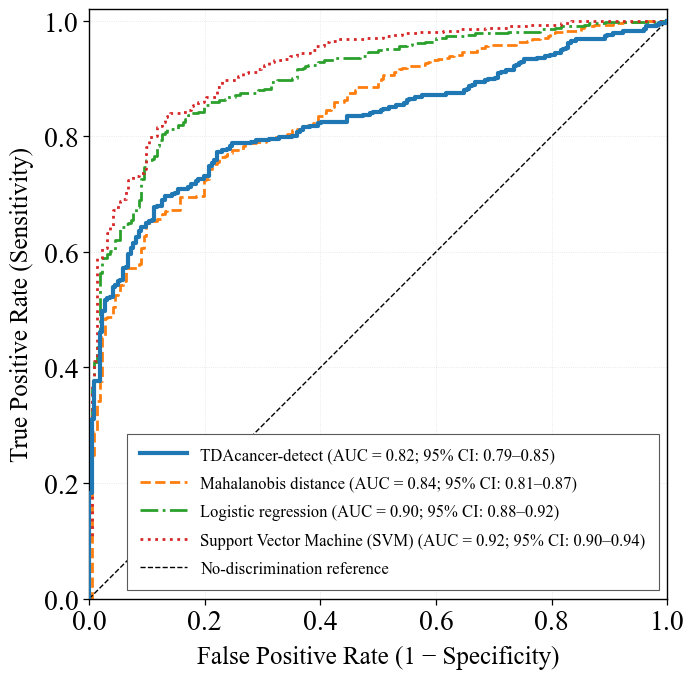


COMBINED ROC CURVE: TEST-SET RESULTS
                       Model Overall AUC (95% CI)  Partial AUC (FPR <= 0.15; raw)  Partial AUC (FPR <= 0.35; raw)  Sensitivity at 100% Specificity (%)  Patient-level AUC (diagnostic)  Absolute AUC difference (diagnostic)
            TDAcancer-detect     0.82 (0.79-0.85)                            0.09                            0.24                                18.23                            0.82                                   0.0
        Mahalanobis distance     0.84 (0.81-0.87)                            0.08                            0.23                                 0.00                            0.84                                   0.0
         Logistic regression     0.90 (0.88-0.92)                            0.10                            0.27                                25.12                            0.90                                   0.0
Support Vector Machine (SVM)     0.92 (0.90-0.94)                            0

In [14]:
"""
COMBINED ROC CURVE: TDAcancer-detect vs. Baseline Models

ROC curves and point AUC values:
    Uses the previously saved continuous ROC coordinates, exactly as in the
    supplied original code. No model retraining or threshold recalibration.

Additional statistics:
    1. Overall AUC with 95% stratified patient-level bootstrap CI.
       For TDA, both point AUC and CI use the saved "ROC Continuous Score".
    2. Raw partial AUC for FPR <= 0.15 and FPR <= 0.35
    3. Sensitivity at 100% specificity (FPR = 0)

Publication formatting:
    Clean Springer-style scientific figure with a larger, readable legend,
    serif typography, vector PDF, and 300-dpi TIFF/PNG outputs.

Important:
    A valid patient-level bootstrap confidence interval cannot be calculated
    from ROC coordinates alone. The script therefore uses patient-level
    TEST predictions only for the AUC confidence intervals. The plotted ROC
    curves, point AUCs, and partial AUCs are calculated from the saved ROC
    coordinates. A diagnostic AUC comparison is saved to help verify that
    the patient-level scores reproduce the saved ROC curve.
"""

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import auc, roc_curve


# ============================================================
# 1. USER SETTINGS
# ============================================================

INPUT_DIR = Path(
    r"D:\Cancer Detection folder\Biomarker Selection Dataset 1"
)

# Saved ROC-coordinate files
TDA_ROC_FILE = INPUT_DIR / "TDA_test_ROC_curve.csv"

MAHALANOBIS_FILE = INPUT_DIR / (
    "Mahalanobis_8Biomarker_Cancer_Detection_95pctSpecificity.xlsx"
)

LOGISTIC_FILE = INPUT_DIR / (
    "LogisticRegression_8Biomarker_Cancer_Detection_95pctSpecificity.xlsx"
)

SVM_FILE = INPUT_DIR / (
    "SVM_8Biomarker_Cancer_Detection_95pctSpecificity.xlsx"
)

# Patient-level TDA TEST predictions, used only for bootstrap CI
TDA_PREDICTIONS_FILE = INPUT_DIR / "TDA_test_predictions.csv"

PREDICTION_SHEET = "Test_Predictions"

N_BOOTSTRAP = 2000
RANDOM_SEED = 20261031
PARTIAL_FPR_VALUES = (0.15, 0.35)

# Outputs
OUTPUT_PNG = INPUT_DIR / "Combined_ROC_Curves_AUC_CI_pAUC_sens100.png"
OUTPUT_PDF = INPUT_DIR / "Combined_ROC_Curves_AUC_CI_pAUC_sens100.pdf"
OUTPUT_TIFF = INPUT_DIR / "Combined_ROC_Curves_AUC_CI_pAUC_sens100_300dpi.tiff"
OUTPUT_EXCEL = INPUT_DIR / "Combined_ROC_AUC_CI_pAUC_Summary_sens100.xlsx"
OUTPUT_COORDINATES_CSV = INPUT_DIR / "Combined_ROC_Coordinates_sens100.csv"
OUTPUT_STATISTICS_CSV = INPUT_DIR / "Combined_ROC_Statistics_sens100.csv"


# ============================================================
# 2. COMMON ROC DATA READER
# ============================================================

def validate_roc_data(df, model_name):

    required_columns = [
        "False Positive Rate",
        "True Positive Rate"
    ]

    missing = [
        col for col in required_columns
        if col not in df.columns
    ]

    if missing:
        raise ValueError(
            f"{model_name}: Missing ROC columns: {missing}. "
            f"Available columns: {list(df.columns)}"
        )

    fpr = pd.to_numeric(
        df["False Positive Rate"],
        errors="coerce"
    ).to_numpy(dtype=float)

    tpr = pd.to_numeric(
        df["True Positive Rate"],
        errors="coerce"
    ).to_numpy(dtype=float)

    if len(fpr) < 2 or len(tpr) < 2:
        raise ValueError(
            f"{model_name}: Insufficient ROC coordinates."
        )

    if len(fpr) != len(tpr):
        raise ValueError(
            f"{model_name}: FPR and TPR lengths differ."
        )

    if not (
        np.isfinite(fpr).all()
        and np.isfinite(tpr).all()
    ):
        raise ValueError(
            f"{model_name}: Non-finite ROC coordinates found."
        )

    if (
        (fpr < 0).any()
        or (fpr > 1).any()
        or (tpr < 0).any()
        or (tpr > 1).any()
    ):
        raise ValueError(
            f"{model_name}: ROC coordinates must lie between 0 and 1."
        )

    if np.any(np.diff(fpr) < -1e-12):
        raise ValueError(
            f"{model_name}: FPR coordinates are not in increasing order."
        )

    # Retain the supplied ROC coordinates without reconstructing the curve.
    model_auc = float(auc(fpr, tpr))

    return fpr, tpr, model_auc


# ============================================================
# 3. LOAD SAVED ROC CURVES
# ============================================================

def load_tda_roc():

    if not TDA_ROC_FILE.exists():
        raise FileNotFoundError(
            f"TDA ROC file not found:\n{TDA_ROC_FILE}"
        )

    df = pd.read_csv(TDA_ROC_FILE)

    return validate_roc_data(
        df,
        "TDAcancer-detect"
    )


def load_excel_roc(file_path, model_name):

    if not file_path.exists():
        raise FileNotFoundError(
            f"{model_name} results workbook not found:\n{file_path}"
        )

    df = pd.read_excel(
        file_path,
        sheet_name="Test_ROC_Curve"
    )

    return validate_roc_data(
        df,
        model_name
    )


# ============================================================
# 4. PARTIAL AUC FROM SAVED ROC COORDINATES
# ============================================================

def calculate_raw_partial_auc(fpr, tpr, max_fpr=0.15):
    """
    Calculate raw (unstandardized) partial AUC from FPR=0 to max_fpr.
    The endpoint at max_fpr is linearly interpolated.
    """

    fpr = np.asarray(fpr, dtype=float)
    tpr = np.asarray(tpr, dtype=float)

    order = np.argsort(fpr)
    x = fpr[order]
    y = tpr[order]

    # Keep all points strictly below the requested FPR limit.
    keep = x < max_fpr
    x_part = x[keep]
    y_part = y[keep]

    # Include FPR=0 if it is not already present.
    if len(x_part) == 0 or x_part[0] > 0:
        x_part = np.insert(x_part, 0, 0.0)
        y_part = np.insert(
            y_part, 0, float(np.interp(0.0, x, y))
        )

    # Include an interpolated endpoint exactly at the requested FPR limit.
    x_part = np.append(x_part, max_fpr)
    y_part = np.append(
        y_part, float(np.interp(max_fpr, x, y))
    )

    return float(np.trapz(y_part, x_part))



def calculate_sensitivity_at_100_specificity(fpr, tpr, tolerance=1e-12):
    """
    Sensitivity at 100% specificity, i.e. the maximum TPR attained
    at FPR = 0 on the supplied ROC coordinates.

    Returns sensitivity as a percentage (0-100).
    """
    fpr = np.asarray(fpr, dtype=float)
    tpr = np.asarray(tpr, dtype=float)

    zero_fpr = np.isclose(fpr, 0.0, atol=tolerance, rtol=0.0)

    if not np.any(zero_fpr):
        raise ValueError(
            "The saved ROC curve contains no FPR=0 coordinate; "
            "sensitivity at 100% specificity cannot be determined."
        )

    return float(np.max(tpr[zero_fpr]) * 100.0)



# ============================================================
# 5. PATIENT-LEVEL DATA FOR BOOTSTRAP AUC CONFIDENCE INTERVAL
# ============================================================

def find_column(df, candidates, model_name):

    normalized = {
        str(col).strip().casefold(): col
        for col in df.columns
    }

    for candidate in candidates:
        key = candidate.strip().casefold()
        if key in normalized:
            return normalized[key]

    raise ValueError(
        f"{model_name}: Could not find any of {candidates}. "
        f"Available columns: {list(df.columns)}"
    )


def convert_labels(series, model_name):
    """
    Convert binary labels or cohort names:
        Normal/Healthy -> 0
        Cancer cohort names -> 1
    """

    numeric = pd.to_numeric(series, errors="coerce")

    if numeric.notna().all() and set(
        numeric.unique()
    ).issubset({0, 1}):
        return numeric.astype(int).to_numpy()

    label_map = {
        "normal": 0,
        "healthy": 0,
        "control": 0,
        "negative": 0,
        "0": 0,
        "0.0": 0,

        "cancer": 1,
        "positive": 1,
        "case": 1,
        "1": 1,
        "1.0": 1,

        "bladder": 1,
        "bladder cancer": 1,
        "ovarian": 1,
        "ovary": 1,
        "ovarian cancer": 1,
        "pancreatic": 1,
        "pancreas": 1,
        "pancreatic cancer": 1,
        "breast": 1,
        "breast cancer": 1,
        "colorectal": 1,
        "colorectum": 1,
        "colon": 1,
        "esophageal": 1,
        "esophagus": 1,
        "oesophageal": 1,
        "oesophagus": 1,
        "liver": 1,
        "lung": 1,
        "prostate": 1,
        "stomach": 1,
        "gastric": 1,
    }

    normalized = (
        series.astype(str)
        .str.strip()
        .str.casefold()
    )

    mapped = normalized.map(label_map)

    if mapped.isna().any():
        bad = (
            series[mapped.isna()]
            .dropna()
            .astype(str)
            .unique()[:10]
        )

        raise ValueError(
            f"{model_name}: Unrecognized labels {bad}. "
            "Expected Normal/Healthy, binary 0/1, or cancer cohort names."
        )

    return mapped.astype(int).to_numpy()


def load_patient_predictions(
    file_path,
    model_name,
    score_candidates,
    csv_file=False
):

    if not file_path.exists():
        raise FileNotFoundError(
            f"Patient-level TEST predictions not found for {model_name}:\n"
            f"{file_path}\n\n"
            "A patient-level bootstrap confidence interval cannot be "
            "calculated from ROC coordinates alone. Provide one row per "
            "TEST patient with the true label and continuous prediction score."
        )

    if csv_file:
        df = pd.read_csv(file_path)
    else:
        df = pd.read_excel(
            file_path,
            sheet_name=PREDICTION_SHEET
        )

    label_col = find_column(
        df,
        [
            "True_Label_Binary",
            "True Label Binary",
            "True_Label",
            "True Label",
            "Actual_Label",
            "Actual Label",
            "Cohort",
            "Diagnosis",
            "Label"
        ],
        model_name
    )

    score_col = find_column(
        df,
        score_candidates,
        model_name
    )

    y = convert_labels(
        df[label_col],
        model_name
    )

    scores = pd.to_numeric(
        df[score_col],
        errors="coerce"
    ).to_numpy(dtype=float)

    valid = np.isfinite(scores)

    y = y[valid]
    scores = scores[valid]

    if len(np.unique(y)) != 2:
        raise ValueError(
            f"{model_name}: Patient-level TEST predictions must contain "
            "both cancer and normal patients."
        )

    return y, scores


# ============================================================
# 6. STRATIFIED PATIENT-LEVEL BOOTSTRAP AUC 95% CI
# ============================================================

def bootstrap_auc_ci(
    y,
    scores,
    n_bootstrap=2000,
    seed=20261031
):
    """
    Percentile 95% CI using class-stratified patient-level bootstrap.
    Cancer and normal patients are independently resampled with replacement.
    """

    rng = np.random.default_rng(seed)

    y = np.asarray(y, dtype=int)
    scores = np.asarray(scores, dtype=float)

    positive_indices = np.flatnonzero(y == 1)
    negative_indices = np.flatnonzero(y == 0)

    if (
        len(positive_indices) < 2
        or len(negative_indices) < 2
    ):
        raise ValueError(
            "At least two cancer and two normal TEST patients are required "
            "for bootstrap confidence intervals."
        )

    bootstrap_aucs = []

    for _ in range(n_bootstrap):

        sampled_positive = rng.choice(
            positive_indices,
            size=len(positive_indices),
            replace=True
        )

        sampled_negative = rng.choice(
            negative_indices,
            size=len(negative_indices),
            replace=True
        )

        sampled_indices = np.concatenate([
            sampled_positive,
            sampled_negative
        ])

        fpr_boot, tpr_boot, _ = roc_curve(
            y[sampled_indices],
            scores[sampled_indices],
            pos_label=1
        )

        bootstrap_aucs.append(
            auc(fpr_boot, tpr_boot)
        )

    ci_low, ci_high = np.percentile(
        bootstrap_aucs,
        [2.5, 97.5]
    )

    return float(ci_low), float(ci_high)


# ============================================================
# 7. LOAD ALL FOUR SAVED ROC CURVES
# ============================================================

roc_results = {}

roc_results["TDAcancer-detect"] = load_tda_roc()

roc_results["Mahalanobis distance"] = load_excel_roc(
    MAHALANOBIS_FILE,
    "Mahalanobis distance"
)

roc_results["Logistic regression"] = load_excel_roc(
    LOGISTIC_FILE,
    "Logistic regression"
)

roc_results["Support Vector Machine (SVM)"] = load_excel_roc(
    SVM_FILE,
    "Support Vector Machine"
)


# ============================================================
# 8. LOAD PATIENT-LEVEL TEST PREDICTIONS FOR AUC CI
# ============================================================

patient_predictions = {}

patient_predictions["TDAcancer-detect"] = load_patient_predictions(
    TDA_PREDICTIONS_FILE,
    "TDAcancer-detect",
    [
        # This is the exact continuous score used to generate TDA_test_ROC_curve.csv.
        # Do not substitute Positive Conditions Count (a discrete 0/1/2 score).
        "ROC Continuous Score"
    ],
    csv_file=True
)

patient_predictions["Mahalanobis distance"] = load_patient_predictions(
    MAHALANOBIS_FILE,
    "Mahalanobis distance",
    [
        "Mahalanobis_Distance",
        "Mahalanobis Distance",
        "Mahalanobis_Score",
        "Distance",
        "Prediction_Score",
        "Score"
    ]
)

patient_predictions["Logistic regression"] = load_patient_predictions(
    LOGISTIC_FILE,
    "Logistic regression",
    [
        "LogisticRegression_Cancer_Probability",
        "Cancer_Probability",
        "Predicted_Probability",
        "Probability",
        "Prediction_Score",
        "Score"
    ]
)

patient_predictions["Support Vector Machine (SVM)"] = load_patient_predictions(
    SVM_FILE,
    "Support Vector Machine (SVM)",
    [
        "SVM_Decision_Score",
        "Decision_Score",
        "SVM Score",
        "SVM_Score",
        "Prediction_Score",
        "Score"
    ]
)


# Check matching class counts across the patient-level TEST sets.
class_counts = {
    (
        int(np.sum(y == 1)),
        int(np.sum(y == 0))
    )
    for y, _ in patient_predictions.values()
}

if len(class_counts) != 1:
    raise ValueError(
        "The four methods do not have matching numbers of cancer and normal "
        "TEST patients. For a fair comparison, use the same independent "
        f"TEST cohort. Observed (cancer, normal) counts: {class_counts}"
    )


# ============================================================
# 9. CALCULATE AUC, 95% CI, AND PARTIAL AUC
# ============================================================

statistics_rows = []

for model_index, (model_name, (fpr, tpr, model_auc)) in enumerate(
    roc_results.items()
):

    y_patient, score_patient = patient_predictions[model_name]

    # Recalculate the point AUC directly from the same patient-level scores
    # used for the bootstrap CI. For TDA, score_patient is explicitly
    # "ROC Continuous Score", not the discrete Positive Conditions Count.
    patient_fpr, patient_tpr, _ = roc_curve(
        y_patient,
        score_patient,
        pos_label=1
    )
    patient_level_auc = float(auc(patient_fpr, patient_tpr))

    # The saved TDA ROC coordinates must reproduce the continuous-score AUC.
    # If they do not, stop rather than reporting a mismatched point estimate
    # and confidence interval.
    if model_name == "TDAcancer-detect":
        diagnostic_difference = abs(model_auc - patient_level_auc)
        if diagnostic_difference > 1e-8:
            raise ValueError(
                "TDA AUC mismatch: the saved TDA ROC coordinates give "
                f"{model_auc:.10f}, whereas patient-level ROC Continuous Score "
                f"gives {patient_level_auc:.10f}. Confirm that the ROC CSV and "
                "TDA_test_predictions.csv were generated by the same run."
            )
        model_auc = patient_level_auc

    ci_low, ci_high = bootstrap_auc_ci(
        y_patient,
        score_patient,
        n_bootstrap=N_BOOTSTRAP,
        seed=RANDOM_SEED + model_index
    )

    # Partial AUCs are calculated from the same saved ROC coordinates
    # that are used to draw the curves.
    partial_auc_015 = calculate_raw_partial_auc(
        fpr, tpr, max_fpr=0.15
    )
    partial_auc_035 = calculate_raw_partial_auc(
        fpr, tpr, max_fpr=0.35
    )

    sensitivity_at_100_spec = calculate_sensitivity_at_100_specificity(
        fpr, tpr
    )

    statistics_rows.append({
        "Model": model_name,
        "Overall AUC": model_auc,
        "AUC 95% CI Lower": ci_low,
        "AUC 95% CI Upper": ci_high,
        "Overall AUC (95% CI)": (
            f"{model_auc:.2f} ({ci_low:.2f}-{ci_high:.2f})"
        ),
        "Partial AUC (FPR <= 0.15; raw)": partial_auc_015,
        "Partial AUC (FPR <= 0.35; raw)": partial_auc_035,
        "Sensitivity at 100% Specificity (%)": sensitivity_at_100_spec,
        "Patient-level AUC (diagnostic)": patient_level_auc,
        "Absolute AUC difference (diagnostic)": abs(
            model_auc - patient_level_auc
        ),
        "Number of saved ROC coordinates": len(fpr),
        "Number of TEST patients": len(y_patient),
        "Bootstrap replicates": N_BOOTSTRAP
    })


statistics_df = pd.DataFrame(statistics_rows)

# Round reported statistics to two decimal places.
# Calculations and bootstrap resampling are performed at full precision.
statistics_df[
    [
        "Overall AUC",
        "AUC 95% CI Lower",
        "AUC 95% CI Upper",
        "Partial AUC (FPR <= 0.15; raw)",
        "Partial AUC (FPR <= 0.35; raw)",
        "Sensitivity at 100% Specificity (%)",
        "Patient-level AUC (diagnostic)",
        "Absolute AUC difference (diagnostic)"
    ]
] = statistics_df[
    [
        "Overall AUC",
        "AUC 95% CI Lower",
        "AUC 95% CI Upper",
        "Partial AUC (FPR <= 0.15; raw)",
        "Partial AUC (FPR <= 0.35; raw)",
        "Sensitivity at 100% Specificity (%)",
        "Patient-level AUC (diagnostic)",
        "Absolute AUC difference (diagnostic)"
    ]
].round(2)



# ============================================================
# 10. PREPARE ALL ORIGINAL ROC COORDINATES
# ============================================================

coordinate_tables = []

for model_name, (fpr, tpr, model_auc) in roc_results.items():

    coordinate_tables.append(
        pd.DataFrame({
            "Model": model_name,
            "False Positive Rate": fpr,
            "True Positive Rate": tpr
        })
    )


combined_coordinates = pd.concat(
    coordinate_tables,
    ignore_index=True
)


# ============================================================
# 11. GENERATE PUBLICATION-QUALITY COMBINED ROC FIGURE
# ============================================================

# A clean, journal-oriented style. The figure is saved as vector PDF and
# high-resolution raster formats for manuscript submission.
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.size": 20,
    "axes.labelsize": 18,
    "axes.titlesize": 22,
    "xtick.labelsize": 20,
    "ytick.labelsize": 20,
    "legend.fontsize": 15,
    "axes.linewidth": 1.0,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "savefig.facecolor": "white",
})

fig, ax = plt.subplots(figsize=(8.2, 7.2))

for model_name, (fpr, tpr, model_auc) in roc_results.items():

    stats_row = statistics_df.loc[
        statistics_df["Model"] == model_name
    ].iloc[0]

    # Show only overall AUC and its 95% CI in the figure legend.
    # Partial AUC values for FPR <= 0.15 and FPR <= 0.35 remain
    # calculated and are retained in the Excel/CSV statistical outputs.
    legend_label = (
        f"{model_name} "
        f"(AUC = {model_auc:.2f}; "
        f"95% CI: {stats_row['AUC 95% CI Lower']:.2f}–"
        f"{stats_row['AUC 95% CI Upper']:.2f})"
    )

    if model_name == "TDAcancer-detect":
        ax.plot(
            fpr, tpr,
            linewidth=3.0,
            linestyle="-",
            label=legend_label,
            zorder=5
        )

    elif model_name == "Mahalanobis distance":
        ax.plot(
            fpr, tpr,
            linewidth=2.0,
            linestyle="--",
            label=legend_label
        )

    elif model_name == "Logistic regression":
        ax.plot(
            fpr, tpr,
            linewidth=2.0,
            linestyle="-.",
            label=legend_label
        )

    elif model_name == "Support Vector Machine (SVM)":
        ax.plot(
            fpr, tpr,
            linewidth=2.0,
            linestyle=":",
            label=legend_label
        )

# No-discrimination reference
ax.plot(
    [0, 1], [0, 1],
    color="black",
    linestyle="--",
    linewidth=1.0,
    label="No-discrimination reference"
)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.set_xlabel("False Positive Rate (1 − Specificity)", labelpad=7)
ax.set_ylabel("True Positive Rate (Sensitivity)", labelpad=7)

# Avoid a redundant in-figure title; Springer figure captions are normally
# supplied separately in the manuscript.
ax.tick_params(axis="both", which="major", direction="out",
               length=4, width=0.9)
ax.grid(True, linestyle=":", linewidth=0.6, alpha=0.35)
ax.set_aspect("equal", adjustable="box")

# Larger legend text and adequate spacing. A two-column legend would make
# these long statistical labels difficult to read, so retain one column.
legend = ax.legend(
    loc="lower right",
    fontsize=12,
    frameon=True,
    fancybox=False,
    framealpha=1.0,
    edgecolor="0.35",
    borderpad=0.8,
    labelspacing=0.75,
    handlelength=2.8,
    handletextpad=0.8
)
legend.get_frame().set_linewidth(0.8)

fig.tight_layout()

fig.savefig(
    OUTPUT_PNG,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    OUTPUT_PDF,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    OUTPUT_TIFF,
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
    pil_kwargs={"compression": "tiff_lzw"}
)

plt.show()


# ============================================================
# 12. SAVE STATISTICS AND ROC COORDINATES
# ============================================================

with pd.ExcelWriter(
    OUTPUT_EXCEL,
    engine="openpyxl"
) as writer:

    statistics_df.to_excel(
        writer,
        sheet_name="ROC_Statistics",
        index=False
    )

    combined_coordinates.to_excel(
        writer,
        sheet_name="ROC_Coordinates",
        index=False
    )


combined_coordinates.to_csv(
    OUTPUT_COORDINATES_CSV,
    index=False
)

statistics_df.to_csv(
    OUTPUT_STATISTICS_CSV,
    index=False
)


# ============================================================
# 13. PRINT FINAL RESULTS
# ============================================================

print("\n==============================================")
print("COMBINED ROC CURVE: TEST-SET RESULTS")
print("==============================================")

print(
    statistics_df[
        [
            "Model",
            "Overall AUC (95% CI)",
            "Partial AUC (FPR <= 0.15; raw)",
            "Partial AUC (FPR <= 0.35; raw)",
            "Sensitivity at 100% Specificity (%)",
                "Patient-level AUC (diagnostic)",
            "Absolute AUC difference (diagnostic)"
        ]
    ].to_string(index=False)
)

print("\nSaved files:")
print("Combined ROC PNG:", OUTPUT_PNG)
print("Combined ROC PDF:", OUTPUT_PDF)
print("Combined ROC TIFF (300 dpi):", OUTPUT_TIFF)
print("AUC and pAUC statistics Excel:", OUTPUT_EXCEL)
print("Combined ROC coordinates CSV:", OUTPUT_COORDINATES_CSV)
print("Statistics CSV:", OUTPUT_STATISTICS_CSV)

print("\nAll four saved ROC curves have been combined.")

print(
    "\nIMPORTANT: Overall AUC and partial AUC in the figure are calculated "
    "from the original saved ROC coordinates. The 95% AUC confidence "
    "intervals are calculated by stratified patient-level bootstrap. "
    "Check the diagnostic AUC differences: large differences indicate "
    "that the patient-level score columns do not reproduce the saved "
    "ROC curves, and the score columns should be verified before reporting."
)

In [15]:
# Stability of Model Performance Across 100 Random Data Partitions

In [16]:
"""
Repeated random-split evaluation of the TDAcancer_detect detection rule.

Purpose
-------
Generate reproducible patient-level random splits in memory, evaluate the
predefined TDA-based detection rule on each Test partition, and summarize
performance across successful repetitions. No separate split workbooks or
CSV files are created. The script writes a main Excel workbook containing
split-level results and summary statistics, plus a separate workbook with
the compact mean-performance table.

Patient partitioning
--------------------
- The first N_REFERENCE_NORMAL patients in the Normal cohort, in source-row
  order, form the fixed Reference group in every repetition.
- The remaining Normal patients are shuffled and allocated to Regression Fit
  Calibration 1, Biomarker-Panel Calibration and Selection, and Test according
  to CALIBRATION1_FRACTION and CALIBRATION2_FRACTION; Test receives the remainder.
- Patients in each cancer cohort listed in COHORT_ORDER are shuffled and
  allocated to Calibration 2 and Test according to CALIBRATION2_FRACTION.
- Cancer patients are not assigned to Calibration 1.

Detection procedure
-------------------
For each repetition, the fixed Reference group is used to construct TDA
features for Calibration 1 Normal patients and Test patients. A linear
regression model is fitted using Calibration 1 Normal patients only. The
predefined thresholds K1 and K2 are applied to Test without recalibration,
using the OR decision rule:

    Positive if Regression Difference Percentage > K1
    OR Distance %(1) > K2.

Performance is reported for overall cancer sensitivity, normal specificity,
and cancer sensitivity stratified by AJCC stage.

Across-repetition summaries
---------------------------
The summary reports descriptive means, standard deviations, medians, minima,
maxima, and 95% t-based confidence intervals for split-level performance.
It also reports mean split-level numerators and denominators and the mean
within-split Wilson confidence-interval limits. These are summaries across
randomized repetitions, not pooled patient-level estimates.

Configuration
-------------
Update the input/output paths, biomarker names, cohort labels, split settings,
and fixed thresholds as required for the dataset and analysis.
"""
from pathlib import Path
import numpy as np
import pandas as pd
import gudhi
from scipy.stats import t
from sklearn.linear_model import LinearRegression


# =============================================================================
# USER-DEFINED SETTINGS
# =============================================================================
INPUT_FILE = Path(r"D:\Cancer Detection folder\Biomarker Selection Dataset 1\clinical cancer data.xlsx")
SHEET_NAME = "Normal and Cancer"
OUTPUT_FILE = Path(r"D:\Cancer Detection folder\Biomarker Selection Dataset 1\TDAcancer_detect_Random_Split_Performance.xlsx")
FINAL_MEAN_OUTPUT_FILE = OUTPUT_FILE.parent / "TDAcancer_detect_Final_Mean_Performance.xlsx"

N_REPETITIONS = 100
RANDOM_SEED = 20261022
N_REFERENCE_NORMAL = 59
CALIBRATION1_FRACTION = 0.10
CALIBRATION2_FRACTION = 0.60

BIOMARKERS = [
    "Angiopoietin-2",
    "CA-125",
    "CA19-9",
    "HGF",
    "IL-6",
    "OPN",
    "Prolactin",
    "SHBG",
    "sHER2/sEGFR2/sErbB2",
    "Thrombospondin-2",
]
K1, K2 = 0.982129313495, 4.832165197

COHORT_COL = "Cohort"
PATIENT_ID_COL = "Patient ID #"
STAGE_COL = "AJCC Stage"
DATA_TYPE_COL = "Data Type"
SOURCE_ROW_COL = "Original_Source_Row_Zero_Based"
NORMAL_COHORT = "normal"
COHORT_ORDER = {"normal": 0, "breast": 1, "colorectum": 2, "esophagus": 3, "liver": 4, "lung": 5, "ovary": 6, "pancreas": 7, "stomach": 8}
ROLE_REFERENCE = "Reference"
ROLE_CAL1 = "Regression Fit Calibration 1"
ROLE_CAL2 = "Biomarker-Panel Calibration and Selection"
ROLE_TEST = "Test"
ROLE_ORDER = {ROLE_REFERENCE: 0, ROLE_CAL1: 1, ROLE_CAL2: 2, ROLE_TEST: 3}


# =============================================================================
# VALIDATION AND RANDOM SPLITS
# =============================================================================
def cohort_key(series):
    return series.astype(str).str.strip().str.casefold()


def validate_settings():
    if not isinstance(N_REPETITIONS, int) or N_REPETITIONS < 1:
        raise ValueError("N_REPETITIONS must be a positive integer.")
    for name, value in (("CALIBRATION1_FRACTION", CALIBRATION1_FRACTION),
                        ("CALIBRATION2_FRACTION", CALIBRATION2_FRACTION)):
        if not isinstance(value, (int, float)) or not np.isfinite(value) or not 0 <= value <= 1:
            raise ValueError(f"{name} must be a finite number between 0 and 1.")
    if CALIBRATION1_FRACTION + CALIBRATION2_FRACTION >= 1:
        raise ValueError("Calibration 1 + Calibration 2 fractions must be less than 1.")


def create_one_split(source_df, rng, repetition):
    """Create one reproducible split while retaining every source patient exactly once."""
    df = source_df.copy().reset_index(drop=True)
    df[SOURCE_ROW_COL] = np.arange(len(df), dtype=int)
    cohort = cohort_key(df[COHORT_COL])
    normal_indices = df.index[cohort.eq(NORMAL_COHORT)].tolist()
    if len(normal_indices) <= N_REFERENCE_NORMAL:
        raise ValueError(f"Need more than {N_REFERENCE_NORMAL} Normal patients; found {len(normal_indices)}.")

    roles = {}
    for idx in normal_indices[:N_REFERENCE_NORMAL]:
        roles[idx] = ROLE_REFERENCE

    remaining_normals = normal_indices[N_REFERENCE_NORMAL:].copy()
    rng.shuffle(remaining_normals)
    n_cal1 = int(np.floor(len(remaining_normals) * CALIBRATION1_FRACTION))
    n_cal2_normal = int(np.floor(len(remaining_normals) * CALIBRATION2_FRACTION))
    for idx in remaining_normals[:n_cal1]:
        roles[idx] = ROLE_CAL1
    for idx in remaining_normals[n_cal1:n_cal1 + n_cal2_normal]:
        roles[idx] = ROLE_CAL2
    for idx in remaining_normals[n_cal1 + n_cal2_normal:]:
        roles[idx] = ROLE_TEST

    for cancer in [c for c in COHORT_ORDER if c != NORMAL_COHORT]:
        indices = df.index[cohort.eq(cancer)].tolist()
        if not indices:
            raise ValueError(f"No rows found for cancer cohort {cancer!r}; check COHORT_ORDER.")
        shuffled = indices.copy()
        rng.shuffle(shuffled)
        n_cal2 = int(np.floor(len(shuffled) * CALIBRATION2_FRACTION))
        for idx in shuffled[:n_cal2]:
            roles[idx] = ROLE_CAL2
        for idx in shuffled[n_cal2:]:
            roles[idx] = ROLE_TEST

    missing = [idx for idx in df.index if idx not in roles]
    if missing:
        unknown = sorted(set(cohort.loc[missing].tolist()))
        raise ValueError(f"Some rows were not assigned a role. Unrecognized cohorts: {unknown}")

    df[DATA_TYPE_COL] = pd.Series(roles)
    df["_role_order"] = df[DATA_TYPE_COL].map(ROLE_ORDER)
    df["_cohort_order"] = cohort.map(COHORT_ORDER).fillna(999).astype(int)
    df = df.sort_values(["_role_order", "_cohort_order", SOURCE_ROW_COL], kind="stable")
    df = df.drop(columns=["_role_order", "_cohort_order"]).reset_index(drop=True)

    if len(df) != len(source_df) or df[SOURCE_ROW_COL].duplicated().any() or set(df[SOURCE_ROW_COL]) != set(range(len(source_df))):
        raise RuntimeError(f"Split {repetition}: source rows are missing or duplicated.")
    return df


# =============================================================================
# TDA FEATURE EXTRACTION AND TEST-SET PERFORMANCE
# =============================================================================
def wilson_ci(successes, total, z=1.959963984540054):
    if total <= 0:
        return np.nan, np.nan
    p = successes / total
    den = 1 + z * z / total
    centre = (p + z * z / (2 * total)) / den
    half = z * np.sqrt(p * (1 - p) / total + z * z / (4 * total * total)) / den
    return max(0.0, centre - half), min(1.0, centre + half)


def numeric_values(frame, cols, label):
    x = frame[cols].apply(pd.to_numeric, errors="coerce")
    if not np.isfinite(x.to_numpy(dtype=float)).all():
        raise ValueError(f"Missing/non-finite biomarker values in {label}.")
    return x.to_numpy(dtype=float)


def tda_features(reference_values, patient_values):
    combined = np.vstack([reference_values, patient_values.reshape(1, -1)])
    if (combined <= 0).any():
        raise ValueError("Log transform requires strictly positive biomarker values.")
    corr = np.corrcoef(np.log(combined), rowvar=False)
    if not np.isfinite(corr).all():
        raise ValueError("Non-finite correlation matrix; check constant biomarkers.")
    dissimilarity_matrix = np.clip(1 - np.abs(corr), 0.0, 1.0)
    dissimilarity_matrix = (dissimilarity_matrix + dissimilarity_matrix.T) / 2.0
    np.fill_diagonal(dissimilarity_matrix, 0.0)
    simplex_tree = gudhi.RipsComplex(distance_matrix=dissimilarity_matrix).create_simplex_tree(max_dimension=2)
    persistence = simplex_tree.persistence()
    finite = [(dim, pair) for dim, pair in persistence if np.isfinite(pair[1])]
    h0 = [pair for dim, pair in finite if dim == 0]
    h1 = [pair for dim, pair in finite if dim == 1]
    deaths0 = [death for _, death in h0]
    lives0 = [death - birth for birth, death in h0]
    births1 = [birth for birth, _ in h1]
    deaths1 = [death for _, death in h1]
    return {
        "0-Dim Hole Min Life Range": min(lives0, default=0.0),
        "0-Dim Hole Max Life Range": max(lives0, default=0.0),
        "Median_Death_0D": float(np.median(deaths0)) if deaths0 else 0.0,
        "Std_Death_0D": float(np.std(deaths0)) if deaths0 else 0.0,
        "Avg_Death_0D": float(np.mean(deaths0)) if deaths0 else 0.0,
        "Average Birth (1D)": float(np.mean(births1)) if births1 else 0.0,
        "Average Death (1D)": float(np.mean(deaths1)) if deaths1 else 0.0,
    }


def add_metric_record(rows, split_id, scope, group, metric, successes, total, **extras):
    lo, hi = wilson_ci(successes, total)
    rows.append({
        "Split": split_id, "Scope": scope, "Group": group, "Metric": metric,
        "Numerator": int(successes), "Denominator": int(total),
        "Value (%)": 100.0 * successes / total if total else np.nan,
        "Within-split Wilson 95% CI Lower (%)": 100 * lo,
        "Within-split Wilson 95% CI Upper (%)": 100 * hi,
        **extras,
    })


def evaluate_split(df, split_id):
    required = [DATA_TYPE_COL, COHORT_COL, STAGE_COL, PATIENT_ID_COL, *BIOMARKERS]
    missing = [col for col in required if col not in df.columns]
    if missing:
        raise ValueError(f"Missing columns: {missing}")
    df = df.copy()
    df[DATA_TYPE_COL] = df[DATA_TYPE_COL].astype(str).str.strip()
    df[COHORT_COL] = df[COHORT_COL].astype(str).str.strip()
    ckey = cohort_key(df[COHORT_COL])
    normal_indices = df.index[ckey.eq(NORMAL_COHORT)].tolist()
    if SOURCE_ROW_COL in df.columns:
        source_rows = pd.to_numeric(df[SOURCE_ROW_COL], errors="coerce")
        normal_indices.sort(key=lambda idx: source_rows.loc[idx])
    if len(normal_indices) < N_REFERENCE_NORMAL:
        raise ValueError(f"Only {len(normal_indices)} Normal patients; need {N_REFERENCE_NORMAL}.")
    reference_indices = normal_indices[:N_REFERENCE_NORMAL]
    reference_values = numeric_values(df.loc[reference_indices], BIOMARKERS, "fixed Reference group")

    cal1 = df[df[DATA_TYPE_COL].eq(ROLE_CAL1) & ckey.eq(NORMAL_COHORT) & ~df.index.isin(reference_indices)]
    test = df[df[DATA_TYPE_COL].eq(ROLE_TEST)].copy()
    if len(cal1) < 2:
        raise ValueError(f"Need at least 2 Calibration 1 Normal patients; found {len(cal1)}.")
    if test.empty:
        raise ValueError("No rows labelled Test.")

    # Calculate TDA features only for Calibration 1 normal patients and Test patients.
    feature_map = {}
    for idx in list(cal1.index) + list(test.index):
        values = numeric_values(df.loc[[idx]], BIOMARKERS, f"split {split_id}, row {idx}")[0]
        feature_map[idx] = tda_features(reference_values, values)
    cal1_features = pd.DataFrame.from_dict(feature_map, orient="index").loc[cal1.index]
    test_features = pd.DataFrame.from_dict(feature_map, orient="index").loc[test.index]

    predictors = ["0-Dim Hole Min Life Range", "0-Dim Hole Max Life Range", "Median_Death_0D", "Std_Death_0D"]
    regression = LinearRegression().fit(cal1_features[predictors], cal1_features["Avg_Death_0D"])
    ev = pd.concat([test[[COHORT_COL, STAGE_COL, PATIENT_ID_COL]], test_features], axis=1)
    ev["Predicted Avg_Death_0D"] = regression.predict(ev[predictors])
    ev["Difference"] = ev["Avg_Death_0D"] - ev["Predicted Avg_Death_0D"]
    denominator = ev["Avg_Death_0D"].abs().replace(0, np.nan)
    ev["Regression Difference Percentage"] = ev["Difference"].abs() / denominator * 100
    reference_birth = cal1_features["Average Birth (1D)"].mean()
    reference_death = cal1_features["Average Death (1D)"].mean()
    ev["Distance %(1)"] = np.sqrt(
        (ev["Average Birth (1D)"] - reference_birth) ** 2
        + (ev["Average Death (1D)"] - reference_death) ** 2
    ) * 100

    predicted_cancer = (
        (ev["Regression Difference Percentage"] > K1)
        | (ev["Distance %(1)"] > K2)
    )
    actual_cancer = ~ev[COHORT_COL].astype(str).str.casefold().eq(NORMAL_COHORT)
    actual_normal = ~actual_cancer
    cancer_tp = int((predicted_cancer & actual_cancer).sum())
    cancer_n = int(actual_cancer.sum())
    normal_tn = int((~predicted_cancer & actual_normal).sum())
    normal_n = int(actual_normal.sum())
    test_n = len(ev)

    rows = []
    common = {"Test N": test_n, "Cancer N": cancer_n, "Normal N": normal_n,
              "Cancer TP": cancer_tp, "Normal TN": normal_tn}
    add_metric_record(rows, split_id, "Overall", "All cancer types", "Sensitivity", cancer_tp, cancer_n, **common)
    add_metric_record(rows, split_id, "Overall", "Normal patients", "Specificity", normal_tn, normal_n, **common)

    stages = ev[STAGE_COL].fillna("Unknown").astype(str).str.strip()
    for stage in sorted(stages[actual_cancer].unique()):
        mask = stages.eq(stage) & actual_cancer
        stage_n = int(mask.sum())
        stage_tp = int(predicted_cancer[mask].sum())
        add_metric_record(rows, split_id, "Stage-wise", f"All cancer types | Stage {stage}",
                          "Sensitivity", stage_tp, stage_n, **common)
    return rows


# =============================================================================
# SUMMARY ACROSS RANDOMIZED SPLITS
# =============================================================================
def summarize_splits(each):
    rows = []
    for (scope, group, metric), frame in each.groupby(["Scope", "Group", "Metric"], dropna=False, sort=True):
        vals = pd.to_numeric(frame["Value (%)"], errors="coerce").dropna()
        # Summarize split-level numerators and denominators descriptively. Each
        # repetition is a separate randomized split; these are not pooled counts.
        nums = pd.to_numeric(frame["Numerator"], errors="coerce").dropna()
        dens = pd.to_numeric(frame["Denominator"], errors="coerce").dropna()
        n = len(vals)
        mean = vals.mean() if n else np.nan
        sd = vals.std(ddof=1) if n > 1 else np.nan
        half = t.ppf(0.975, n - 1) * sd / np.sqrt(n) if n > 1 else np.nan
        rows.append({
            "Scope": scope, "Group": group, "Metric": metric,
            "Number of successful splits": int(frame["Split"].nunique()),
            "Mean numerator": nums.mean() if len(nums) else np.nan,
            "SD numerator": nums.std(ddof=1) if len(nums) > 1 else np.nan,
            "Mean denominator": dens.mean() if len(dens) else np.nan,
            "SD denominator": dens.std(ddof=1) if len(dens) > 1 else np.nan,
            "Mean performance (%)": mean, "SD performance (%)": sd,
            "Median performance (%)": vals.median() if n else np.nan,
            "Minimum performance (%)": vals.min() if n else np.nan,
            "Maximum performance (%)": vals.max() if n else np.nan,
            "Across-split 95% t-CI Lower (%)": mean - half if n > 1 else np.nan,
            "Across-split 95% t-CI Upper (%)": mean + half if n > 1 else np.nan,
            "Mean within-split Wilson CI Lower (%)": pd.to_numeric(frame["Within-split Wilson 95% CI Lower (%)"], errors="coerce").mean(),
            "Mean within-split Wilson CI Upper (%)": pd.to_numeric(frame["Within-split Wilson 95% CI Upper (%)"], errors="coerce").mean(),
        })
    return pd.DataFrame(rows)


def main():
    validate_settings()
    if not INPUT_FILE.exists():
        raise FileNotFoundError(f"Input workbook not found: {INPUT_FILE}\nUpdate INPUT_FILE in the settings.")
    sheets = pd.read_excel(INPUT_FILE, sheet_name=None)
    if SHEET_NAME not in sheets:
        raise ValueError(f"Sheet {SHEET_NAME!r} not found. Available sheets: {list(sheets)}")
    source_df = sheets[SHEET_NAME].copy()
    required = [COHORT_COL, PATIENT_ID_COL, STAGE_COL, *BIOMARKERS]
    missing = [col for col in required if col not in source_df.columns]
    if missing:
        raise ValueError(f"Missing required columns in source sheet: {missing}")
    if DATA_TYPE_COL in source_df.columns:
        source_df = source_df.drop(columns=[DATA_TYPE_COL])
    if SOURCE_ROW_COL in source_df.columns:
        source_df = source_df.drop(columns=[SOURCE_ROW_COL])
    source_df = source_df.reset_index(drop=True)

    observed = set(cohort_key(source_df[COHORT_COL]).unique())
    expected = set(COHORT_ORDER)
    unexpected = observed - expected
    if unexpected:
        raise ValueError(f"Unexpected cohort names: {sorted(unexpected)}. Update COHORT_ORDER if intended.")
    n_normal = int(cohort_key(source_df[COHORT_COL]).eq(NORMAL_COHORT).sum())
    if n_normal <= N_REFERENCE_NORMAL:
        raise ValueError(f"Need more than {N_REFERENCE_NORMAL} Normal patients; found {n_normal}.")

    rng = np.random.RandomState(RANDOM_SEED)
    all_records, failures = [], []
    for split_id in range(1, N_REPETITIONS + 1):
        try:
            split_df = create_one_split(source_df, rng, split_id)
            records = evaluate_split(split_df, split_id)
            all_records.extend(records)
            print(f"\nSplit {split_id}/{N_REPETITIONS}")
            for row in records:
                print(f"  {row['Scope']} | {row['Group']} | {row['Metric']}: "
                      f"{row['Numerator']}/{row['Denominator']} = {row['Value (%)']:.2f}%")
        except Exception as exc:
            failures.append({"Split": split_id, "Error": f"{type(exc).__name__}: {exc}"})
            print(f"\nSplit {split_id}/{N_REPETITIONS} FAILED: {type(exc).__name__}: {exc}")

    if not all_records:
        raise RuntimeError("No splits were evaluated successfully. Check the input data and error messages.")
    each = pd.DataFrame(all_records)
    summary = summarize_splits(each)
    split_status = pd.DataFrame({
        "Requested splits": [N_REPETITIONS],
        "Successful splits": [int(each["Split"].nunique())],
        "Failed splits": [len(failures)],
        "Random seed": [RANDOM_SEED],
        "Fixed reference normals": [N_REFERENCE_NORMAL],
        "Normal Calibration 1 fraction (after Reference)": [CALIBRATION1_FRACTION],
        "Normal Calibration 2 fraction (after Reference)": [CALIBRATION2_FRACTION],
        "Cancer Calibration 2 fraction (within each cancer cohort)": [CALIBRATION2_FRACTION],
        "Threshold k1": [K1], "Threshold k2": [K2],
    })
    failures_df = pd.DataFrame(failures, columns=["Split", "Error"])

    OUTPUT_FILE.parent.mkdir(parents=True, exist_ok=True)

    # Main workbook: split-level results, across-split summaries, run settings,
# and failure details when one or more repetitions could not be evaluated.
    with pd.ExcelWriter(OUTPUT_FILE, engine="openpyxl") as writer:
        each.to_excel(writer, sheet_name="Each Split Performance", index=False)
        summary.to_excel(writer, sheet_name="Mean Performance Summary", index=False)
        split_status.to_excel(writer, sheet_name="Run Settings", index=False)
        if not failures_df.empty:
            failures_df.to_excel(writer, sheet_name="Failed Splits", index=False)

    # Separate results workbook containing the compact mean-performance table.
    display_cols = ["Scope", "Group", "Metric", "Number of successful splits",
                    "Mean numerator", "Mean denominator", "Mean performance (%)",
                    "SD performance (%)", "Across-split 95% t-CI Lower (%)",
                    "Across-split 95% t-CI Upper (%)"]
    final_mean_results = summary[display_cols].copy()
    with pd.ExcelWriter(FINAL_MEAN_OUTPUT_FILE, engine="openpyxl") as writer:
        final_mean_results.to_excel(writer, sheet_name="Final Mean Performance", index=False)
        split_status.to_excel(writer, sheet_name="Run Settings", index=False)
        if not failures_df.empty:
            failures_df.to_excel(writer, sheet_name="Failed Splits", index=False)

    print("\nFINAL MEAN PERFORMANCE ACROSS SUCCESSFUL SPLITS")
    print(final_mean_results.to_string(index=False, float_format=lambda x: f"{x:.2f}"))
    print(f"\nSaved main performance workbook: {OUTPUT_FILE}")
    print(f"Saved separate final mean-performance workbook: {FINAL_MEAN_OUTPUT_FILE}")
    print(f"Successful splits: {each['Split'].nunique()}/{N_REPETITIONS}; failed splits: {len(failures)}")


if __name__ == "__main__":
    main()



Split 1/100
  Overall | All cancer types | Sensitivity: 201/406 = 49.51%
  Overall | Normal patients | Specificity: 214/222 = 96.40%
  Stage-wise | All cancer types | Stage I | Sensitivity: 31/84 = 36.90%
  Stage-wise | All cancer types | Stage II | Sensitivity: 107/208 = 51.44%
  Stage-wise | All cancer types | Stage III | Sensitivity: 63/114 = 55.26%

Split 2/100
  Overall | All cancer types | Sensitivity: 203/406 = 50.00%
  Overall | Normal patients | Specificity: 207/222 = 93.24%
  Stage-wise | All cancer types | Stage I | Sensitivity: 34/84 = 40.48%
  Stage-wise | All cancer types | Stage II | Sensitivity: 106/203 = 52.22%
  Stage-wise | All cancer types | Stage III | Sensitivity: 63/119 = 52.94%

Split 3/100
  Overall | All cancer types | Sensitivity: 195/406 = 48.03%
  Overall | Normal patients | Specificity: 213/222 = 95.95%
  Stage-wise | All cancer types | Stage I | Sensitivity: 31/84 = 36.90%
  Stage-wise | All cancer types | Stage II | Sensitivity: 92/196 = 46.94%
  Stage-